# A Closed-Form Bending–Drag Trade Law for Wings, and a Wingtip Retrofit for the Penguin BE UAV

**Manthan Rana** · Independent Researcher, Mumbai, India · ORCID: [0000-0000-0000-0000](https://orcid.org/0000-0000-0000-0000)

[![DOI](https://zenodo.org/badge/DOI/10.5281/zenodo.XXXXXXX.svg)](https://doi.org/10.5281/zenodo.XXXXXXX)
**Paper (preprint):** engrXiv, DOI pending · **Code:** [github.com/Manthonix/penguin-be-wingtip-retrofit](https://github.com/Manthonix/penguin-be-wingtip-retrofit) · **Theory repo:** [wing-loading-tradeoff](https://github.com/Manthonix/wing-loading-tradeoff)

---

A longer wing makes less induced drag, but it puts lift further from the root and bends the structure harder. On an aircraft that is already built, the structure is fixed, so the useful question is how much span the existing bending capacity can buy. This notebook answers that in two parts.

**Part A: theory.** Using Prandtl's lifting-line theory with a Fourier sine series for the circulation, the least induced-drag penalty for holding a bending measure with moment arm $|y|^k$ to a fraction $f$ of its elliptical value is

$$\frac{C_{D,i}}{C_{D,i,\mathrm{ell}}} = 1 + c(k)\,(1-f)^2, \qquad c(k) = \frac{4(1+k)}{k^2}.$$

It is verified two independent ways: a 151-harmonic optimiser, and direct summation of the series. Root bending ($k=1$) gives $c = 8$, and integrated bending ($k=2$) gives $c = 3$. The span optimum $f^* = (2+k)/(2(1+k))$ reproduces the classical results of Jones and of Prandtl as special cases.

**Part B: application.** The theory is applied to a bolt-on wingtip extension for the Penguin BE survey UAV. The ailerons are scheduled to relieve load at high g, and the original wing's own worst-case bending is used as the structural limit. Three stages:

| Stage | Method | Designs | Feasible |
|---|---|---|---|
| 1 | Lifting line, 8 CS-LUAS load cases | 4,890 | 1,732 |
| 2 | Vortex lattice (AeroSandbox) at +3.8 g | 4,890 | 1,437 (295 rejected) |
| 3 | Viscous drag (AeroBuildup) | baseline + finalists | drag order confirmed |

**Recommended wing, W2:** +206 mm per tip (span 3.30 → 3.71 m), −4° washout, alleviation gain 7.5°/g, +217 g.
- Induced drag: −21.1% by lifting line (−20.6% by vortex lattice)
- Cruise endurance: +4.3% (viscous) to +5.9% (lifting line); loiter endurance: +10.2% (lifting line)
- Root and joiner bending at 3.8 g: 0.978 and 0.977 of the original rating (vortex lattice)

**How to run.** Run all cells in order: cell 0 installs packages, and cells 6–12 write the model files into `wingstudy/`. Stage 1 takes about a minute per scenario. Stage 2 (cell 16) takes about 1 hour on a Kaggle CPU. It saves progress every 50 wings and resumes if interrupted. To skip it, put `vlm_screen_raw.csv` from the repository's `results/` folder into `wingstudy/results/`. Outputs go to `wingstudy/results/` (CSV, JSON) and `wingstudy/figures/` (PNG, 300 dpi).

**Main assumptions.** Linear taper approximating the real planform; NACA 2412 sections; rigid wing; aileron modelled as twist (τ = 0.5); instantaneous alleviation; whole-aircraft L/D = 18 (tested at 15 and 20). No physical tests have been run yet.

**AI use.** Claude (Anthropic) was used for help with code, figures and editing. All derivations, code and results were checked and run by the author, who takes full responsibility for them.

**Licence.** Code: MIT. Data and figures: CC BY 4.0.

## 0. Setup: install packages and print versions

In [1]:
!pip install -q --no-deps aerosandbox neuralfoil casadi sortedcontainers dill
import os, sys
from importlib.metadata import version
os.makedirs("wingstudy", exist_ok=True)
# every %%writefile cell below writes into this folder

print("python", sys.version.split()[0])
for pkg in ("numpy", "scipy", "matplotlib", "aerosandbox", "neuralfoil"):
    print(pkg, version(pkg))

for pkg in ("numpy", "scipy", "matplotlib", "aerosandbox", "neuralfoil"):
    try:
        print(pkg, version(pkg))
    except Exception:
        print(pkg, "NOT INSTALLED: check that Internet is on in Settings")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 54.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 75.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.2/93.2 MB 18.6 MB/s eta 0:00:00
python 3.13.15
numpy 2.1.3
scipy 1.16.3
matplotlib 3.10.0
aerosandbox 4.2.10
neuralfoil 0.3.3
numpy 2.1.3
scipy 1.16.3
matplotlib 3.10.0
aerosandbox 4.2.10
neuralfoil 0.3.3


### Part A: Theory

## 1. Least-drag loading at fixed bending: optimiser, Prandtl's bell and the trade law for k = 1 and 2

bell, two constructions agree to: 4.44e-16
C_L elliptical: 25.132741   C_L bell: 25.132741
C_Di ratio, bell over elliptical: 1.333333
I_1 =  0.333333
I_3 =  0.200000
I_5 = -0.047619
I_7 =  0.022222
K_1 =  1.963495e-01
K_3 =  1.963495e-01
K_5 = -3.469447e-18
K_7 =  0.000000e+00
K_9 = -6.938894e-18
K_11 =  3.469447e-18
closed form for I_n confirmed against numerical integration
bending ratio, bell over elliptical: 0.800000
root optimum at f=0.80, bending ratio: 0.800000
root optimum at f=0.80, drag ratio:    1.320727
f = 0.9000   A_3/A_1 = -0.100000
f = 0.6667   A_3/A_1 = -0.333333
f = 0.5000   A_3/A_1 = -0.500000

ROOT bending constraint
     f   C_Di ratio    A_3/A_1   bending         e
  1.00     1.000000   0.000000    1.0000    1.0000
  0.99     1.000802  -0.016036    0.9900    0.9992
  0.98     1.003207  -0.032073    0.9800    0.9968
  0.97     1.007216  -0.048109    0.9700    0.9928
  0.96     1.012829  -0.064145    0.9600    0.9873
  0.95     1.020045  -0.080182    0.9500    0.980

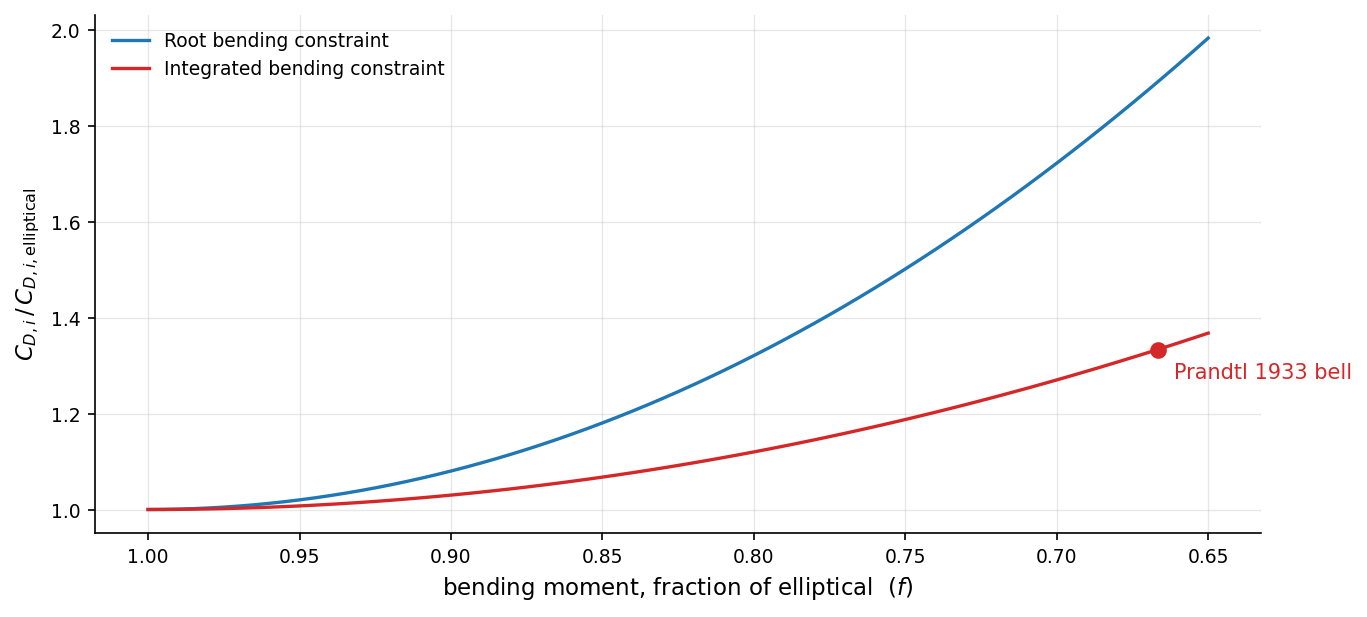

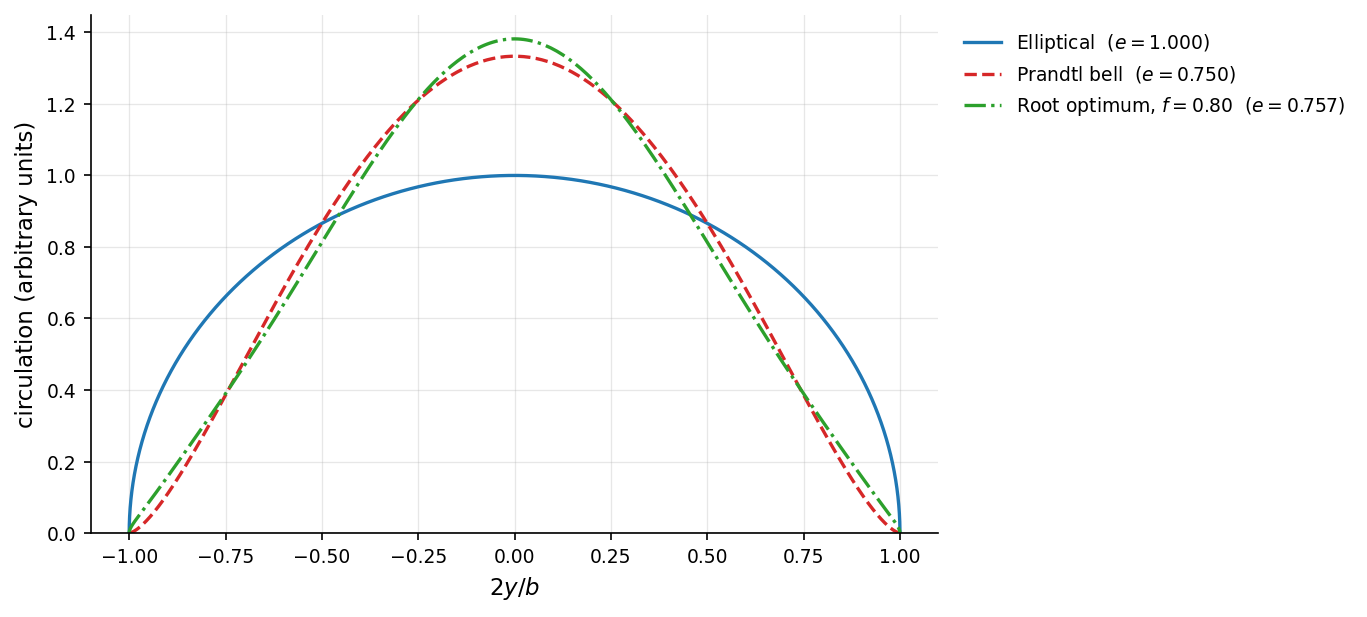

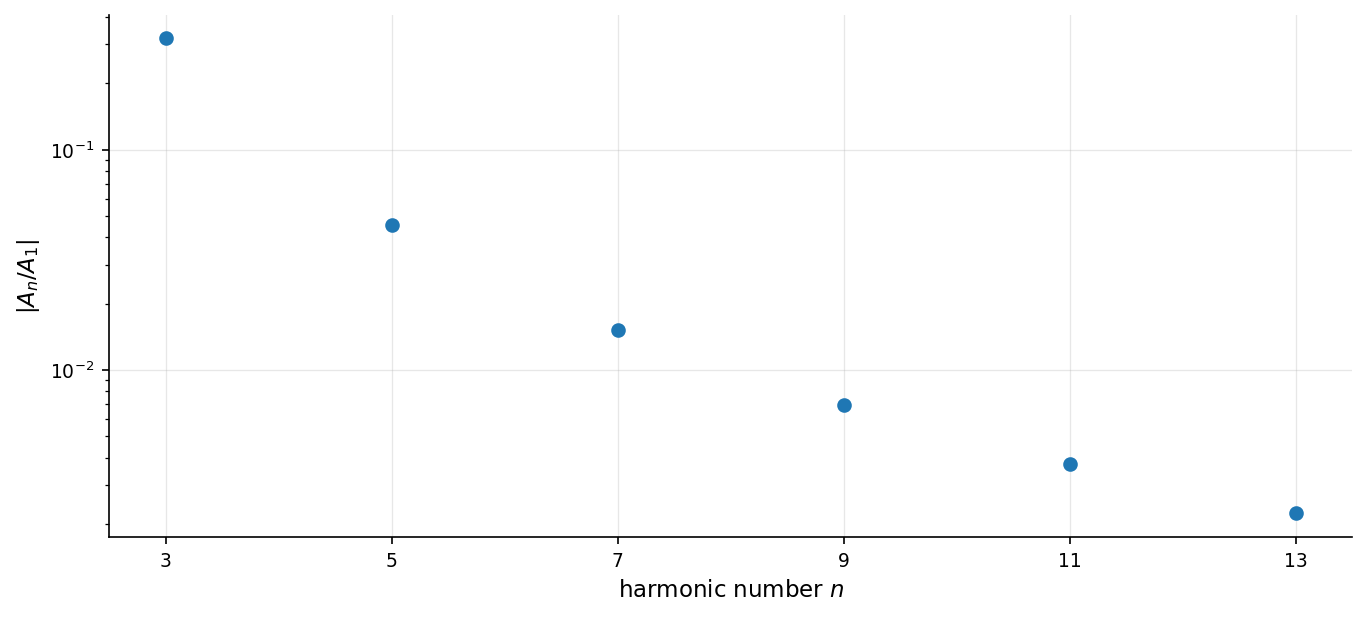

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os

plt.rcParams.update({
    "figure.figsize": (9, 4),
    "figure.dpi": 150,
    # 150 on screen. matplotlib's default 100 looks soft

    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    # crops whitespace and stops a legend placed outside the axes being cut off

    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    # labels slightly larger than ticks. ticks are reference, labels are read

    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    # axisbelow puts the grid behind the data, not over the curves

    "legend.frameon": False,
    "lines.linewidth": 1.6,

    "axes.spines.top": False,
    "axes.spines.right": False,
    # more ink on the data, less on the box

    "figure.constrained_layout.use": True,
})


def save_fig(fig, name):
    # writes to figures/ so the README can reference stable paths.
    # dpi and bbox come from rcParams, so they cannot drift between figures
    os.makedirs("figures", exist_ok=True)
    fig.savefig(f"figures/{name}.png")


theta = np.linspace(0, np.pi, 401)
# theta is a relabelling of position. theta=0 is left wingtip, theta=pi/2 is centre,
# theta=pi is right wingtip. sin(n*theta) vanishes at both tips for every n, so the
# boundary condition is built into the basis

eta = -np.cos(theta)
# normalised position, eta = 2y/b, from -1 to 1. shape not size


def gamma_theta(A, theta):
    # spanwise circulation from a dict of Fourier coefficients
    total = np.zeros_like(theta)
    for n, An in A.items():
        total = total + (An * np.sin(n * theta))
        # dropped 2bV_inf as it is constant in all cases and cancels in every ratio
    return total


bell_fourier = gamma_theta({1: 1.0, 3: -1/3}, theta)
bell_direct = (4/3) * np.sin(theta)**3
# same curve two ways. sin^3(theta) = (3 sin(theta) - sin(3 theta))/4, so the Fourier
# pair {1, -1/3} must reproduce it. validates the series machinery before anything
# is built on it

ell = gamma_theta({1: 1.0}, theta)
# elliptical loading. one harmonic only. baseline for every comparison

print(f"bell, two constructions agree to: {np.abs(bell_fourier - bell_direct).max():.2e}")


def CL(A, AR):
    # depends on the first harmonic alone. lift is linear in the series, and every
    # sin(n*theta) for n > 1 is orthogonal to the sin(theta) from dy, so it integrates
    # to zero. higher harmonics move lift along the span, they never add any
    return np.pi * AR * A[1]


def CDi(A, AR):
    # depends on every harmonic, weighted by n. drag is quadratic - circulation against
    # the downwash it generates - so orthogonality leaves the squares instead of
    # cancelling them. the extra n comes from the downwash being built from dGamma/dy
    total = 0
    for n, An in A.items():
        total = total + (n * An**2)
        # squared, so every harmonic adds drag. sign cannot help you
    return np.pi * AR * total
    # pi * AR pulled outside the loop. constant, applied once


A_ell = {1: 1.0}
A_bell = {1: 1.0, 3: -1/3}
# coefficient dicts. A_ prefix so they are never confused with the curves ell and bell

print(f"C_L elliptical: {CL(A_ell, 8):.6f}   C_L bell: {CL(A_bell, 8):.6f}")
print(f"C_Di ratio, bell over elliptical: {CDi(A_bell, 8) / CDi(A_ell, 8):.6f}")
# C_L identical, C_Di ratio 1.3333. same lift, 33% more drag: why the bell loses
# at fixed span


def bending_coeffs(n_b, kind, N=20001):
    # how much bending one unit of each harmonic produces
    theta_b = np.linspace(np.pi/2, np.pi, N)
    # right half span only. y is odd, so the full span would cancel to zero

    if kind == "root":
        weight = -np.cos(theta_b)
        # moment arm y. gives I_n, the peak moment carried at the wing-fuselage junction
    elif kind == "integrated":
        weight = np.cos(theta_b)**2
        # moment arm y squared. gives K_n, bending summed along the span, a proxy for
        # total spar material rather than the single worst point
    else:
        raise ValueError(f"kind must be 'root' or 'integrated', got {kind!r}")
        # catches typos like "Root" instead of a confusing NameError later

    bending_moment = {}
    for n in n_b:
        bending_moment[n] = np.trapezoid(np.sin(n * theta_b) * weight * np.sin(theta_b), theta_b)
        # three factors: the harmonic, the moment arm, and sin(theta) from
        # dy = (b/2) sin(theta) d theta. the moment arm sits between the two sines and
        # breaks orthogonality, which is what makes these coefficients nonzero
    return bending_moment


I = bending_coeffs([1, 3, 5, 7], "root")
K = bending_coeffs([1, 3, 5, 7, 9, 11], "integrated")

for n in I: print(f"I_{n} = {I[n]: .6f}")
for n in K: print(f"K_{n} = {K[n]: .6e}")
# I_n must be 1/3, 1/5, -1/21, 1/45. K_1 = K_3 = pi/16 with K_n = 0 for every n >= 5:
# integrated bending is blind to harmonics above the third
# .6e on K so a true zero can be told apart from a rounding artifact


def I_closed(n):
    # analytic form of the root-bending influence coefficient, from product-to-sum on
    # sin(n theta) sin(2 theta). the upper limit vanishes and only theta = pi/2 survives.
    # odd n only; n = 2 would divide by zero
    return -(-1)**((n - 1)//2) / (n**2 - 4)


I_check = bending_coeffs(list(range(1, 14, 2)), "root")
for n in I_check:
    assert abs(I_closed(n) - I_check[n]) < 1e-9, f"I_n mismatch at n={n}"
    # 1e-9 not 1e-15. trapezoid has finite resolution, so demanding machine precision
    # would test the integrator rather than the formula
print("closed form for I_n confirmed against numerical integration")

B_bell = sum(A_bell[n] * I[n] for n in A_bell)
B_ell = sum(A_ell[n] * I[n] for n in A_ell)
print(f"bending ratio, bell over elliptical: {(B_bell / B_ell):.6f}")
# bending is now a weighted sum, no integral needed. this is what the coefficients
# bought us. 0.80 exactly, which is why f = 0.80 is the fair comparison point below


def optimize(C, f, A1=1.0):
    # least-drag coefficients at bending fraction f. C is I or K, f is the bending
    # allowed as a fraction of elliptical, A1 is pinned by lift and never optimised

    free = [n for n in C if n != 1]
    # harmonics actually being optimised. A_1 is fixed by the lift requirement so it is
    # excluded from every sum, but still goes in the output dict

    denom = sum(C[n]**2/(2 * n) for n in free)
    # denominator of lambda. comes from substituting A_n = lam*C_n/(2n) back into the
    # constraint, so each harmonic contributes its influence squared over its drag cost

    if denom == 0:
        raise ValueError(
            "No free harmonic can move bending (all C_n == 0 for n in free); "
            f"keys passed: {list(C.keys())}"
        )
        # fires for K with keys above 3 only, where integrated bending is blind to every
        # free harmonic and no redistribution can reach the target

    lam = ((C[1] * A1) * (f - 1))/denom
    # exchange rate between bending and drag: how much drag one unit of relief costs.
    # negative for f < 1, which is what flips A_3 opposite in sign to C_3

    A = {1: A1}
    # seeded with the pinned harmonic first. building the free ones first and forgetting
    # this makes CDi return a wrong number silently instead of raising KeyError

    for n in free:
        A[n] = float((lam * C[n])/(2 * n))
        # the stationarity condition. A_n is proportional to C_n / n: a harmonic gets
        # used in proportion to the relief it buys and inversely to the drag it costs.
        # float() because trapezoid returns np.float64, which prints badly in a dict

    return A


A_opt = optimize(I, f=0.8)
# the optimum under root bending at 80% of elliptical. least drag for that budget
B = sum(A_opt[n] * I[n] for n in A_opt)

print(f"root optimum at f=0.80, bending ratio: {B / B_ell:.6f}")
print(f"root optimum at f=0.80, drag ratio:    {CDi(A_opt, 8) / CDi(A_ell, 8):.6f}")
# 1.3207 against the bell's 1.3333 at identical lift and identical root bending.
# the bell is optimal for integrated bending, not for every structural constraint

for f in [0.9, 2/3, 0.5]:
    A_test = optimize(K, f=f)
    print(f"f = {f:.4f}   A_3/A_1 = {A_test[3]/A_test[1]: .6f}")
# A_3/A_1 = f - 1 exactly, because K_1 = K_3 and every higher K_n is zero. the optima
# form a one-parameter family and Prandtl's bell is just where f = 2/3 lands


def sweep(C, B_ref, f_values, AR=8.0):
    # trade-off table for one bending criterion. C is I or K, B_ref is that criterion's
    # elliptical baseline. AR cancels in every ratio but is exposed as a parameter so
    # the invariance check below can vary it
    results = []
    for f in f_values:
        A_f = optimize(C, f=f)

        drag_f = CDi(A_f, AR) / CDi(A_ell, AR)
        # must be the same AR in both calls or the ratio is wrong and nothing complains

        a3_f = A_f[3] / A_f[1]
        # shape not size. dividing by A_1 makes it independent of the lift level

        bend_f = sum(A_f[n] * C[n] for n in A_f) / B_ref
        # C and B_ref must be the same criterion, or this compares root bending against
        # an integrated baseline

        assert abs(bend_f - f) < 1e-10, f"bending mismatch at f={f:.2f}: got {bend_f}"
        # the constraint imposed must be the constraint satisfied. the only check that
        # catches a sign error in lambda, which the drag column would happily hide

        delta_f = sum(n * (A_f[n]/A_f[1])**2 for n in A_f if n != 1)
        # fractional drag penalty above elliptical (Anderson, ch. 5). computed from the
        # coefficients rather than from drag_f so the assert below is a real check

        e_f = 1 / (1 + delta_f)

        assert abs(e_f * drag_f - 1) < 1e-12, f"span efficiency mismatch at f={f:.2f}"
        # two independent routes to the same physics. confirms the pi*AR prefactors
        # in CDi cancelled cleanly

        results.append({"f": f, "drag": drag_f, "a3_ratio": a3_f,
                        "bending": bend_f, "e": e_f})
        # one dict per row so the columns cannot drift out of sync
    return results


def print_table(results, label):
    # both sweeps print identically, so the formatting lives in one place
    print(f"\n{label}")
    print(f"{'f':>6}  {'C_Di ratio':>11}  {'A_3/A_1':>9}  {'bending':>8}  {'e':>8}")
    for r in results:
        print(f"{r['f']:>6.2f}  {r['drag']:>11.6f}  {r['a3_ratio']:>9.6f}  "
              f"{r['bending']:>8.4f}  {r['e']:>8.4f}")
        # right-aligned so a non-monotonic row is visible at a glance


B_ell_K = sum(A_ell[n] * K[n] for n in A_ell)
# elliptical's bending under the integrated criterion. B_ell is the root-bending
# baseline, so the two are not interchangeable

f_table = np.linspace(1.00, 0.70, 31)
# linspace not arange. arange accumulates float error and its stop value is exclusive

results_I = sweep(I, B_ell, f_table)
results_K = sweep(K, B_ell_K, f_table)

print_table(results_I, "ROOT bending constraint")
print_table(results_K, "INTEGRATED bending constraint")


def trade_coeff(C):
    # the coefficient c in CDi/CDi_ell = 1 + c(1-f)^2. bending the pinned harmonic
    # forces, over the leverage the free ones can offer, each discounted by its drag cost
    free = [n for n in C if n != 1]
    denom = sum(C[n]**2/(2 * n) for n in free)
    # same construction as optimize. kept duplicated rather than factored out; if one
    # changes the other must
    return (C[1]**2)/(2 * denom)


c_I = trade_coeff(I)
c_K = trade_coeff(K)
print(f"\nc_I = {c_I:.6f}   c_K = {c_K:.6f}")
# root bending costs 8/3 times more per unit relief than integrated bending

for r in results_I:
    assert abs(1 + c_I * (r["f"] - 1)**2 - r["drag"]) < 1e-10, \
        f"closed form disagrees at f={r['f']:.2f}"
for r in results_K:
    assert abs(1 + c_K * (r["f"] - 1)**2 - r["drag"]) < 1e-10, \
        f"closed form disagrees at f={r['f']:.2f}"
# all 62 rows against a formula derived independently of the loop that produced them

check_at = [0.90, 0.80, 0.70]
for label, results, c in [("ROOT", results_I, c_I), ("INTEGRATED", results_K, c_K)]:
    print(f"\n{label}")
    print(f"{'f':>6}  {'computed':>10}  {'closed form':>12}  {'diff':>10}")
    for r in results:
        if any(abs(r["f"] - t) < 1e-9 for t in check_at):
            pred = 1 + c * (r["f"] - 1)**2
            print(f"{r['f']:>6.2f}  {r['drag']:>10.6f}  {pred:>12.6f}  "
                  f"{abs(pred - r['drag']):>10.2e}")
            # scientific notation so machine precision reads as 1e-16, not 0.00

# ---- truncation: how far the series must be carried

print(f"\n{'top n':>6}  {'c_I':>12}  {'change':>10}")
prev = None
for top in [7, 9, 11, 13, 21, 51]:
    c_trunc = trade_coeff(bending_coeffs(list(range(1, top + 1, 2)), "root"))
    # only c is needed, not a full sweep. c fixes the entire curve, so showing c has
    # converged shows the whole trade-off has

    change = "" if prev is None else f"{abs(c_trunc - prev)/prev * 100:>9.4f}%"
    print(f"{top:>6}  {c_trunc:>12.6f}  {change:>10}")
    # change is per level, not per harmonic. the levels are unevenly spaced, so the
    # last two rows span four harmonics each rather than one
    prev = c_trunc

c_7 = trade_coeff(bending_coeffs(list(range(1, 8, 2)), "root"))
c_51 = trade_coeff(bending_coeffs(list(range(1, 52, 2)), "root"))
print(f"truncating at n=7 overestimates c by {(c_7 - c_51)/c_51 * 100:.3f}%")

for top in [7, 51, 201, 801]:
    denom = sum(I_closed(n)**2/(2 * n) for n in range(3, top + 1, 2))
    print(f"{top:>4}  c_I = {(1/3)**2 / (2 * denom):.10f}")
    # the closed form lets the sum run far past anything trapezoid could resolve.
    # c_I is exactly 8, so c_I / c_K is exactly 8/3

# ---- compressibility: the result does not depend on Mach or aspect ratio

ref = [r["drag"] for r in results_I]
for M in [0.0, 0.3, 0.6, 0.8]:
    beta = np.sqrt(1 - M**2)
    # subsonic compressible flow maps to an equivalent incompressible problem with the
    # aspect ratio scaled by beta

    test = [r["drag"] for r in sweep(I, B_ell, f_table, AR=8.0 * beta)]
    worst = max(abs(a - b) for a, b in zip(ref, test))

    print(f"M = {M:.1f}   beta*AR = {8*beta:.3f}   max drag-ratio difference = {worst:.2e}")
    assert worst < 1e-12, f"AR dependence leaked in at M={M}"
    # confirms the premise the argument rests on: nothing in the optimisation sees AR.
    # the optimal loading is Mach-invariant subcritically; the wing producing it is not

# ---- figures

f_plot = np.linspace(1.00, 0.65, 71)
# wider than f_table because the bell sits at f = 2/3, below the 0.70 floor.
# finer too, since this is drawn rather than read

plot_I = sweep(I, B_ell, f_plot)
plot_K = sweep(K, B_ell_K, f_plot)
# same function as the tables, so the figure and the numbers cannot disagree

f_bell = 2/3
drag_bell = 1 + c_K * (f_bell - 1)**2
# computed from c_K, not hardcoded as 4/3, so the marker tracks anything upstream

fig, ax = plt.subplots()
ax.plot([r["f"] for r in plot_I], [r["drag"] for r in plot_I],
        color="C0", label="Root bending constraint")
ax.plot([r["f"] for r in plot_K], [r["drag"] for r in plot_K],
        color="C3", label="Integrated bending constraint")
ax.plot(f_bell, drag_bell, "o", color="C3", ms=7, zorder=5)
# zorder above the lines so the marker is not half-buried by the curve

ax.annotate("Prandtl 1933 bell", xy=(f_bell, drag_bell),
            xytext=(8, -14), textcoords="offset points", color="C3")

ax.set_xlabel("bending moment, fraction of elliptical  ($f$)")
ax.set_ylabel(r"$C_{D,i} \, / \, C_{D,i,\mathrm{elliptical}}$")
ax.invert_xaxis()
# f decreases rightward, so more relief reads left-to-right and the cost rises

ax.legend(loc="upper left")
save_fig(fig, "tradeoff_two_criteria")

opt80 = gamma_theta(A_opt, theta)

e_opt = 1 / (1 + sum(n * (A_opt[n]/A_opt[1])**2 for n in A_opt if n != 1))
e_bell = 1 / (1 + sum(n * (A_bell[n]/A_bell[1])**2 for n in A_bell if n != 1))
# computed, not typed into the legend, so the labels cannot go stale

fig, ax = plt.subplots()
ax.plot(eta, ell, color="C0", label="Elliptical  ($e = 1.000$)")
ax.plot(eta, bell_fourier, "--", color="C3", label=f"Prandtl bell  ($e = {e_bell:.3f}$)")
ax.plot(eta, opt80, "-.", color="C2",
        label=f"Root optimum, $f = 0.80$  ($e = {e_opt:.3f}$)")

ax.set_xlabel("$2y/b$")
ax.set_ylabel("circulation (arbitrary units)")
ax.set_ylim(0, 1.45)
ax.axhline(0, color="0.5", lw=0.7)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
save_fig(fig, "loading_shapes")
# the bell and the optimum are visually indistinguishable. a 1% drag difference does
# not show up to the eye

I_13 = bending_coeffs(list(range(1, 14, 2)), "root")
A_13 = optimize(I_13, f=0.8)
# out to n = 13 so the collapse spans two decades rather than one

harmonics = [n for n in A_13 if n != 1]
mags = [abs(A_13[n]/A_13[1]) for n in harmonics]

fig, ax = plt.subplots()
ax.plot(harmonics, mags, "o", color="C0", ms=6)
# markers not lines. n is discrete, and a connecting line implies values between them

ax.set_yscale("log")
ax.set_xticks(harmonics)
ax.set_xlabel("harmonic number $n$")
ax.set_ylabel(r"$|A_n / A_1|$")
save_fig(fig, "coefficient_collapse")

## 2. General bending exponent: closed form of c(k) = 4(1+k)/k² and verification

regression gate passed: k=1 reproduces I, k=2 reproduces K
closed-form C_n confirmed against numerical integration
    k     c numeric    4(1+k)/k^2   rel error
  0.5     24.000006     24.000000    2.48e-07
  1.0      8.000000      8.000000    1.08e-09
  1.5      4.444444      4.444444    1.57e-10
  2.0      3.000000      3.000000    4.44e-16
  3.0      1.777778      1.777778    3.75e-16
  4.0      1.250000      1.250000    7.11e-16
 top n               c   error vs 24
     7     24.32814316      3.28e-01
    51     24.00116764      1.17e-03
   151     24.00004674      4.67e-05
   301     24.00000596      5.96e-06

k = 0.5 from the series: c = 24.000000000091


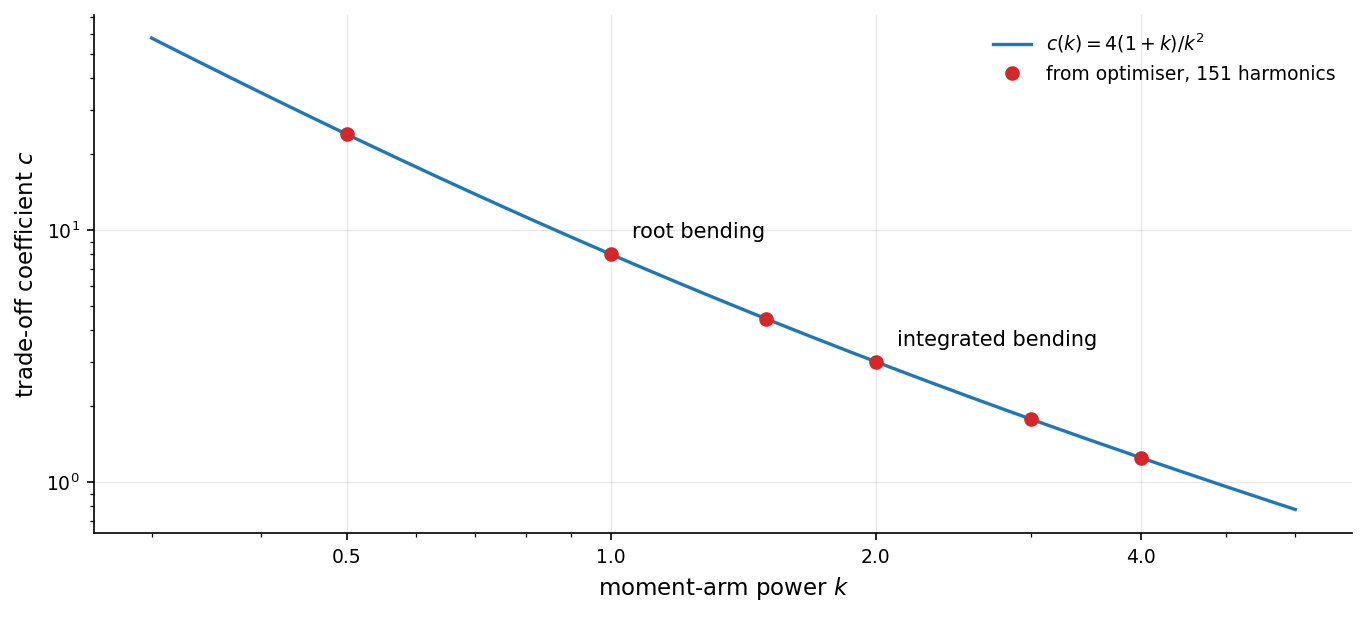

In [3]:
from scipy.integrate import quad
from scipy.special import gamma

def bending_coeffs_k(n_b, k):
    # influence coefficients for a bending constraint with moment arm |y|^k.
    # k = 1 is root bending, k = 2 is integrated bending, other k interpolate
    coeffs = {}
    for n in n_b:
        integrand = lambda t: np.sin(n*t) * (-np.cos(t))**k * np.sin(t)
        # same three factors as bending_coeffs: the harmonic, the moment arm, the
        # jacobian from dy. -cos keeps the base non-negative, so fractional k is defined
        coeffs[n] = quad(integrand, np.pi/2, np.pi, limit=400)[0]
        # quad not trapezoid. for k < 1 the arm has an infinite slope at theta = pi/2,
        # and an adaptive integrator handles that where a fixed grid loses accuracy
    return coeffs

I_new = bending_coeffs_k([1, 3, 5, 7], 1)
K_new = bending_coeffs_k([1, 3, 5, 7, 9, 11], 2)

for n in I:
    assert abs(I_new[n] - I[n]) < 1e-9, f"k=1 disagrees with I at n={n}"
for n in K:
    assert abs(K_new[n] - K[n]) < 1e-9, f"k=2 disagrees with K at n={n}"
print("regression gate passed: k=1 reproduces I, k=2 reproduces K")
# the new function must agree with the validated one before anything new is trusted

def C_closed(n_b, k):
    # C_n from the analytic derivation, no integration. C_1 from gamma functions, then
    # each later coefficient from the previous one by the pochhammer ratio
    a = k/2
    C1 = np.pi * gamma(k+1) / 2**(k+2) / (gamma(a+2) * gamma(a+1))

    coeffs, ratio = {}, 1.0
    for j in range((max(n_b) + 1)//2):
        n = 2*j + 1
        if n in n_b:
            coeffs[n] = C1 * n * (-1)**j * ratio
        ratio *= (-a + j)/(a + 2 + j)
        # ratio is (-a)_j / (a+2)_j, built one factor at a time. raw gamma values
        # overflow to inf for large n, and inf * 0 gives nan
    return coeffs

for k in [0.5, 1, 1.5, 2, 3]:
    by_quad = bending_coeffs_k(list(range(1, 26, 2)), k)
    by_formula = C_closed(list(range(1, 26, 2)), k)
    worst = max(abs(by_quad[n] - by_formula[n]) for n in by_quad)
    assert worst < 1e-10, f"closed form disagrees at k={k}: {worst:.2e}"
print("closed-form C_n confirmed against numerical integration")
# two independent routes to the same coefficients: the calculus and the algebra

def c_formula(k):
    return 4*(1 + k)/k**2

harmonics = list(range(1, 302, 2))
# 151 odd harmonics. small k converges slowly, so seven is no longer enough
k_values = [0.5, 1, 1.5, 2, 3, 4]
results_ck = []

print(f"{'k':>5}  {'c numeric':>12}  {'4(1+k)/k^2':>12}  {'rel error':>10}")
for k in k_values:
    c_num = trade_coeff(bending_coeffs_k(harmonics, k))
    # trade_coeff needs no changes. it takes any coefficient dict, which is what
    # building it off the input rather than hardcoding I bought us
    c_th = c_formula(k)
    rel = abs(c_num - c_th)/c_th
    results_ck.append({"k": k, "c": c_num})
    print(f"{k:>5.1f}  {c_num:>12.6f}  {c_th:>12.6f}  {rel:>10.2e}")
    assert rel < 1e-5, f"c(k) misses the formula at k={k}"

C_half = bending_coeffs_k(list(range(1, 302, 2)), 0.5)
# computed once and sliced, rather than recomputed at each truncation level

print(f"{'top n':>6}  {'c':>14}  {'error vs 24':>12}")
for top in [7, 51, 151, 301]:
    truncated = {n: C_half[n] for n in C_half if n <= top}
    c_t = trade_coeff(truncated)
    print(f"{top:>6}  {c_t:>14.8f}  {abs(c_t - 24):>12.2e}")
# k = 0.5 converges slowest, so if it settles on 24 every other k is safe

def c_from_series(k, terms=200_000):
    # c from the pochhammer series in step 5 of the proof, summed directly.
    # no integration and no truncation in harmonics, only in the series
    a, r, R = k/2, 1.0, 0.0
    for j in range(terms):
        R += (2*j + 1) * r * r
        r *= (-a + j)/(a + 2 + j)
    return 1/(R - 1)

print(f"\nk = 0.5 from the series: c = {c_from_series(0.5):.12f}")

kk = np.logspace(np.log10(0.3), np.log10(6), 200)

fig, ax = plt.subplots()
ax.plot(kk, c_formula(kk), color="C0", label=r"$c(k) = 4(1+k)/k^2$")
ax.plot([r["k"] for r in results_ck], [r["c"] for r in results_ck], "o",
        color="C3", ms=6, zorder=5, label="from optimiser, 151 harmonics")
# markers on top of the line. the claim is that independent computation lands on it

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([0.5, 1, 2, 4])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
# without this a log axis only labels powers of ten, which here is just 1

for k, label in [(1, "root bending"), (2, "integrated bending")]:
    ax.annotate(label, xy=(k, c_formula(k)), xytext=(10, 8), textcoords="offset points")

ax.set_xlabel("moment-arm power $k$")
ax.set_ylabel("trade-off coefficient $c$")
ax.legend(loc="upper right")
save_fig(fig, "c_of_k")



## 3. Span extension at fixed bending: the optimum f* and the truncation trap

   k       f*   span num    span th   drag num    drag th
   1   0.7500    1.33333    1.33333    0.84375    0.84375
 1.5   0.7000    1.26843    1.26843    0.87015    0.87015
   2   0.6667    1.22474    1.22474    0.88889    0.88889
   3   0.6250    1.16961    1.16961    0.91376    0.91376

   k    min dh/df   flattest at       f*
   1    -8.22e-10        0.7500   0.7500
 1.5     6.33e-10        0.7000   0.7000
   2     4.00e-10        0.6667   0.6667
   3     1.82e-10        0.6250   0.6250
c with 7 harmonics = 8.018182
discriminant of Q  = 1.4579e-01
roots of Q         = 0.7381, 0.7619
local max at f = 0.7381:  b/b_0 = 1.3548,  D/D_ell = 0.844416
local min at f = 0.7619:  b/b_0 = 1.3125,  D/D_ell = 0.844362
   k        f    tip slope   (f-f*)/(1-f*)
   1   0.7300    -8.00e-02         -0.0800
   1   0.7500     3.29e-05          0.0000
   1   0.7700     8.00e-02          0.0800

 1.5   0.6800    -6.67e-02         -0.0667
 1.5   0.7000     1.58e-06          0.0000
 1.5   0.7200     6.67e

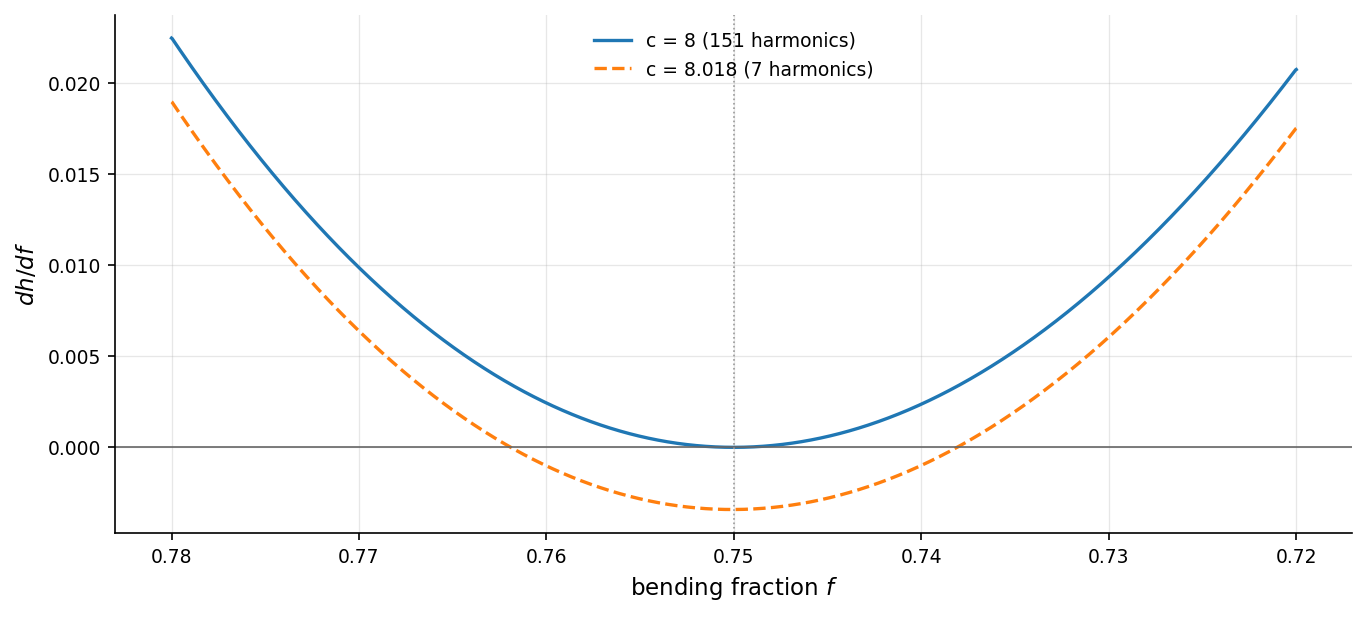

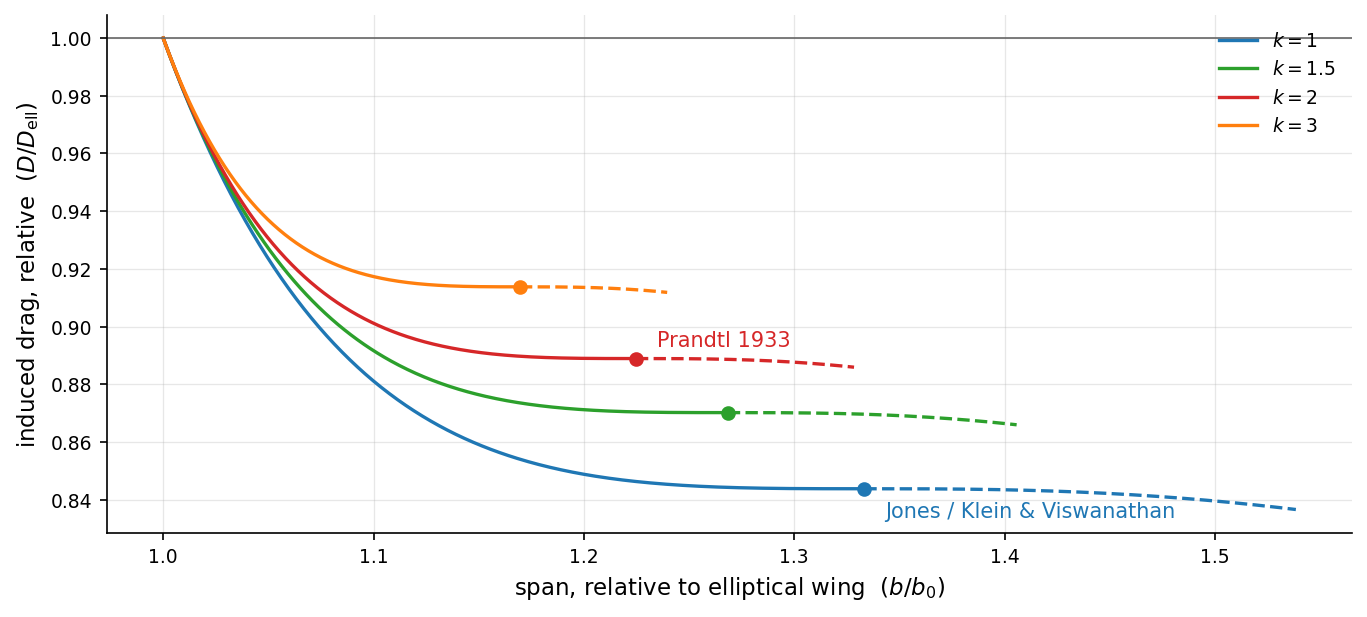

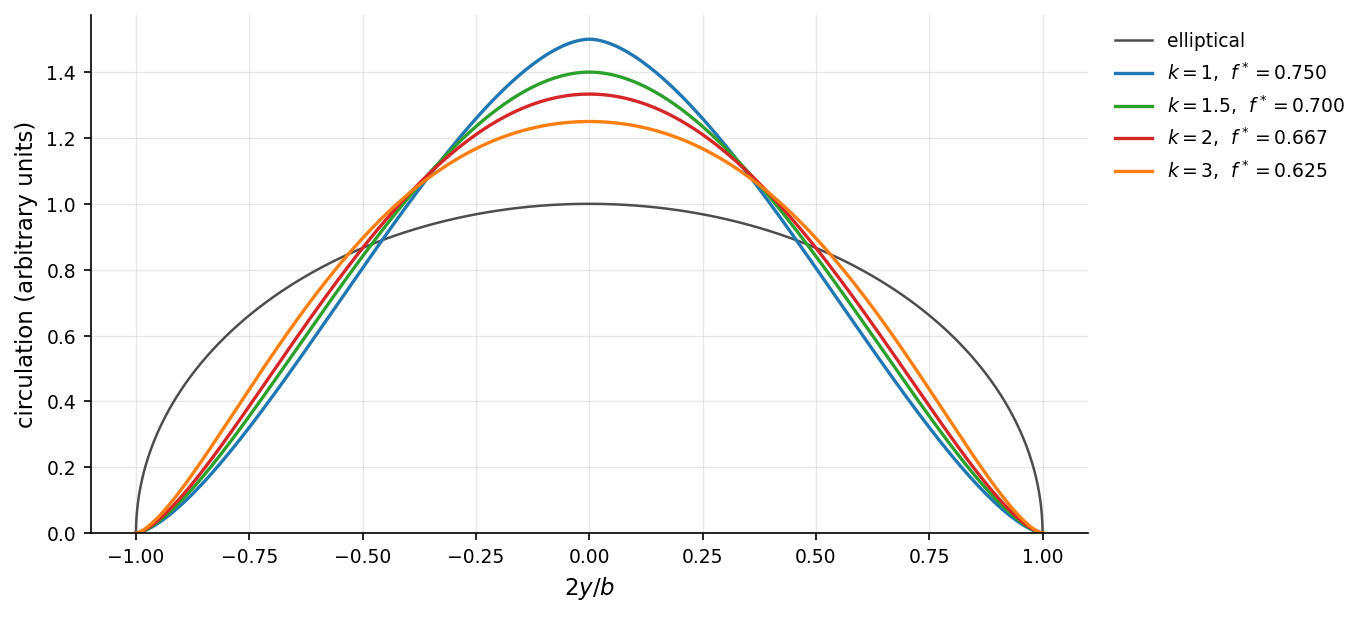

In [4]:
def span_released(f, k, c):
    # optimal wing against an elliptical wing of span b_0 carrying the same lift and
    # the same k-moment of bending. lower f buys span, but costs shape
    span_ratio = f**(-1/k)
    # b/b_0. equal bending means (b/b_0)^k * f = 1, since bending scales as L*b^k*f
    drag_ratio = (1 + c*(1 - f)**2) * f**(2/k)
    # h(f) = D/D_ell. shape penalty 1 + delta = 1 + c(1-f)^2, times span benefit
    # (b_0/b)^2 = f^(2/k), since induced drag goes as (1 + delta)/b^2
    return span_ratio, drag_ratio


def f_star(k):
    # f* = (2+k)/(2(1+k)). the double root of Q(f), where dh/df touches zero
    return (2 + k)/(2*(1 + k))


def predicted(k):
    # b/b_0 and D/D_ell at f*, in closed form. c has been substituted out, so this
    # never sees the numerical c it is compared against
    fs = f_star(k)
    span = fs**(-1/k)
    # b/b_0 = (2(1+k)/(2+k))^(1/k)
    drag = (2 + k)/(1 + k) * fs**(2/k)
    # D/D_ell = (1 + delta*) (f*)^(2/k), with 1 + delta* = (2+k)/(1+k)
    return span, drag


k_span = [1, 1.5, 2, 3]
# k = 1 and 2 have published answers. 1.5 and 3 are new predictions

c_opt = {k: trade_coeff(bending_coeffs_k(list(range(1, 302, 2)), k)) for k in k_span}
# c from the optimiser, not from 4(1+k)/k^2, so the gate below is a real test.
# computed once and reused, so both checks use identical values

print(f"{'k':>4}  {'f*':>7}  {'span num':>9}  {'span th':>9}  {'drag num':>9}  {'drag th':>9}")
for k in k_span:
    fs = f_star(k)
    span_num, drag_num = span_released(fs, k, c_opt[k])
    # general h(f) with optimiser c, evaluated at f*
    span_th, drag_th = predicted(k)
    # fully simplified closed form, no c
    print(f"{k:>4}  {fs:>7.4f}  {span_num:>9.5f}  {span_th:>9.5f}  {drag_num:>9.5f}  {drag_th:>9.5f}")
    assert abs(span_num - span_th) < 1e-6 and abs(drag_num - drag_th) < 1e-6, \
        f"span-extension mismatch at k={k}"
# k = 1 must give b/b_0 = 4/3 and D/D_ell = 27/32: klein and viswanathan.
# k = 2 must give b/b_0 = 1.2247 and D/D_ell = 8/9: prandtl 1933

f_grid = np.linspace(0.40, 1.00, 60001)
# dense, because dh/df ~ (f - f*)^2 is extremely flat near f* and a coarse grid
# could step straight over it

print(f"\n{'k':>4}  {'min dh/df':>11}  {'flattest at':>12}  {'f*':>7}")
for k in k_span:
    _, h = span_released(f_grid, k, c_opt[k])
    # whole array at once. every operation in span_released is elementwise
    dh = np.gradient(h, f_grid)
    # dh/df by finite differences. no use of Q or its discriminant, so this checks
    # the differentiation and the perfect-square result independently
    i_flat = np.argmin(np.abs(dh))
    # index of the flattest point on the curve
    print(f"{k:>4}  {dh.min():>11.2e}  {f_grid[i_flat]:>12.4f}  {f_star(k):>7.4f}")
    assert dh.min() > -1e-6, f"drag curve turns around at k={k}: a true minimum exists"
    assert abs(f_grid[i_flat] - f_star(k)) < 1e-3, f"flat point is not at f* for k={k}"
# a minimum and an inflection both look flat. only the sign of dh/df either side
# separates them, and here it never goes meaningfully negative: h(f) is monotonic.
# k = 1 comes out around -8e-10, not zero. with 151 harmonics c is 8.000000009, a
# hair above 8, so the discriminant of Q is very slightly positive and a dip a
# billionth deep appears. truncation manufactures a fake minimum

c_7 = trade_coeff(bending_coeffs_k([1, 3, 5, 7], 1))
# c for root bending with only seven harmonics: 8.018 instead of 8

k = 1
qa, qb, qc = c_7*(1 + k), -c_7*(2 + k), 1 + c_7
# Q(f) = qa f^2 + qb f + qc, with qa = c(1+k), qb = -c(2+k), qc = 1+c

disc = qb**2 - 4*qa*qc
# delta = c[ck^2 - 4(1+k)]. exactly zero when c = 8, positive when c = 8.018

f_lo = (-qb - np.sqrt(disc))/(2*qa)
f_hi = (-qb + np.sqrt(disc))/(2*qa)
# two real roots of Q. between them Q < 0, so dh/df < 0 and h(f) turns around

print(f"c with 7 harmonics = {c_7:.6f}")
print(f"discriminant of Q  = {disc:.4e}")
print(f"roots of Q         = {f_lo:.4f}, {f_hi:.4f}")

for label, f_r in [("local max", f_lo), ("local min", f_hi)]:
    span_r, drag_r = span_released(f_r, k, c_7)
    print(f"{label:>9} at f = {f_r:.4f}:  b/b_0 = {span_r:.4f},  D/D_ell = {drag_r:.6f}")
# extending span from f = 1, drag falls until f_hi, rises until f_lo, then falls again.
# so f_hi is a local minimum of h(f) that does not exist in the exact problem

f_zoom = np.linspace(0.72, 0.78, 2001)
# narrow window around f* = 0.75, where the two curves differ

fig, ax = plt.subplots()
for c_val, label, style in [(c_opt[1], "c = 8 (151 harmonics)", "-"),
                            (c_7, f"c = {c_7:.3f} (7 harmonics)", "--")]:
    _, h = span_released(f_zoom, 1, c_val)
    ax.plot(f_zoom, np.gradient(h, f_zoom), style, label=label)
    # plot dh/df rather than h(f). the dip in h is only 5e-5 and invisible, but the
    # sign change in dh/df is unmistakable

ax.axhline(0, color="0.4", lw=0.8)
ax.axvline(f_star(1), color="0.6", lw=0.8, ls=":")
# dh/df = 0 line, and f* = 3/4
ax.set_xlabel("bending fraction $f$")
ax.set_ylabel(r"$dh/df$")
ax.invert_xaxis()
# f decreasing rightward, so moving right means extending span
ax.legend(loc="upper center")
save_fig(fig, "truncation_trap")

C_k = {k: bending_coeffs_k(list(range(1, 302, 2)), k) for k in k_span}
# coefficient dicts for each k, kept this time because optimize needs them, not just c

def tip_slope(A):
    # dGamma/dtheta at theta = 0. differentiating sum A_n sin(n theta) gives
    # sum n A_n cos(n theta), and cos(0) = 1
    return sum(n * A[n] for n in A)

print(f"{'k':>4}  {'f':>7}  {'tip slope':>11}  {'(f-f*)/(1-f*)':>14}")
for k in k_span:
    fs = f_star(k)
    for f in [fs - 0.02, fs, fs + 0.02]:
        s = tip_slope(optimize(C_k[k], f))
        lin = (f - fs)/(1 - fs)
        # every A_n is proportional to (f - 1), so the tip slope is linear in f.
        # it is 1 at f = 1, the elliptical value, and the claim is that it is 0 at f*
        print(f"{k:>4}  {f:>7.4f}  {s:>11.2e}  {lin:>14.4f}")
        assert abs(s - lin) < 1e-4, f"tip slope off the line at k={k}, f={f:.4f}"
    print()
# above f* the tips lift. below f* the slope is negative and the tips push down.
# f* is the last bending fraction at which the whole wing lifts upward

colours = {1: "C0", 1.5: "C2", 2: "C3", 3: "C1"}
# fixed per k so both figures below use the same colour for the same criterion

fig, ax = plt.subplots()
for k in k_span:
    fs = f_star(k)
    f_above = np.linspace(1.0, fs, 400)
    f_below = np.linspace(fs, fs - 0.10, 400)
    # above f* the whole wing lifts. below it the tips push down, drawn dashed
    for f_part, style in [(f_above, "-"), (f_below, "--")]:
        span, drag = span_released(f_part, k, c_opt[k])
        ax.plot(span, drag, style, color=colours[k],
                label=f"$k = {k}$" if style == "-" else None)
        # parametric in f: x is b/b_0, y is h(f). one legend entry per k, not two
    span_s, drag_s = span_released(fs, k, c_opt[k])
    ax.plot(span_s, drag_s, "o", color=colours[k], ms=6, zorder=5)
    # the inflection, where dh/df touches zero and the tip slope vanishes

for k, label, offset in [(1, "Jones / Klein & Viswanathan", (10, -14)),
                         (2, "Prandtl 1933", (10, 6))]:
    span_s, drag_s = span_released(f_star(k), k, c_opt[k])
    ax.annotate(label, xy=(span_s, drag_s), xytext=offset,
                textcoords="offset points", color=colours[k])

ax.axhline(1.0, color="0.4", lw=0.8)
# D/D_ell = 1. everything below this line beats the elliptical wing
ax.set_xlabel(r"span, relative to elliptical wing  ($b/b_0$)")
ax.set_ylabel(r"induced drag, relative  ($D/D_\mathrm{ell}$)")
ax.legend(loc="upper right")
save_fig(fig, "span_extension")


fig, ax = plt.subplots()
ax.plot(eta, gamma_theta({1: 1.0}, theta), color="0.3", lw=1.2, label="elliptical")
for k in k_span:
    A = optimize(C_k[k], f_star(k))
    ax.plot(eta, gamma_theta(A, theta), color=colours[k],
            label=f"$k = {k}$,  $f^* = {f_star(k):.3f}$")
    # all have A_1 = 1, so all carry identical lift and are directly comparable

ax.set_xlabel("$2y/b$")
ax.set_ylabel("circulation (arbitrary units)")
ax.set_ylim(bottom=0)
# bottom only. the k = 1 loading peaks near 1.5 and a fixed top would clip it
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
save_fig(fig, "optimal_loadings_at_fstar")



## 4. Example planforms (NACA 0012, AR 8): illustration only, not used in Part B

  elliptical: root   6.95 deg (hand   6.95),  tip   1.14 deg (hand   1.14)
 bell f*=2/3: root  10.02 deg (hand  10.02),  tip  -2.28 deg (hand  -2.28)
hand-check gate passed

          wing  taper       C_L  A3/A1 rec    target  drag rec    target
    elliptical    1.0  0.500000   0.000000  0.000000  1.000000  1.000000
   root f=0.80    1.0  0.500033  -0.320026 -0.320000  1.320083  1.320000
   k=1 f*=0.75    1.0  0.500041  -0.400025 -0.400000  1.500113  1.500000
   bell f*=2/3    1.0  0.500000  -0.333333 -0.333333  1.333333  1.333333
    elliptical    0.5  0.500000  -0.000000  0.000000  1.000000  1.000000
   root f=0.80    0.5  0.500038  -0.320030 -0.320000  1.320096  1.320000
   k=1 f*=0.75    0.5  0.500048  -0.400030 -0.400000  1.500131  1.500000
   bell f*=2/3    0.5  0.500000  -0.333333 -0.333333  1.333333  1.333333
forward-solve gate passed: every twist reproduces its loading

          wing  taper     root      tip   washout
    elliptical    1.0     6.95     1.14      5.81
   roo

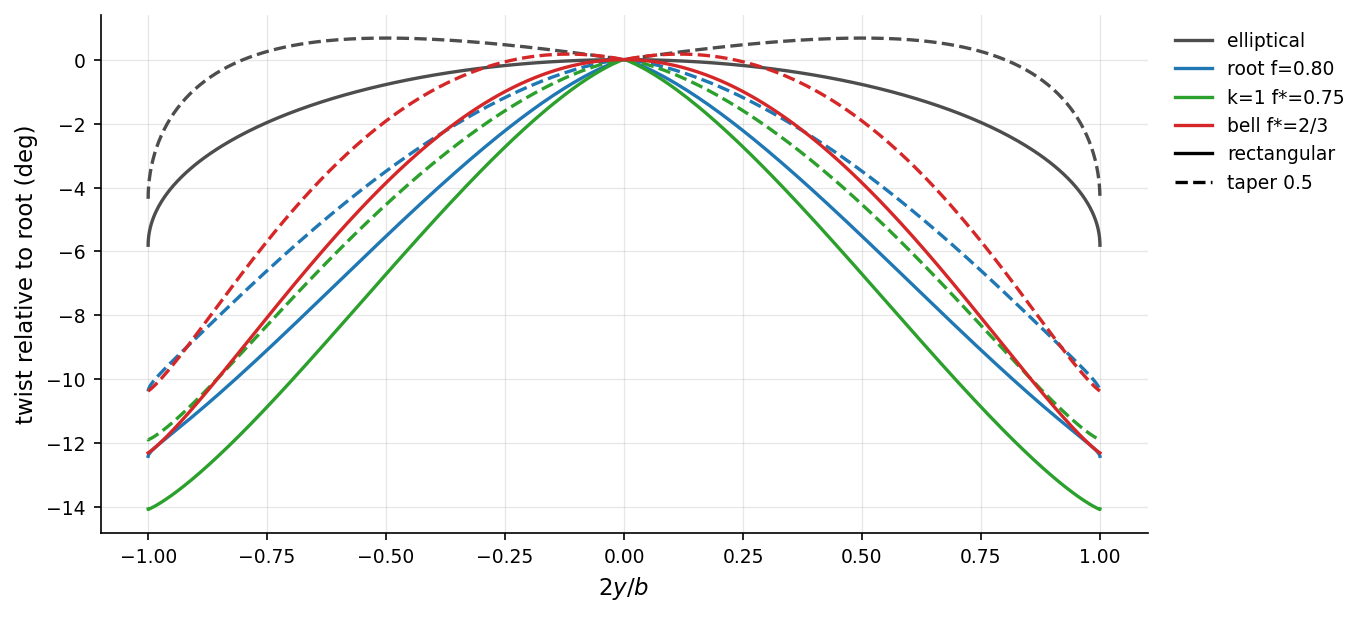

In [5]:
AR_d = 8.0
CL_d = 0.5
a0 = 2*np.pi
b_d = 1.0
# design aspect ratio, design lift coefficient, section lift slope, span.
# naca 0012 is symmetric so alpha_L0 = 0 and drops out everywhere below
 
def chord(theta, taper, AR=AR_d, b=b_d):
    # chord c(theta) for a linearly tapered wing. taper is c_tip/c_root.
    # AR and b default to the design values, so every older call works unchanged
    c_root = 2*b/(AR*(1 + taper))
    # trapezoid area S = b c_root (1 + taper)/2 with AR = b^2/S. fixing AR this way
    # means every planform has the same aspect ratio, so the comparison is fair
    eta = np.abs(np.cos(theta))
    # |2y/b|. 0 at the root, 1 at the tips
    return c_root*(1 - (1 - taper)*eta)
    # shrinks linearly from c_root at the root to taper*c_root at the tips
 
 
def twist(A_unit, taper, theta, AR=AR_d, b=b_d):
    # geometric angle alpha(theta) in degrees that makes this planform carry loading
    # A_unit at C_L = CL_d. the lifting-line equation run backwards: A_n known, alpha out
    A1 = CL_d/(np.pi*AR)
    A = {n: a*A1 for n, a in A_unit.items()}
    # C_L = pi AR A_1 fixes the size. optimize returns A_1 = 1, so every coefficient is
    # scaled by the real A_1. the shape A_n/A_1 is untouched
 
    s = np.sin(theta)
    near_tip = s < 1e-12
    safe_s = np.where(near_tip, 1.0, s)
    # sin(theta) is zero at the tips. swap those for 1 before dividing so nothing
    # divides by zero; the true tip value is put back below
 
    loading = sum(a*np.sin(n*theta) for n, a in A.items())
    effective = 4*b/(a0*chord(theta, taper, AR, b)) * loading
    # alpha_eff = (4b/(a0 c)) sum A_n sin(n theta). the angle the section must feel to
    # carry its share of circulation. b cancels against the b inside c_root, so only
    # AR and taper matter, but passing b keeps the two consistent for any span
 
    induced = sum(n*a*np.where(near_tip, n, np.sin(n*theta)/safe_s) for n, a in A.items())
    # alpha_i = sum n A_n sin(n theta)/sin(theta). the downwash tilt, so the section
    # must be set this much steeper. at the tips sin(n theta)/sin(theta) -> n, which
    # makes alpha_tip = sum n^2 A_n, independent of planform
 
    return np.degrees(effective + induced)
    # alpha = alpha_eff + alpha_i. alpha_L0 = 0 for a symmetric airfoil, so it drops out
 
designs = {
    "elliptical": {1: 1.0},
    "root f=0.80": optimize(C_k[1], 0.80),
    "k=1 f*=0.75": optimize(C_k[1], 0.75),
    "bell f*=2/3": optimize(C_k[2], 2/3),
}
# the four target loadings. C_k holds 151 harmonics from the span-extension work
 
theta_root_tip = np.array([np.pi/2, 0.0])
# theta = pi/2 is the root, theta = 0 is a tip
 
A1 = CL_d/(np.pi*AR_d)
hand = {
    "elliptical": ((16/np.pi + 1)*A1, A1),
    "bell f*=2/3": ((16/np.pi*4/3 + 2)*A1, -2*A1),
}
# root and tip angles worked by hand, in radians. on a rectangular wing
# 4b/(a0 c) = 16/pi. the bell tip is sum n^2 A_n = (1 - 3)A_1 = -2A_1
 
for name, (root_hand, tip_hand) in hand.items():
    root, tip = twist(designs[name], 1.0, theta_root_tip)
    print(f"{name:>12}: root {root:6.2f} deg (hand {np.degrees(root_hand):6.2f}),  "
          f"tip {tip:6.2f} deg (hand {np.degrees(tip_hand):6.2f})")
    assert abs(root - np.degrees(root_hand)) < 1e-6 and abs(tip - np.degrees(tip_hand)) < 1e-6
print("hand-check gate passed")
 
def forward(alpha_deg_fn, taper, Nh=40):
    # the direct problem: given a twisted wing, solve the lifting-line equation for
    # the A_n. used here to verify twist()
    ns = np.arange(1, 2*Nh, 2)
    # odd harmonics 1, 3, ..., 79. symmetric wing, so no even terms
 
    th = np.linspace(0, np.pi/2, Nh + 1)[1:]
    # Nh stations on one half-span. drop theta = 0, the tip, where sin(theta) = 0.
    # odd harmonics are already symmetric, so the other half adds no equations
 
    M = np.zeros((Nh, Nh))
    for j, n in enumerate(ns):
        M[:, j] = np.sin(n*th) * (4*b_d/(a0*chord(th, taper)) + n/np.sin(th))
        # coefficient of A_n at every station: alpha_eff and alpha_i are both linear
        # in A_n, so each is sin(n theta) times a known factor
 
    rhs = np.radians(alpha_deg_fn(th))
    # the given twist, back in radians
    A_sol = np.linalg.solve(M, rhs)
    # Nh equations, Nh unknowns
    return {int(n): float(a) for n, a in zip(ns, A_sol)}
 
 
tapers = [1.0, 0.5]
 
print(f"\n{'wing':>14} {'taper':>6} {'C_L':>9} {'A3/A1 rec':>10} {'target':>9} {'drag rec':>9} {'target':>9}")
for taper in tapers:
    for name, A_t in designs.items():
        A_rec = forward(lambda th: twist(A_t, taper, th), taper)
        # twist computed from the target loading, then fed back in as a given wing
 
        CL_rec = np.pi*AR_d*A_rec[1]
        a3_rec, a3_t = A_rec[3]/A_rec[1], A_t.get(3, 0.0)/A_t[1]
        drag_rec = CDi(A_rec, AR_d)/CDi({1: A_rec[1]}, AR_d)
        drag_t = CDi(A_t, AR_d)/CDi({1: A_t[1]}, AR_d)
        # lift, shape and drag ratio of what came back, against what went in
 
        print(f"{name:>14} {taper:>6.1f} {CL_rec:>9.6f} {a3_rec:>10.6f} {a3_t:>9.6f} "
              f"{drag_rec:>9.6f} {drag_t:>9.6f}")
        assert abs(CL_rec - CL_d) < 1e-4
        assert abs(a3_rec - a3_t) < 1e-4
        assert abs(drag_rec - drag_t) < 1e-3
print("forward-solve gate passed: every twist reproduces its loading")
 
theta_span = np.linspace(0, np.pi, 401)
eta_span = -np.cos(theta_span)
# full span, tip to tip, for plotting
 
print(f"\n{'wing':>14} {'taper':>6} {'root':>8} {'tip':>8} {'washout':>9}")
for taper in tapers:
    for name, A_t in designs.items():
        root, tip = twist(A_t, taper, theta_root_tip)
        print(f"{name:>14} {taper:>6.1f} {root:>8.2f} {tip:>8.2f} {root - tip:>9.2f}")
# washout = alpha_root - alpha_tip. tip angles match across planforms, because
# alpha_tip = sum n^2 A_n does not depend on chord
 
colours_d = {"elliptical": "0.3", "root f=0.80": "C0",
             "k=1 f*=0.75": "C2", "bell f*=2/3": "C3"}
 
fig, ax = plt.subplots()
for name, A_t in designs.items():
    for taper, style in [(1.0, "-"), (0.5, "--")]:
        alpha = twist(A_t, taper, theta_span)
        alpha_root = twist(A_t, taper, np.array([np.pi/2]))[0]
        ax.plot(eta_span, alpha - alpha_root, style, color=colours_d[name],
                label=name if taper == 1.0 else None)
        # relative to the root, so every curve starts at zero and washout reads off the tip
 
ax.plot([], [], "k-", label="rectangular")
ax.plot([], [], "k--", label="taper 0.5")
# empty plots that add the line-style key to the legend
 
ax.set_xlabel("$2y/b$")
ax.set_ylabel("twist relative to root (deg)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
save_fig(fig, "twist_distributions")
 
def off_design(A_t, taper, C, CL_targets):
    # the twist is fixed. flying at another C_L shifts the whole wing by one angle.
    # find that shift, solve the direct problem, and return the resulting loading
    base = lambda th: twist(A_t, taper, th)
 
    A_0 = forward(base, taper)
    A_1deg = forward(lambda th: base(th) + 1.0, taper)
    CL_0 = np.pi*AR_d*A_0[1]
    dCL = np.pi*AR_d*(A_1deg[1] - A_0[1])
    # C_L is linear in a uniform angle shift, so two solves give the slope per degree
 
    rows = []
    for CL_t in CL_targets:
        shift = (CL_t - CL_0)/dCL
        A_r = forward(lambda th: base(th) + shift, taper)
        f_r = sum(A_r[n]*C[n] for n in A_r)/(A_r[1]*C[1])
        # f: bending relative to elliptical at the same lift
        drag_r = CDi(A_r, AR_d)/CDi({1: A_r[1]}, AR_d)
        rows.append((CL_t, shift, f_r, drag_r))
    return rows
 
 
print(f"\n{'wing':>14} {'C_L':>6} {'shift':>8} {'f':>8} {'drag':>8}")
for name, C in [("root f=0.80", C_k[1]), ("bell f*=2/3", C_k[2])]:
    for CL_t, shift, f_r, drag_r in off_design(designs[name], 1.0, C, [0.25, 0.5, 1.0]):
        print(f"{name:>14} {CL_t:>6.2f} {shift:>+8.2f} {f_r:>8.4f} {drag_r:>8.4f}")
# at C_L = 1.0, a 2 g manoeuvre at the design speed, f rises toward 1: most of the
# bending relief is lost when bending loads are highest
 
theta_store = np.linspace(0, np.pi/2, 41)
# 41 stations from tip to root on one half-span. smooth enough to describe the
# twist, few enough to give the vortex-lattice code a sensible number of sections
 
 
def make_design(A_t, taper, AR=AR_d, b=b_d):
    # geometry and target loading for one wing. span and AR are stored with it, so
    # no later cell has to assume b = 1 or AR = 8
    return {"eta": np.abs(np.cos(theta_store)),
            "chord": chord(theta_store, taper, AR, b),
            "twist_deg": twist(A_t, taper, theta_store, AR, b),
            "A_target": A_t, "span": b, "AR": AR}
 
 
wing_designs = {}
for taper in tapers:
    for name, A_t in designs.items():
        wing_designs[(name, taper)] = make_design(A_t, taper)
# keyed by (loading, taper). each entry holds the geometry to build and the loading
# it should produce, so the vortex-lattice comparison needs nothing recomputed
 
span_cases = {"k=1 f*=0.75": (1, 0.75), "bell f*=2/3": (2, 2/3)}
# the two span-extension optima: their bending power k and the f each was designed at
 
span_designs = {}
print(f"\n{'wing':>14} {'taper':>6} {'b/b_0':>7} {'AR':>7}")
for taper in tapers:
    for name, (k, f) in span_cases.items():
        b_ext = b_d*f**(-1/k)
        # b/b_0 = f^(-1/k): the longest span whose k-bending equals the elliptical wing's
        AR_ext = AR_d*(b_ext/b_d)**2
        # same wing area as the elliptical wing, so the same C_L means the same lift.
        # AR = b^2/S, so AR grows with the square of the span
        span_designs[(name, taper)] = make_design(designs[name], taper, AR_ext, b_ext)
        print(f"{name:>14} {taper:>6.1f} {b_ext:>7.4f} {AR_ext:>7.3f}")
# the base designs of these loadings are built at b = 1, which tests their shape but
# not their span. these four carry the same loadings at the span the theory predicts
 
print(f"\nstored {len(wing_designs)} wing designs and {len(span_designs)} span-extended designs")

## 5. Section data: NACA 2412 polars from NeuralFoil (airfoil.py)

In [6]:
%%writefile wingstudy/airfoil.py
# naca 2412 polars from neuralfoil, cached to disk
import numpy as np, os, neuralfoil as nf
 
def naca4(m=0.02, p=0.4, t=0.12, n=121):
    # cosine-spaced naca 4-digit, upper te -> le -> lower te (selig order)
    beta = np.linspace(0, np.pi, n)
    x = 0.5*(1 - np.cos(beta))
    yt = 5*t*(0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1036*x**4)
    yc = np.where(x < p, m/p**2*(2*p*x - x**2), m/(1-p)**2*((1-2*p) + 2*p*x - x**2))
    dyc = np.where(x < p, 2*m/p**2*(p - x), 2*m/(1-p)**2*(p - x))
    th = np.arctan(dyc)
    xu, yu = x - yt*np.sin(th), yc + yt*np.cos(th)
    xl, yl = x + yt*np.sin(th), yc - yt*np.cos(th)
    return np.vstack([np.c_[xu[::-1], yu[::-1]], np.c_[xl[1:], yl[1:]]])
 
RE = np.geomspace(4e4, 1.2e6, 16)
ALPHA = np.arange(-12, 20.01, 0.25)
CACHE = os.path.join(os.path.dirname(__file__), 'naca2412_polars.npz')
 
def build():
    xy = naca4()
    CL = np.zeros((len(RE), len(ALPHA))); CD = np.zeros_like(CL); CONF = np.zeros_like(CL)
    for i, re in enumerate(RE):
        r = nf.get_aero_from_coordinates(coordinates=xy, alpha=ALPHA, Re=re, model_size='xlarge')
        CL[i], CD[i], CONF[i] = r['CL'], r['CD'], r['analysis_confidence']
    np.savez(CACHE, RE=RE, ALPHA=ALPHA, CL=CL, CD=CD, CONF=CONF)
 
class Polars:
    # per-re: linear-range slope a0 and alpha_l0, clmax/clmin, and cd(cl) on the attached branch
    def __init__(self):
        if not os.path.exists(CACHE): build()
        d = np.load(CACHE)
        self.RE, self.A, self.CL, self.CD = d['RE'], d['ALPHA'], d['CL'], d['CD']
        self.logRE = np.log(self.RE)
        lin = (self.A >= -4) & (self.A <= 8)   # wide band averages out low-re bubble wiggles
        self.a0, self.al0, self.clmax, self.clmin = [], [], [], []
        self.branch = []
        for i in range(len(self.RE)):
            k, b = np.polyfit(np.radians(self.A[lin]), self.CL[i, lin], 1)
            k = min(k, 2*np.pi)   # >2pi is a bubble artefact; cap at thin-airfoil value
            self.a0.append(k); self.al0.append(-b/k)
            imax = np.argmax(self.CL[i]); imin = np.argmin(self.CL[i, :imax+1])
            self.clmax.append(self.CL[i, imax]); self.clmin.append(self.CL[i, imin])
            cl_b, cd_b = self.CL[i, imin:imax+1], self.CD[i, imin:imax+1]
            # enforce monotone cl on the branch for interpolation
            keep = np.r_[True, np.diff(np.maximum.accumulate(cl_b)) > 1e-6]
            self.branch.append((np.maximum.accumulate(cl_b)[keep], cd_b[keep]))
        self.a0, self.al0 = np.array(self.a0), np.array(self.al0)
        self.clmax, self.clmin = np.array(self.clmax), np.array(self.clmin)
        # dense (re, cl) -> cd table, so profile drag is a single vectorised interpolation
        from scipy.interpolate import RegularGridInterpolator
        self.clg = np.arange(-2.0, 2.5001, 0.005)
        tab = np.empty((len(self.RE), len(self.clg)))
        for i, (clb, cdb) in enumerate(self.branch):
            v = np.interp(self.clg, clb, cdb)
            hi, lo = self.clg > clb[-1], self.clg < clb[0]
            v[hi] = cdb[-1] + 0.5*(self.clg[hi]-clb[-1])**2 + 0.05*(self.clg[hi]-clb[-1])
            v[lo] = cdb[0] + 0.5*(clb[0]-self.clg[lo])**2 + 0.05*(clb[0]-self.clg[lo])
            tab[i] = v
        self._cdi = RegularGridInterpolator((self.logRE, self.clg), tab, bounds_error=False, fill_value=None)
 
    def _w(self, re):
        x = np.clip(np.log(re), self.logRE[0], self.logRE[-1])
        j = np.clip(np.searchsorted(self.logRE, x) - 1, 0, len(self.RE) - 2)
        t = (x - self.logRE[j]) / (self.logRE[j+1] - self.logRE[j])
        return j, t
 
    def lin(self, re):
        j, t = self._w(re)
        f = lambda a: a[j]*(1-t) + a[j+1]*t
        return f(self.a0), f(self.al0), f(self.clmax), f(self.clmin)
 
    def cd(self, cl, re):
        # cd at local cl and re; beyond the attached branch, stall cd plus a steep penalty
        x = np.clip(np.log(re), self.logRE[0], self.logRE[-1])
        c = np.clip(cl, self.clg[0], self.clg[-1])
        return self._cdi(np.c_[x, c])
 
if __name__ == '__main__':
    build(); P = Polars()
    for re in (1e5, 2.5e5, 3.6e5, 4.3e5):
        a0, al0, cmx, cmn = P.lin(np.array([re]))
        cd = P.cd(np.array([0.0, 0.4, 0.8]), np.array([re]*3))
        print(f"Re={re:.1e}  a0={a0[0]:.3f}/rad ({a0[0]*np.pi/180:.4f}/deg)  aL0={np.degrees(al0[0]):.2f} deg  clmax={cmx[0]:.3f}  cd(0,0.4,0.8)={np.round(cd,5)}")

Writing wingstudy/airfoil.py


## 6. Penguin BE lifting-line model: geometry, extension, ailerons, load cases, bending (wing.py)

In [7]:
%%writefile wingstudy/wing.py
# penguin be retrofit wing model: prandtl lifting line (all harmonics, full span),
# naca 2412 section data from neuralfoil, load cases, bending, roll, stall.
# units: si, angles in radians internally.
import numpy as np
from airfoil import Polars
 
RHO, NU, G = 1.225, 1.46e-5, 9.81
POL = Polars()
 
# ---------- baseline aircraft (penguin be electric datasheet + inferred planform) ----------
B0 = 3.3            # baseline span, m
Y_CS = 0.55         # centre-section half-length = joiner station, m
C_ROOT0, C_TIP0 = 0.288, 0.163   # inferred from the datasheet dimension drawing (gives 0.813 m2)
_AREA_INF = 2*(Y_CS*C_ROOT0 + (B0/2 - Y_CS)*(C_ROOT0 + C_TIP0)/2)
C_ROOT, C_TIP = (C_ROOT0*0.79/_AREA_INF, C_TIP0*0.79/_AREA_INF)   # scaled to the published 0.79 m2
M_CRUISE = 17.7     # kg, empty 14.9 + 2.8 payload (endurance mission)
M_MTOW = 21.5       # kg
V_CRUISE = 22.0     # m/s
AIL = (1.00, 1.60)  # aileron span on each side, m (assumed; not published)
TAU = 0.50          # aileron effectiveness for 25% chord (assumed)
DMAX = np.radians(20.0)   # aileron travel limit
RHO_A = 3.0         # extension areal mass, kg/m^2 (assumed, composite skin + spar)
M_FIT = 0.04        # per-side attachment fitting, kg (assumed)
 
 
class Wing:
    """one retrofit design: s = span ratio, lam = extension taper, tw = extension tip twist (rad),
    dc = symmetric aileron trim in cruise (rad, +ve trailing-edge down), K = mla gain (rad per g)."""
 
    def __init__(self, s=1.0, lam=1.0, tw=0.0, dc=0.0, K=0.0, N=80, nfine=2001):
        self.s, self.lam, self.tw, self.dc, self.K = s, lam, tw, dc, K
        self.b = B0 * s
        self.dext = (self.b - B0) / 2           # extension length per side
        self.N = N
        # collocation (open interval) and fine grid for integrals
        self.th = np.arange(1, N + 1) * np.pi / (N + 1)
        self.thf = np.linspace(1e-4, np.pi - 1e-4, nfine)
        self.yc = -self.b / 2 * np.cos(self.th)
        self.yf = -self.b / 2 * np.cos(self.thf)
        self.cc, self.cf = self.chord(self.yc), self.chord(self.yf)
        # area by fine integration
        self.S = np.trapezoid(self.cf, self.yf)
        self.AR = self.b**2 / self.S
        self.m_ext = 0.0 if self.dext <= 0 else 2 * (RHO_A * self.ext_area_half() + M_FIT)
        self._setup()
 
    # ---------- geometry ----------
    def chord(self, y):
        a = np.abs(y)
        c = np.where(a <= Y_CS, C_ROOT, C_ROOT + (C_TIP - C_ROOT) * (a - Y_CS) / (B0 / 2 - Y_CS))
        if self.dext > 0:
            t = np.clip((a - B0 / 2) / self.dext, 0, 1)
            c = np.where(a > B0 / 2, C_TIP * (1 + (self.lam - 1) * t), c)
        return c
 
    def ext_area_half(self):
        return self.dext * C_TIP * (1 + self.lam) / 2
 
    def twist(self, y):
        # zero twist on the original wing (it cannot be re-twisted); linear 0 -> tw on the extension
        a = np.abs(y)
        if self.dext <= 0:
            return np.zeros_like(a)
        return np.where(a > B0 / 2, self.tw * np.clip((a - B0 / 2) / self.dext, 0, 1), 0.0)
 
    def ail(self, y):
        a = np.abs(y)
        return ((a >= AIL[0]) & (a <= AIL[1])).astype(float)
 
    # ---------- lifting line ----------
    def _setup(self):
        # section data at the local cruise re (fixed per design)
        re_c = V_CRUISE * self.cc / NU
        self.a0c, self.al0c, _, _ = POL.lin(re_c)
        n = np.arange(1, self.N + 1)
        S, T = np.meshgrid(n, self.th)
        mu = self.a0c * self.cc / (4 * self.b)
        self.Amat = np.sin(S * T) * (np.sin(T) + S * mu[:, None])
        self.mu = mu
        # unit right-hand sides -> fourier coefficients (linear superposition)
        rhs = {
            'alpha': np.ones_like(self.th),                       # uniform +1 rad
            'zero':  self.twist(self.yc) - self.al0c,             # twist minus zero-lift angle
            'dsym':  TAU * self.ail(self.yc),                     # +1 rad symmetric aileron
            'dasym': TAU * self.ail(self.yc) * np.sign(self.yc),  # +1 rad right te-down, left te-up
            'proll': 2 * self.yc / self.b,                        # unit pb/2V, right wing down -> right wing alpha up
        }
        self.coef = {k: np.linalg.solve(self.Amat, mu * v * np.sin(self.th)) for k, v in rhs.items()}
        self.n = n
        self.sinf = np.sin(np.outer(self.thf, n))
 
    def combine(self, alpha, dsym=0.0, dasym=0.0, proll=0.0):
        c = self.coef
        return alpha * c['alpha'] + c['zero'] + dsym * c['dsym'] + dasym * c['dasym'] + proll * c['proll']
 
    def CL(self, A):
        return np.pi * self.AR * A[0]
 
    def CDi(self, A):
        return np.pi * self.AR * np.sum(self.n * A**2)
 
    def alpha_for_CL(self, CLreq, dsym):
        A0 = self.combine(0.0, dsym)
        return (CLreq - self.CL(A0)) / (np.pi * self.AR * self.coef['alpha'][0])
 
    def gamma_hat(self, A):
        # gamma / (2 b V) on fine grid
        return self.sinf @ A
 
    def lift_per_span(self, A, V):
        return RHO * V**2 * 2 * self.b * self.gamma_hat(A)
 
    def cl_local(self, A, y=None):
        return 4 * self.b * self.gamma_hat(A) / self.cf
 
    def moment_at(self, Lp, y0):
        # bending moment about station y0 on the right wing (positive = lift up)
        m = self.yf >= y0
        return np.trapezoid(Lp[m] * (self.yf[m] - y0), self.yf[m])
 
    def roll_coef(self, A):
        # rolling moment coefficient, positive right wing down (from lift distribution)
        Lhat = self.gamma_hat(A)   # proportional to lift per span
        return -np.trapezoid(Lhat * self.yf, self.yf) * 2 * self.b / (self.S * self.b) * 2
 
    # ---------- performance ----------
    def section_cd(self, A, V):
        re = V * self.cf / NU
        return POL.cd(self.cl_local(A), re)
 
    def drag(self, mass, V, dsym=None):
        """wing drag at level flight; returns dict of components (n)."""
        dsym = self.dc if dsym is None else dsym
        q = 0.5 * RHO * V**2
        CLreq = mass * G / (q * self.S)
        a = self.alpha_for_CL(CLreq, dsym)
        A = self.combine(a, dsym)
        Di = q * self.S * self.CDi(A)
        Dp = q * np.trapezoid(self.cf * self.section_cd(A, V), self.yf)
        return dict(CL=CLreq, alpha=a, A=A, Di=Di, Dp=Dp, Dw=Di + Dp, e=CLreq**2 / (np.pi * self.AR * self.CDi(A)))
 
    def stall(self, V=17.0, dsym=0.0):
        """critical-section stall: wing CL when the first station reaches its 2-d clmax.
        returns CLmax, first-stall station |y|, max cl/clmax over the aileron span at that moment."""
        re = V * self.cf / NU
        _, _, clmax, _ = POL.lin(re)
        A0, A1 = self.combine(0.0, dsym), self.coef['alpha']
        c0, c1 = self.cl_local(A0), self.cl_local(A1)
        # cl(alpha) = c0 + alpha*c1 ; find smallest alpha where any station hits clmax
        with np.errstate(divide='ignore', invalid='ignore'):
            ah = np.where(c1 > 0, (clmax - c0) / c1, np.inf)
        j = np.argmin(ah)
        a = ah[j]
        A = A0 + a * A1
        ratio = self.cl_local(A) / clmax
        ail = self.ail(self.yf) > 0
        return dict(CLmax=self.CL(A), y_first=abs(self.yf[j]), ail_ratio=ratio[ail].max(),
                    ail_mean=ratio[ail].mean())
 
    def roll_authority(self):
        # steady roll with remaining differential travel after cruise trim
        d_avail = max(DMAX - abs(self.dc), 0.0)
        Cld = self.roll_coef(self.coef['dasym'])
        Clp = self.roll_coef(self.coef['proll'])
        return abs(Cld * d_avail / Clp), Cld, Clp
 
    def CL_limit(self, V, dsym, sign=+1):
        """wing CL at which the first section reaches its 2-d clmax (sign +1) or clmin (sign -1)."""
        re = V * self.cf / NU
        _, _, clmax, clmin = POL.lin(re)
        lim = clmax if sign > 0 else clmin
        A0, A1 = self.combine(0.0, dsym), self.coef['alpha']
        c0, c1 = self.cl_local(A0), self.cl_local(A1)
        with np.errstate(divide='ignore', invalid='ignore'):
            ah = np.where(c1 > 0, (lim - c0) / c1, np.inf if sign > 0 else -np.inf)
        a = np.min(ah) if sign > 0 else np.max(ah)
        return self.CL(A0 + a * A1)
 
    # ---------- structural load cases ----------
    def loads(self, cases, gla=False):
        """bending moments at root and joiner for each case. case = dict(kind, n, V, mass, U).
        gla=True: the autopilot answers gusts with the same quasi-steady up-aileron schedule as manoeuvres
        (optimistic: a real gust system has lag)."""
        out = []
        for c in cases:
            q = 0.5 * RHO * c['V']**2
            if c['kind'] == 'man':
                # manoeuvre: mla schedules symmetric up-aileron with load factor (+ve K = more up per g)
                d = np.clip(self.dc - self.K * (c['n'] - 1.0), -DMAX, DMAX)
                CLreq = c['n'] * c['mass'] * G / (q * self.S)
                a = self.alpha_for_CL(CLreq, d)
                A = self.combine(a, d)
            else:
                # gust: 1 g trim at V plus a sharp-edged gust increment, no alleviation (conservative)
                CL1 = c['mass'] * G / (q * self.S)
                a1 = self.alpha_for_CL(CL1, self.dc)
                A1 = self.combine(a1, self.dc)
                CLa = np.pi * self.AR * self.coef['alpha'][0]
                cbar = self.S / self.b
                mug = 2 * (c['mass'] * G / self.S) / (RHO * cbar * CLa * G)
                Kg = 0.88 * mug / (5.3 + mug)
                dalpha = Kg * c['U'] / c['V']
                # a gust cannot push the wing past stall: cap total CL at the critical-section CLmax / CLmin
                CLlim = self.CL_limit(c['V'], self.dc, +1 if c['U'] > 0 else -1)
                CLg = CL1 + CLa * dalpha
                if (c['U'] > 0 and CLg > CLlim) or (c['U'] < 0 and CLg < CLlim):
                    dalpha = (CLlim - CL1) / CLa
                A = A1 + dalpha * self.coef['alpha']
                if gla and self.K > 0:
                    n_g = np.pi * self.AR * A[0] * q * self.S / (c['mass'] * G)
                    d = np.clip(self.dc - self.K * (n_g - 1.0), -DMAX, DMAX)
                    A = A + (d - self.dc) * self.coef['dsym']
            Lp = self.lift_per_span(A, c['V'])
            out.append(dict(name=c['name'], Mroot=self.moment_at(Lp, 0.0), Mjoin=self.moment_at(Lp, Y_CS),
                            Mmid=self.moment_at(Lp, 1.10), Mtipjoint=self.moment_at(Lp, B0 / 2),
                            n_eff=np.pi * self.AR * A[0] * q * self.S / (c['mass'] * G)))
        return out

Writing wingstudy/wing.py


## 7. Model validation gates (gates.py)

In [8]:
%%writefile wingstudy/gates.py
# validation gates for the lifting-line model. run after any change to wing.py.
import numpy as np, wing
from wing import Wing
 
def ell_wing(AR=8.0, N=80, a0=2*np.pi):
    # temporary elliptic, untwisted, constant-a0 wing built by overriding geometry
    w = Wing(s=1.0, N=N)
    b = w.b; c0 = 4*b/(np.pi*AR)
    w.chord = lambda y: c0*np.sqrt(np.clip(1-(2*y/b)**2, 0, None))
    w.twist = lambda y: np.zeros_like(y)
    w.cc, w.cf = w.chord(w.yc), w.chord(w.yf)
    w.S = np.trapezoid(w.cf, w.yf); w.AR = b**2/w.S
    w.al0_override = True
    # constant section data
    re_save = wing.POL.lin
    wing.POL.lin = lambda re: (np.full_like(re, a0), np.zeros_like(re), np.full_like(re, 1.3), np.full_like(re, -1.0))
    w._setup()
    wing.POL.lin = re_save
    return w
 
ok = True
def gate(name, val, ref, tol):
    global ok
    p = abs(val-ref) <= tol*abs(ref) if ref != 0 else abs(val) <= tol
    ok &= p
    print(f"{'PASS' if p else 'FAIL'}  {name}: {val:.6g} (ref {ref:.6g}, tol {tol:g})")
 
# g1: elliptic planform -> elliptic loading, e = 1, lift slope 2pi/(1+2/AR)
w = ell_wing(AR=8)
A = w.combine(np.radians(5))
gate("G1a elliptic: max|A_n>1|/A1", np.max(np.abs(A[1:]))/A[0], 0.0, 2e-3)
gate("G1b elliptic: CL_alpha", w.CL(w.coef['alpha']), 2*np.pi/(1+2/8.0), 2e-3)
CL = w.CL(A)
gate("G1c elliptic: e", CL**2/(np.pi*w.AR*w.CDi(A)), 1.0, 1e-3)
# g2: root bending of elliptic loading = L b/(3 pi); joiner-station ratio vs closed form
V = 20.0; Lp = w.lift_per_span(A, V); L = np.trapezoid(Lp, w.yf)
gate("G2a elliptic root moment / (L b / 3pi)", w.moment_at(Lp, 0)/(L*w.b/(3*np.pi)), 1.0, 2e-3)
eta0 = 2*0.55/w.b
ref = 3*((1-eta0**2)**1.5/3 - eta0*(np.pi/4 - (eta0*np.sqrt(1-eta0**2)+np.arcsin(eta0))/2))
gate("G2b elliptic M(y0)/M_root", w.moment_at(Lp, 0.55)/w.moment_at(Lp, 0), ref, 3e-3)
# g3: roll damping of elliptic wing, a0 = 2pi, lifting line closed form Clp = -(pi AR/8)*... check vs strip theory at huge AR
w2 = ell_wing(AR=400)
Clp = w2.roll_coef(w2.coef['proll'])
gate("G3 elliptic Clp at AR=400 vs strip theory -a0/8", Clp, -2*np.pi/8, 1e-2)
# g4: convergence of the real baseline in N
d60 = Wing(N=60).drag(17.7, 22.0); d100 = Wing(N=100).drag(17.7, 22.0)
gate("G4a baseline Di convergence N=60 vs 100", d60['Di'], d100['Di'], 5e-3)
L60 = Wing(N=60).loads([dict(name='m', kind='man', n=3.8, V=30, mass=21.5)])[0]['Mroot']
L100 = Wing(N=100).loads([dict(name='m', kind='man', n=3.8, V=30, mass=21.5)])[0]['Mroot']
gate("G4b baseline root moment convergence", L60, L100, 3e-3)
# g5: lift by integration equals the required lift
b = Wing(); d = b.drag(17.7, 22.0); Lp = b.lift_per_span(d['A'], 22.0)
gate("G5 integrated lift / weight", np.trapezoid(Lp, b.yf)/(17.7*9.81), 1.0, 2e-3)
# g6: c(k) cross-check - for an untwisted extended wing the root moment / lift lever grows ~ with span
w15 = Wing(s=1.15, lam=1.0); d15 = w15.drag(17.7, 22.0)
lev = lambda w, d: w.moment_at(w.lift_per_span(d['A'], 22.0), 0)/(17.7*9.81)
print(f"info  untwisted s=1.15 root-lever ratio = {lev(w15,d15)/lev(b,d):.4f} (first-order guess was 1.15)")
print(f"info  baseline: S={b.S:.4f} m2  AR={b.AR:.3f}  CL={d['CL']:.3f}  e={d['e']:.4f}  Di={d['Di']:.3f} N  Dp={d['Dp']:.3f} N  wing L/D={17.7*9.81/d['Dw']:.2f}")
print("ALL GATES PASS" if ok else "SOME GATES FAILED")

Writing wingstudy/gates.py


## 8. Stage 1 design sweep: 4,890 retrofits, 3 scenarios, 8 constraints (study.py)

In [9]:
%%writefile wingstudy/study.py
# retrofit trade study: sweep the design space, apply the mission constraints,
# find single-objective champions and the priority-weighted balanced wing.
import numpy as np, itertools, json, time
import wing as W
from wing import Wing, RHO, G
 
LD_AIRCRAFT = 18.0      # assumed baseline whole-aircraft cruise l/d (sensitivity run at 15 and 20)
GUST_U = 15.0           # assumed cs-vla-style gust, m/s
V_GUST = 32.4           # gust case at 0.9 v_h (conservative); lift capped at stall, so a 22 m/s gust only reaches 1.38 g
SCENARIO = 'gla'        # 'passive' | 'gla' | 'man'
 
def cases(VA):
    c = [dict(name='M+3.8', kind='man', n=3.8, V=VA, mass=W.M_MTOW),
         dict(name='M-1.52', kind='man', n=-1.52, V=VA, mass=W.M_MTOW)]
    if SCENARIO != 'man':
        c += [dict(name='G+15', kind='gust', U=+GUST_U, V=V_GUST, mass=W.M_MTOW),
              dict(name='G-15', kind='gust', U=-GUST_U, V=V_GUST, mass=W.M_MTOW)]
    return c
 
def setup(ld=LD_AIRCRAFT):
    b = Wing()
    st = b.stall()
    VS1 = np.sqrt(2 * W.M_MTOW * G / (RHO * b.S * st['CLmax']))
    VA = VS1 * np.sqrt(3.8)
    d = b.drag(W.M_CRUISE, W.V_CRUISE)
    q = 0.5 * RHO * W.V_CRUISE**2
    D_tot = W.M_CRUISE * G / ld
    CDnw_S = (D_tot - d['Dw']) / q            # non-wing drag area (fuselage, tail, booms), m^2
    L = b.loads(cases(VA), gla=(SCENARIO == 'gla'))
    cap_root = max(abs(x['Mroot']) for x in L)
    cap_join = max(abs(x['Mjoin']) for x in L)
    base = dict(VA=VA, VS1=VS1, CDnw_S=CDnw_S, cap_root=cap_root, cap_join=cap_join,
                stall_y=st['y_first'], CLmax=st['CLmax'], loads=L)
    base['metrics'] = evaluate(b, base, quick=False)
    return b, base
 
def power(w, mass, V, CDnw_S):
    d = w.drag(mass, V)
    D = d['Dw'] + 0.5 * RHO * V**2 * CDnw_S
    return D * V, D, d
 
def evaluate(w, base, quick=True):
    m_cr = W.M_CRUISE + w.m_ext           # retrofit flies the same mission with the extension on board
    P, D, d = power(w, m_cr, W.V_CRUISE, base['CDnw_S'])
    st = w.stall()
    VS = np.sqrt(2 * W.M_MTOW * G / (RHO * w.S * st['CLmax']))
    # loiter: minimum power over speed, flown no slower than 1.25 vs at the cruise mass
    vs_cr = np.sqrt(2 * m_cr * G / (RHO * w.S * st['CLmax']))
    Vg = np.arange(max(1.25 * vs_cr, 12.0), 30.01, 0.5)
    Pg = np.array([power(w, m_cr, v, base['CDnw_S'])[0] for v in Vg])
    i = np.argmin(Pg)
    L = w.loads(cases(base['VA']), gla=(SCENARIO == 'gla'))
    r_root = max(abs(x['Mroot']) for x in L) / base['cap_root']
    r_join = max(abs(x['Mjoin']) for x in L) / base['cap_join']
    pb2v = w.roll_authority()[0]
    return dict(P_cruise=P, D_total=D, Di=d['Di'], Dp=d['Dp'], e=d['e'], CL=d['CL'],
                P_loiter=Pg[i], V_loiter=Vg[i], VS_mtow=VS, CLmax=st['CLmax'], stall_y=st['y_first'], ail_mean=st['ail_mean'],
                r_root=r_root, r_join=r_join, tip_chord=float(w.chord(np.array([w.b/2]))[0]), pb2v=pb2v, m_ext=w.m_ext, dext=w.dext, S=w.S, AR=w.AR,
                worst_case_root=max(L, key=lambda x: abs(x['Mroot']))['name'],
                worst_case_join=max(L, key=lambda x: abs(x['Mjoin']))['name'])
 
def feasibility(m, base):
    bm = base['metrics']
    chk = {
        'A1 root': m['r_root'] <= 1.0 + 1e-9,
        'A2 joiner': m['r_join'] <= 1.0 + 1e-9,
        'B3 stall speed': m['VS_mtow'] <= bm['VS_mtow'] + 1e-6,
        'B4 aileron not fully stalled': m['ail_mean'] <= 0.99,
        'B5 roll': m['pb2v'] >= 0.07,
        'C2 ext length': m['dext'] <= 0.35 + 1e-9,
        'C3 added mass': m['m_ext'] <= 0.40 + 1e-9,
        'C7 tip chord >= 60 mm': m['tip_chord'] >= 0.060 - 1e-9,
    }
    return chk
 
GRID = dict(s=[1.00, 1.025, 1.05, 1.075, 1.10, 1.125, 1.15, 1.175, 1.20, 1.25],
            lam=[1.0, 0.7, 0.4],
            tw=[0, -2, -4, -6, -8, -10],          # deg, extension tip twist
            dc=[2, 0, -2, -4, -6],                # deg, cruise symmetric aileron (- = up)
            K=[0, 1.5, 3.0, 4.5, 6.0, 7.5])       # deg per g, mla gain (travel clips at 20 deg)
 
def run(ld=LD_AIRCRAFT, verbose=True, scenario=None):
    global SCENARIO
    if scenario: SCENARIO = scenario
    b, base = setup(ld)
    rows = []
    t = time.time()
    for s, lam, tw, dc, K in itertools.product(*GRID.values()):
        if s == 1.0 and (lam != 1.0 or tw != 0):
            continue                          # no extension -> extension variables are meaningless
        w = Wing(s=s, lam=lam, tw=np.radians(tw), dc=np.radians(dc), K=np.radians(K))
        m = evaluate(w, base)
        chk = feasibility(m, base)
        m.update(s=s, lam=lam, tw=tw, dc=dc, K=K, feasible=all(chk.values()),
                 failed=[k for k, v in chk.items() if not v])
        rows.append(m)
    bm = base['metrics']
    for m in rows:
        m['gain_cruise'] = 100 * (bm['P_cruise'] / m['P_cruise'] - 1)    # endurance change at cruise, %
        m['gain_loiter'] = 100 * (bm['P_loiter'] / m['P_loiter'] - 1)    # endurance change at best-endurance speed, %
        m['dDi'] = 100 * (m['Di'] / bm['Di'] - 1)
        m['margin'] = 100 * (1 - max(m['r_root'], m['r_join']))           # structural margin vs original rating, %
    if verbose:
        print(f"{len(rows)} wings evaluated in {time.time()-t:.1f} s; feasible: {sum(r['feasible'] for r in rows)}")
    return b, base, rows
 
if __name__ == '__main__':
    import sys
    b, base, rows = run(scenario=sys.argv[1] if len(sys.argv) > 1 else None)
    bm = base['metrics']
    print(f"baseline: VA={base['VA']:.2f} m/s  VS1={base['VS1']:.2f}  CLmax={base['CLmax']:.3f}  CDnw*S={base['CDnw_S']*1e4:.1f} cm2")
    print("baseline loads (N m):", [(x['name'], round(x['Mroot'], 1), round(x['Mjoin'], 1)) for x in base['loads']])
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in bm.items()})
    with open(f'rows_{SCENARIO}.json', 'w') as f:
        json.dump(dict(base={k: v for k, v in base.items() if k != 'loads'} | {'loads': base['loads']}, rows=rows), f, default=float)

Writing wingstudy/study.py


## 9. Ranking: priority weights, Monte Carlo weight sensitivity, Pareto front (rank.py)

In [10]:
%%writefile wingstudy/rank.py
# ranking: single-objective champions, priority-weighted balanced wing, weight sensitivity, pareto front
import json, numpy as np, sys
 
# objective: (key, +1 maximise / -1 minimise, label)
OBJ = [('gain_cruise', +1, 'Cruise endurance gain (%)'),
       ('gain_loiter', +1, 'Loiter endurance gain (%)'),
       ('margin',      +1, 'Structural margin vs original rating (%)'),
       ('pb2v',        +1, 'Roll authority pb/2V'),
       ('ail_mean',    -1, 'Aileron c_l/c_l,max at stall onset'),
       ('m_ext',       -1, 'Added mass (kg)'),
       ('VS_mtow',     -1, 'Clean stall speed at MTOW (m/s)')]
 
# priority weights for an endurance-retrofit mission (sum = 1)
W_PRIORITY = dict(gain_cruise=0.30, gain_loiter=0.20, margin=0.20, pb2v=0.10, ail_mean=0.10, m_ext=0.05, VS_mtow=0.05)
W_ALT = {
    'Endurance-first': dict(gain_cruise=0.45, gain_loiter=0.30, margin=0.10, pb2v=0.05, ail_mean=0.05, m_ext=0.03, VS_mtow=0.02),
    'Structure-first': dict(gain_cruise=0.15, gain_loiter=0.10, margin=0.50, pb2v=0.10, ail_mean=0.05, m_ext=0.05, VS_mtow=0.05),
    'Handling-first':  dict(gain_cruise=0.15, gain_loiter=0.10, margin=0.15, pb2v=0.25, ail_mean=0.25, m_ext=0.05, VS_mtow=0.05),
    'Equal weights':   {k: 1/7 for k, _, _ in OBJ},
}
 
def key(r):
    return f"s{r['s']:.3f}_l{r['lam']:.1f}_t{r['tw']:+.0f}_d{r['dc']:+.0f}_K{r['K']:.1f}"
 
def load(sc):
    d = json.load(open(f'rows_{sc}.json'))
    return d['base'], d['rows']
 
def norm_matrix(F):
    M = np.array([[r[k] * sgn for k, sgn, _ in OBJ] for r in F], float)
    lo, hi = M.min(0), M.max(0)
    span = np.where(hi - lo > 1e-12, hi - lo, 1.0)
    return (M - lo) / span
 
def score(F, w):
    Z = norm_matrix(F)
    wv = np.array([w[k] for k, _, _ in OBJ])
    return Z @ wv
 
def pareto(F, a='gain_cruise', b='margin'):
    pts = sorted(F, key=lambda r: (-r[a], -r[b]))
    front, best = [], -np.inf
    for r in pts:
        if r[b] > best + 1e-9:
            front.append(r); best = r[b]
    return front
 
def analyse(sc, n_mc=4000, seed=1, verbose=True):
    base, rows = load(sc)
    F = [r for r in rows if r['feasible']]
    out = dict(scenario=sc, n_total=len(rows), n_feasible=len(F))
    # champions
    champs = {}
    for k, sgn, lab in OBJ + [('dDi', -1, 'Induced drag change (%)')]:
        best = max(F, key=lambda r: (sgn * r[k], r['gain_cruise']))
        champs[lab] = best
    out['champions'] = champs
    # balanced
    sc_p = score(F, W_PRIORITY)
    order = np.argsort(-sc_p)
    out['ranked'] = [(F[i], sc_p[i]) for i in order[:10]]
    out['balanced'] = F[order[0]]
    # named alternative weightings
    out['alt'] = {name: F[int(np.argmax(score(F, w)))] for name, w in W_ALT.items()}
    # monte-carlo weights around the priority set
    rng = np.random.default_rng(seed)
    alpha = 30 * np.array([W_PRIORITY[k] for k, _, _ in OBJ])
    Z = norm_matrix(F)
    wins = {}
    for _ in range(n_mc):
        wv = rng.dirichlet(alpha)
        i = int(np.argmax(Z @ wv))
        wins[key(F[i])] = wins.get(key(F[i]), 0) + 1
    out['wins'] = sorted(((k, v / n_mc) for k, v in wins.items()), key=lambda x: -x[1])
    out['pareto'] = pareto(F)
    if verbose:
        report(out)
    return out
 
def fmt(r):
    return (f"s={r['s']:.3f} taper={r['lam']:.1f} tw={r['tw']:+.0f}° trim={r['dc']:+.0f}° K={r['K']:.1f}°/g | "
            f"cruise {r['gain_cruise']:+.2f}%  loiter {r['gain_loiter']:+.2f}%  Di {r['dDi']:+.1f}%  "
            f"margin {r['margin']:+.1f}%  pb/2V {r['pb2v']:.3f}  ail {r['ail_mean']:.3f}  "
            f"m+{r['m_ext']:.2f}kg  Vs {r['VS_mtow']:.2f}")
 
def report(o):
    print(f"\n######## scenario: {o['scenario']}  ({o['n_feasible']} of {o['n_total']} feasible)")
    print("-- single-objective champions")
    for lab, r in o['champions'].items():
        print(f"  {lab:42s} {fmt(r)}")
    print("-- top 5 under priority weights")
    for r, s in o['ranked'][:5]:
        print(f"  {s:.3f}  {fmt(r)}")
    print("-- winners under alternative weightings")
    for n, r in o['alt'].items():
        print(f"  {n:16s} {fmt(r)}")
    print("-- monte-carlo win share (4000 weight draws around the priority set)")
    for k, v in o['wins'][:5]:
        print(f"  {v*100:5.1f}%  {k}")
    print(f"-- pareto front (cruise gain vs margin): {len(o['pareto'])} wings")
 
if __name__ == '__main__':
    for sc in (sys.argv[1:] or ['passive', 'gla', 'man']):
        analyse(sc)

Writing wingstudy/rank.py


## 10. Sensitivity to whole-aircraft L/D of 15 and 20 (sens_ld.py)

In [11]:
%%writefile wingstudy/sens_ld.py
# does the winner change if the whole-aircraft l/d assumption is 15 or 20 instead of 18?
import study, rank, numpy as np, json
res = {}
for ld in (15.0, 20.0):
    for sc in ('gla', 'man'):
        b, base, rows = study.run(ld=ld, verbose=False, scenario=sc)
        F = [r for r in rows if r['feasible']]
        win = F[int(np.argmax(rank.score(F, rank.W_PRIORITY)))]
        res[f'{sc}_LD{ld:.0f}'] = {k: win[k] for k in ('s', 'lam', 'tw', 'dc', 'K', 'gain_cruise', 'gain_loiter', 'margin')}
        print(sc, ld, rank.fmt(win), flush=True)
json.dump(res, open('sens_ld.json', 'w'), default=float, indent=1)

Writing wingstudy/sens_ld.py


## 11. Final outputs script: named wings, figures, spar-test loads (final.py)

In [12]:
%%writefile wingstudy/final.py
# final outputs: named wings across all scenarios, theory comparison, whiffletree loads, csv, figures
import json, csv, numpy as np, os
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
import study, rank, wing as W
from wing import Wing, RHO, G
 
os.makedirs('figures', exist_ok=True); os.makedirs('results', exist_ok=True)
C1, C2, C3, GREY, INK, INK2 = '#2a78d6', '#eb6834', '#1baf7a', '#c9c8c3', '#0b0b0b', '#52514e'
plt.rcParams.update({'font.size': 9, 'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2,
                     'ytick.color': INK2, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'grid.linewidth': 0.6, 'figure.dpi': 150,
                     'savefig.dpi': 300, 'savefig.bbox': 'tight', 'legend.frameon': False})
 
SEL = json.load(open('results/selection.json'))
# written by stage 2 (notebook cell 16): w2 is the best wing that passes the vortex-lattice check,
# w3 the lifting-line winner. this file runs last, so it draws the wing the screening chose
P5 = ('s', 'lam', 'tw', 'dc', 'K')
N2 = 'W2 Recommended'
N3 = 'W3 Lifting-line rank 1' + (', rejected by VLM' if SEL['W3_rejected'] else '')
REJ = f"rejected: VLM joiner {SEL['W3_row']['join38_VLM']:.3f}"
# these lifting-line figures cannot show why w3 fails, so its label carries the vortex-lattice number
NAMED = {
    'W0 Baseline':                    dict(s=1.00, lam=1.0, tw=0,   dc=0, K=0.0),
    'W1 Software-only alleviation':   dict(s=1.00, lam=1.0, tw=0,   dc=0, K=7.5),
    N2:                               dict(zip(P5, SEL['W2'])),
    N3:                               dict(zip(P5, SEL['W3'])),
    'W4 Max loiter':                  dict(s=1.175, lam=0.4, tw=-8, dc=0, K=7.5),
    'W5 Max roll authority':          dict(s=1.025, lam=0.4, tw=-8, dc=0, K=3.0),
    'W6 Twist-only extension (control)': dict(s=1.15, lam=0.4, tw=-10, dc=-6, K=0.0),
}
SC = ['passive', 'gla', 'man']
SC_LAB = {'passive': 'High-speed gust, no gust alleviation', 'gla': 'High-speed gust, with alleviation', 'man': 'Manoeuvre-sized'}
 
def mk(p):
    return Wing(s=p['s'], lam=p['lam'], tw=np.radians(p['tw']), dc=np.radians(p['dc']), K=np.radians(p['K']))
 
# ---------- named wings in every scenario ----------
bases = {}
table = []
for sc in SC:
    study.SCENARIO = sc
    b, base = study.setup()
    bases[sc] = base
    bm = base['metrics']
    for name, p in NAMED.items():
        w = mk(p); m = study.evaluate(w, base); chk = study.feasibility(m, base)
        row = dict(scenario=sc, wing=name, **p,
                   gain_cruise=100*(bm['P_cruise']/m['P_cruise']-1), gain_loiter=100*(bm['P_loiter']/m['P_loiter']-1),
                   dDi=100*(m['Di']/bm['Di']-1), dDp=100*(m['Dp']/bm['Dp']-1),
                   r_root=m['r_root'], r_join=m['r_join'], pb2v=m['pb2v'], ail_mean=m['ail_mean'],
                   m_ext=m['m_ext'], VS_mtow=m['VS_mtow'], span=w.b, S=w.S, AR=w.AR, e=m['e'],
                   tip_chord=m['tip_chord'], feasible=all(chk.values()),
                   failed='; '.join(k for k, v in chk.items() if not v),
                   worst=f"{m['worst_case_root']}/{m['worst_case_join']}")
        table.append(row)
with open('results/named_wings.csv', 'w', newline='') as f:
    wr = csv.DictWriter(f, fieldnames=list(table[0])); wr.writeheader(); wr.writerows(table)
for r in table:
    print(f"{r['scenario']:8s} {r['wing']:32s} feas={str(r['feasible']):5s} cruise {r['gain_cruise']:+6.2f}% loiter {r['gain_loiter']:+6.2f}% "
          f"Di {r['dDi']:+6.1f}% Dp {r['dDp']:+5.1f}% root {r['r_root']:.3f} join {r['r_join']:.3f} pb2v {r['pb2v']:.3f} "
          f"ail {r['ail_mean']:.3f} m {r['m_ext']:.2f} span {r['span']:.3f} {r['failed']}")
 
# ---------- all wings, csv per scenario ----------
for sc in SC:
    base, rows = rank.load(sc)
    keys = ['s', 'lam', 'tw', 'dc', 'K', 'feasible', 'gain_cruise', 'gain_loiter', 'dDi', 'margin', 'r_root', 'r_join',
            'pb2v', 'ail_mean', 'm_ext', 'VS_mtow', 'tip_chord', 'e', 'Di', 'Dp', 'P_cruise', 'P_loiter', 'V_loiter']
    with open(f'results/all_wings_{sc}.csv', 'w', newline='') as f:
        wr = csv.writer(f); wr.writerow(keys + ['failed'])
        for r in rows: wr.writerow([r[k] for k in keys] + ['; '.join(r['failed'])])
 
# ---------- theory comparison: induced drag vs span ratio ----------
e0 = bases['man']['metrics']['e']
sg = np.linspace(1.0, 1.25, 200)
ck = e0*(1 + 8*(1 - 1/sg)**2)/sg**2          # c(k=1) law: same lift, same 1 g root moment (clean-sheet)
ell = e0/sg**2                                # elliptic on the extended span, no bending limit
best = {}
for sc in SC:
    _, rows = rank.load(sc)
    ss = sorted(set(r['s'] for r in rows))
    best[sc] = [(s, min((r['dDi'] for r in rows if r['s'] == s and r['feasible']), default=np.nan)) for s in ss]
theory = dict(ck_115=100*(np.interp(1.15, sg, ck)-1), ell_115=100*(np.interp(1.15, sg, ell)-1),
              ck_1075=100*(np.interp(1.075, sg, ck)-1), ell_1075=100*(np.interp(1.075, sg, ell)-1))
print('theory', {k: round(v, 2) for k, v in theory.items()})
 
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(sg, 100*(ell-1), color=INK2, lw=1.2, ls=(0, (1, 2)), label='Elliptic on extended span (no bending limit)')
ax.plot(sg, 100*(ck-1), color=INK2, lw=1.2, ls='--', label='c(k=1) law: same 1 g root moment')
for sc, col, lw, ms in (('man', C3, 6, 0), ('gla', C1, 2.2, 5), ('passive', C2, 0, 9)):
    x, y = map(np.array, zip(*best[sc])); k = ~np.isnan(y)
    ax.plot(x[k], y[k], color=col, lw=lw, alpha=0.55 if sc == 'man' else 1, marker='o' if ms else None, ms=ms,
            solid_capstyle='round', label=f'Best feasible retrofit: {SC_LAB[sc].lower()}')
    xe, ye = x[k][-1], y[k][-1]
    ax.annotate(f'limit s = {xe:.3f}', (xe, ye), xytext=(6, -12 if sc != 'passive' else 6), textcoords='offset points', fontsize=7.5, color=INK)
ax.set_xlabel('Span ratio s = b / b₀'); ax.set_ylabel('Induced drag vs baseline (%)')
ax.set_title('How much span each structural scenario allows', loc='left', fontsize=10, color=INK)
ax.legend(fontsize=7.5, loc='lower left'); ax.set_xlim(0.995, 1.255)
fig.savefig('figures/fig1_span_limit.png'); plt.close(fig)
 
# ---------- trade space: cruise gain vs structural margin, three panels ----------
fig, axs = plt.subplots(1, 3, figsize=(10, 3.6), sharey=True)
mark = {N2: ('W2', C1), N3: ('W3', C2), 'W1 Software-only alleviation': ('W1', C3)}
for ax, sc in zip(axs, SC):
    _, rows = rank.load(sc)
    inf = [r for r in rows if not r['feasible']]; F = [r for r in rows if r['feasible']]
    ax.scatter([r['gain_cruise'] for r in inf], [r['margin'] for r in inf], s=4, color=GREY, lw=0, label='Fails a constraint')
    ax.scatter([r['gain_cruise'] for r in F], [r['margin'] for r in F], s=9, color=INK2, lw=0, label='Feasible')
    pf = rank.pareto(F)
    ax.plot([r['gain_cruise'] for r in pf], [r['margin'] for r in pf], color=INK, lw=1)
    for name, (lab, col) in mark.items():
        r = next(x for x in table if x['scenario'] == sc and x['wing'] == name)
        mg = 100*(1-max(r['r_root'], r['r_join']))
        ax.scatter([r['gain_cruise']], [mg], s=46, color=col, edgecolor='white', lw=1.5, zorder=5,
                   marker='o' if r['feasible'] else 'X')
        ax.annotate(lab, (r['gain_cruise'], mg), xytext=(5, 4), textcoords='offset points', fontsize=8, color=INK)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_title(SC_LAB[sc], fontsize=9, loc='left', color=INK); ax.set_xlabel('Cruise endurance gain (%)')
    ax.set_ylim(-60, 18)
axs[0].set_ylabel('Structural margin vs original rating (%)')
axs[0].legend(fontsize=7, loc='lower left', markerscale=2)
fig.suptitle('4,890 retrofit wings per scenario; ○ feasible, ✕ fails; line = Pareto front', x=0.01, ha='left', fontsize=9, color=INK2)
fig.savefig('figures/fig2_trade_space.png'); plt.close(fig)
 
# ---------- loadings: cruise and 3.8 g ----------
VA = bases['man']['VA']
def loading(w, n, V, mass, mla=True):
    q = 0.5*RHO*V**2
    d = np.clip(w.dc - (w.K if mla else 0)*(n-1), -W.DMAX, W.DMAX)
    a = w.alpha_for_CL(n*mass*G/(q*w.S), d); A = w.combine(a, d)
    return w.yf, w.lift_per_span(A, V)/(n*mass*G)
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.4), sharey=True)
w0, w2, w3 = mk(NAMED['W0 Baseline']), mk(NAMED[N2]), mk(NAMED[N3])
for w, lab, col, ls in ((w0, 'W0 baseline', INK2, '-'), (w2, 'W2 recommended', C1, '-'), (w3, f'W3 ({REJ})', C2, ':')):
    y, l = loading(w, 1.0, W.V_CRUISE, W.M_CRUISE + w.m_ext); m = y >= 0
    axs[0].plot(y[m], l[m], color=col, lw=2 if ls == '-' else 1.5, ls=ls, label=lab)
y, l = loading(w0, 3.8, VA, W.M_MTOW); m = y >= 0; axs[1].plot(y[m], l[m], color=INK2, lw=2, label='W0 baseline')
y, l = loading(w2, 3.8, VA, W.M_MTOW, mla=False); m = y >= 0; axs[1].plot(y[m], l[m], color=C1, lw=1.5, ls='--', label='W2, alleviation off')
y, l = loading(w2, 3.8, VA, W.M_MTOW); m = y >= 0; axs[1].plot(y[m], l[m], color=C1, lw=2, label='W2, alleviation on')
y, l = loading(w3, 3.8, VA, W.M_MTOW); m = y >= 0; axs[1].plot(y[m], l[m], color=C2, lw=1.5, ls=':', label=f'W3, alleviation on ({REJ})')
for ax, t in zip(axs, ('Cruise, 1 g, 22 m/s', '3.8 g manoeuvre at V_A')):
    ax.axvline(W.Y_CS, color=INK2, lw=0.6, ls=':'); ax.axvline(W.B0/2, color=INK2, lw=0.6, ls=':')
    ax.axvspan(*W.AIL, color=GREY, alpha=0.25, lw=0)
    ax.set_title(t, loc='left', fontsize=9, color=INK); ax.set_xlabel('Spanwise station y (m)'); ax.legend(fontsize=7.5)
axs[0].set_ylabel("Lift per span / total lift (1/m)")
axs[0].text(W.Y_CS, 0.02, ' joiner', fontsize=7, color=INK2); axs[0].text(W.B0/2, 0.02, ' original tip', fontsize=7, color=INK2)
axs[0].text(1.02, 0.36, 'ailerons', fontsize=7, color=INK2)
fig.savefig('figures/fig3_loadings.png'); plt.close(fig)
 
# ---------- root moment vs load factor (also the flight-test prediction) ----------
cap = bases['man']['cap_root']
ns = np.linspace(-1.52, 3.8, 60)
def mroot(w, n, mla=True):
    q = 0.5*RHO*VA**2
    d = np.clip(w.dc - (w.K if mla else 0)*(n-1), -W.DMAX, W.DMAX)
    a = w.alpha_for_CL(n*W.M_MTOW*G/(q*w.S), d); A = w.combine(a, d)
    return w.moment_at(w.lift_per_span(A, VA), 0.0)
fig, ax = plt.subplots(figsize=(6.0, 3.8))
ax.plot(ns, [mroot(w0, n)/cap for n in ns], color=INK2, lw=2, label='W0 baseline')
ax.plot(ns, [mroot(w2, n, mla=False)/cap for n in ns], color=C1, lw=1.5, ls='--', label='W2, alleviation off')
ax.plot(ns, [mroot(w2, n)/cap for n in ns], color=C1, lw=2, label='W2, alleviation on (recommended)')
ax.plot(ns, [mroot(w3, n)/cap for n in ns], color=C2, lw=1.5, ls=':', label=f'W3, alleviation on ({REJ})')
ax.axhline(1, color=INK, lw=0.8); ax.axhline(-1, color=INK, lw=0.8)
ax.text(-1.45, 1.03, 'original root rating (manoeuvre envelope)', fontsize=7, color=INK2)
ax.set_xlabel('Load factor n (at V_A, MTOW)'); ax.set_ylabel('Root bending / original rating')
ax.set_title('Load alleviation is what lets the longer wing reuse the joiner', loc='left', fontsize=10, color=INK)
ax.legend(fontsize=7.5, loc='upper left', bbox_to_anchor=(0, 0.93))
fig.savefig('figures/fig4_bending_vs_n.png'); plt.close(fig)
 
# ---------- weight sensitivity ----------
fig, axs = plt.subplots(1, 3, figsize=(10, 2.8))
for ax, sc in zip(axs, SC):
    o = rank.analyse(sc, verbose=False)
    ws = o['wins'][:4]
    labs = [k.replace('_', ' ').replace('s1.', 's=1.').replace('s=1.000', 's=1.00').replace(' l', ' λ').replace(' t', ' tw').replace(' d', ' δ').replace(' K', ' K') for k, _ in ws]
    ax.barh(range(len(ws))[::-1], [100*v for _, v in ws], color=C1, height=0.6)
    for i, (_, v) in enumerate(ws):
        ax.text(100*v + 1, len(ws)-1-i, f'{100*v:.0f}%', va='center', fontsize=7.5, color=INK)
    ax.set_yticks(range(len(ws))[::-1]); ax.set_yticklabels(labs, fontsize=7)
    ax.set_xlim(0, 110); ax.set_xlabel('Share of 4,000 weight draws won (%)'); ax.grid(axis='y', visible=False)
    ax.set_title(SC_LAB[sc], loc='left', fontsize=9, color=INK)
fig.tight_layout(); fig.savefig('figures/fig5_weight_sensitivity.png'); plt.close(fig)
 
# ---------- whiffletree test loads (scaled half-wing spar) ----------
# loads at the 3.8 g sizing case, same total lift, lumped into 8 equal strips over the w3 extended semispan
# (the longest wing tested, so every loading fits on one spar). the 1.000 m test spar represents w3's
# 1.8975 m semispan; total hung load 2.00 kg per half-wing. w2's load stops short of the spar tip.
SPAR, TOTAL = 1.0, 2.0
semi = w3.b/2; edges = np.linspace(0, semi, 9)
def strip_loads(w, mla):
    y, l = loading(w, 3.8, VA, W.M_MTOW, mla=mla); m = y >= 0; y, l = y[m], l[m]
    out = []
    for a, b in zip(edges[:-1], edges[1:]):
        k = (y >= a) & (y <= b)
        if k.sum() < 2: out.append((0.5*(a+b), 0.0)); continue
        F = np.trapezoid(l[k], y[k]); yc = np.trapezoid(l[k]*y[k], y[k])/F if abs(F) > 1e-12 else 0.5*(a+b)
        out.append((yc, F))
    tot = sum(F for _, F in out)
    return [(yc/semi*SPAR, F/tot*TOTAL) for yc, F in out]
wt = {'W0 baseline': strip_loads(w0, True), 'W2 alleviation off': strip_loads(w2, False), 'W2 alleviation on': strip_loads(w2, True),
      'W3 alleviation off': strip_loads(w3, False), 'W3 alleviation on': strip_loads(w3, True)}
with open('results/whiffletree_loads.csv', 'w', newline='') as f:
    wr = csv.writer(f); wr.writerow(['loading', 'strip', 'position_on_1m_spar_m', 'hung_mass_kg'])
    for name, L in wt.items():
        for i, (x, mkg) in enumerate(L): wr.writerow([name, i+1, f'{x:.3f}', f'{mkg:.3f}'])
jx = W.Y_CS/semi*SPAR
for name, L in wt.items():
    Mr = sum(x*mkg*G for x, mkg in L); Mj = sum((x-jx)*mkg*G for x, mkg in L if x > jx)
    print(f"{name:20s} root {Mr:.3f} N m  joiner({jx:.3f} m) {Mj:.3f} N m  | " + '  '.join(f'{x:.3f}:{m:.3f}' for x, m in L))
json.dump(dict(theory=theory, VA=VA, cap_root=cap, cap_join=bases['man']['cap_join'], e0=e0,
               whiffletree={k: v for k, v in wt.items()}), open('results/summary.json', 'w'), indent=1, default=float)

Writing wingstudy/final.py


## 12. Run Stage 1: gates, sweep, sensitivity and ranking

In [13]:
!cd wingstudy && python gates.py
# must end with ALL GATES PASS before anything below is trusted
!cd wingstudy && python study.py passive > log_passive.txt && python study.py gla > log_gla.txt && python study.py man > log_man.txt && head -1 log_passive.txt log_gla.txt log_man.txt
# 4,890 wings in each of the three structural scenarios
!cd wingstudy && mkdir -p results figures && python rank.py > rank_out.txt && head -40 rank_out.txt
# stage 1's ranking by lifting line alone. final.py is no longer run here: it needs stage 2's
# choice of wing, so it runs in the last cell

PASS  G1a elliptic: max|A_n>1|/A1: 3.64061e-17 (ref 0, tol 0.002)
PASS  G1b elliptic: CL_alpha: 5.02655 (ref 5.02655, tol 0.002)
PASS  G1c elliptic: e: 1 (ref 1, tol 0.001)
PASS  G2a elliptic root moment / (L b / 3pi): 0.999996 (ref 1, tol 0.002)
PASS  G2b elliptic M(y0)/M_root: 0.379707 (ref 0.379708, tol 0.003)
PASS  G3 elliptic Clp at AR=400 vs strip theory -a0/8: -0.777622 (ref -0.785398, tol 0.01)
PASS  G4a baseline Di convergence N=60 vs 100: 3.06684 (ref 3.06687, tol 0.005)
PASS  G4b baseline root moment convergence: 291.562 (ref 291.568, tol 0.003)
PASS  G5 integrated lift / weight: 1 (ref 1, tol 0.002)
info  untwisted s=1.15 root-lever ratio = 1.1325 (first-order guess was 1.15)
info  baseline: S=0.7900 m2  AR=13.785  CL=0.741  e=0.9693  Di=3.067 N  Dp=2.204 N  wing L/D=32.95
ALL GATES PASS
==> log_passive.txt <==
4890 wings evaluated in 85.5 s; feasible: 1566

==> log_gla.txt <==
4890 wings evaluated in 86.7 s; feasible: 1732

==> log_man.txt <==
4890 wings evaluated in 78.1 

## 13. Stage 2 setup: building each wing in AeroSandbox

In [14]:
import os, sys, time, csv, json, importlib
import aerosandbox as asb
sys.path.insert(0, os.path.abspath("wingstudy"))
importlib.invalidate_caches()
import wing as W, rank, study
# absolute path plus a cache reset: python remembers that a folder was missing when an
# import first failed, and keeps failing even after the folder is created
# the trade-study model: penguin be planform, bolt-on extension, ailerons, load cases
 
naca2412 = asb.Airfoil("naca2412")
RHO, GRAV = 1.225, 9.81
M_CR, M_TO, V_CR = W.M_CRUISE, W.M_MTOW, W.V_CRUISE
# cruise mass 17.7 kg (empty + 2.8 kg payload), mtow 21.5 kg, cruise 22 m/s
 
_base = W.Wing()
V_A = np.sqrt(2*M_TO*GRAV/(RHO*_base.S*_base.stall()['CLmax']))*np.sqrt(3.8)
# manoeuvre speed v_a = v_s1 sqrt(n), from the baseline's own clean c_l,max - same as the study
Q_CR, Q_A = 0.5*RHO*V_CR**2, 0.5*RHO*V_A**2
print(f"V_A = {V_A:.2f} m/s")
 
STUDY = json.load(open("wingstudy/rows_gla.json"))
ROWS = STUDY["rows"]
# stage 1's output: all 4,890 wings of the 'high-speed gust, with alleviation' scenario with
# every lifting-line metric and verdict. the manoeuvre scenario has the identical feasible set
 
 
def p_of(r):
    # one study row -> (span ratio, extension taper, tip twist deg, cruise aileron deg, gain deg/g)
    return (r["s"], r["lam"], r["tw"], r["dc"], r["K"])
 
 
F_LL = [r for r in ROWS if r["feasible"]]
LL_TOP = p_of(F_LL[int(np.argmax(rank.score(F_LL, rank.W_PRIORITY)))])
print(f"stage 1 (lifting line): {len(F_LL)} of {len(ROWS)} wings feasible; rank 1 = {LL_TOP}")
# the priority-weighted winner when the lifting line is the only judge
 
UAV = {"W0": (1.00, 1.0, 0, 0, 0.0),
       "W3": LL_TOP,
       "W6": (1.15, 0.4, -10, -6, 0.0)}
# w0 baseline, w3 the lifting-line winner, w6 the twist-only control (no alleviation).
# w2, the recommended wing, does not exist yet: stage 2 (cell 16) chooses it
LABEL = {"W0": "W0 baseline", "W3": "W3 LL rank 1", "W6": "W6 twist-only"}
 
 
def params(key):
    # a wing is named by its key ("W2") or given directly as a 5-number tuple
    return UAV[key] if isinstance(key, str) else tuple(key)
 
 
def ll_wing(key, K=None):
    # the trade-study (lifting-line) model of one wing. K overrides the alleviation gain
    s, lam, tw, dc, Kd = params(key)
    return W.Wing(s=s, lam=lam, tw=np.radians(tw), dc=np.radians(dc),
                  K=np.radians(Kd if K is None else K))
 
 
def aileron(key, n, alleviation=True):
    # symmetric aileron angle (deg) at load factor n: cruise trim minus K(n - 1), within travel
    _, _, _, dc, K = params(key)
    return float(np.clip(dc - (K if alleviation else 0.0)*(n - 1), -20, 20))
 
 
def uav_design(key, aileron_deg=None, n=41):
    # one wing as a design dict in the same format as the theory wings (eta, chord, twist_deg,
    # span), tip to root, so build_wing and spanload treat both alike
    w = ll_wing(key)
    half = w.b/2
    y = half*np.cos(np.linspace(0, np.pi/2, n))
    # cosine-spaced stations crowded toward the tip, like theta_store
    must = [0.0, W.Y_CS, W.AIL[0] - 0.005, W.AIL[0], W.AIL[1], W.AIL[1] + 0.005, W.B0/2]
    y = np.unique(np.round(np.r_[y, [m for m in must if m <= half]], 9))[::-1]
    # rounding stops the cosine grid's 6e-17 m and the forced 0.0 m both surviving as
    # separate sections - a zero-width strip gives a singular panel
    # forced sections: root, joiner, both aileron edges, original tip (a chord kink).
    # the 5 mm pairs make the aileron edges near-steps, and no strip straddles the joiner
    d_ail = np.degrees(w.dc) if aileron_deg is None else aileron_deg
    on_ail = (y >= W.AIL[0]) & (y <= W.AIL[1])
    twist_deg = np.degrees(w.twist(y)) + W.TAU*d_ail*on_ail
    # aerosandbox's vlm ignores control surfaces, so the aileron is a twist increment
    # tau*delta on its stations - exactly the model the lifting line uses
    return {"key": key if isinstance(key, str) else "screen", "eta": y/half, "chord": w.chord(y),
            "twist_deg": twist_deg, "span": w.b, "AR": w.AR, "S": w.S, "m_ext": w.m_ext,
            "aileron_deg": d_ail}
 
 
def build_wing(design, airfoil=naca2412):
    # design dict -> aerosandbox airplane. same construction as for the theory wings
    eta_s = design["eta"][::-1]
    c_s = design["chord"][::-1]
    t_rad = np.radians(design["twist_deg"][::-1])
    # designs run tip to root; aerosandbox wants root first
    xsecs = [asb.WingXSec(xyz_le=[-0.25*c*np.cos(t), 0.5*design["span"]*e, 0.25*c*np.sin(t)],
                          chord=c, twist=np.degrees(t), airfoil=airfoil)
             for e, c, t in zip(eta_s, c_s, t_rad)]
    # aerosandbox twists about the leading edge; this placement puts every quarter-chord
    # back on x = 0, z = 0, the straight quarter-chord line the lifting line assumes
    return asb.Airplane(name=design["key"], wings=[asb.Wing(symmetric=True, xsecs=xsecs)])
 
 
def geometry_gate(keys):
    # the vlm wing must have the trade-study wing's span and area
    print(f"\n{'wing':>16} {'sections':>8} {'span':>7} {'want':>7} {'area':>7} {'want':>7} {'AR':>6} {'ext kg':>7}")
    for key in keys:
        d = uav_design(key)
        wg = build_wing(d).wings[0]
        print(f"{LABEL[key]:>16} {len(d['eta']):>8} {wg.span():>7.4f} {d['span']:>7.4f} {wg.area():>7.4f} "
              f"{d['S']:>7.4f} {wg.span()**2/wg.area():>6.2f} {d['m_ext']:>7.3f}")
        assert abs(wg.span()/d["span"] - 1) < 1e-3 and abs(wg.area()/d["S"] - 1) < 5e-3
    print("geometry gate passed: the vlm wings are the trade-study wings")
 
 
geometry_gate(UAV)

V_A = 36.60 m/s
stage 1 (lifting line): 1732 of 4890 wings feasible; rank 1 = (1.15, 0.4, -4, 0, 7.5)

            wing sections    span    want    area    want     AR  ext kg
     W0 baseline       46  3.3000  3.3000  0.7900  0.7900  13.78   0.000
    W3 LL rank 1       47  3.7950  3.7950  0.8449  0.8449  17.05   0.245
   W6 twist-only       47  3.7950  3.7950  0.8449  0.8449  17.05   0.245
geometry gate passed: the vlm wings are the trade-study wings


## 14. Vortex-lattice helpers: trim, spanload, bending (full and two-solve)

In [15]:
def run_vlm(airplane, alpha, chordwise=10, spanwise=1):
    # one solve at alpha (deg). spanwise_resolution counts panels per gap between sections,
    # not per wing - 48 sections x 1 is already 47 strips per side
    vlm = asb.VortexLatticeMethod(airplane, asb.OperatingPoint(velocity=V_CR, alpha=alpha),
                                  spanwise_resolution=spanwise, chordwise_resolution=chordwise)
    return vlm, vlm.run()
 
 
def scalar(x):
    # aerosandbox returns length-1 arrays; this makes them plain floats
    return float(np.ravel(x)[0])
 
 
def trim(airplane, CL_target, chordwise=10, spanwise=1, n_iter=3):
    # secant iteration on alpha. c_l is almost linear in alpha, but at 6 deg one linear
    # step lands 0.3% short, so iterate until it is exact
    a0, a1 = 0.0, 4.0
    c0 = scalar(run_vlm(airplane, a0, chordwise, spanwise)[1]["CL"])
    c1 = scalar(run_vlm(airplane, a1, chordwise, spanwise)[1]["CL"])
    for _ in range(n_iter):
        a0, c0, a1 = a1, c1, a1 + (CL_target - c1)*(a1 - a0)/(c1 - c0)
        vlm, r = run_vlm(airplane, a1, chordwise, spanwise)
        c1 = scalar(r["CL"])
    return vlm, r, a1
 
 
def spanload(vlm, design, gam=None):
    # circulation of each spanwise strip on the right half: the sum of the panel strengths
    # in that strip. a strip is the gap between two neighbouring sections.
    # gam: any panel-strength vector on this mesh (default: the solved one)
    y_edges = np.sort(0.5*design["span"]*design["eta"])
    y_pan = vlm.vortex_centers[:, 1]
    gam = vlm.vortex_strengths if gam is None else gam
    right = y_pan > 0
    strip = np.clip(np.digitize(y_pan[right], y_edges) - 1, 0, len(y_edges) - 2)
    G = np.bincount(strip, weights=gam[right], minlength=len(y_edges) - 1)
    y_mid = 0.5*(y_edges[1:] + y_edges[:-1])
    return y_mid, G, np.diff(y_edges)
 
 
def lever(vlm, design, y0=0.0):
    # bending moment about station y0 per unit half-lift: sum G (y - y0) dy over y > y0,
    # divided by sum G dy over the whole half. rho and V cancel, so the moment is
    # M(y0) = (L/2) * lever at any speed - and at equal lift, moment ratios = lever ratios
    y, G, dy = spanload(vlm, design)
    out = y > y0
    return np.sum(G[out]*(y[out] - y0)*dy[out])/np.sum(G*dy)
 
 
def fit_A(y, G, b, N=15):
    # least-squares fourier fit of the strip circulation (odd harmonics, symmetric wing)
    theta_y = np.arccos(np.clip(-2*y/b, -1.0, 1.0))
    ns = np.arange(1, 2*N, 2)
    A, *_ = np.linalg.lstsq(np.sin(np.outer(theta_y, ns)), G, rcond=None)
    return {int(n): float(a) for n, a in zip(ns, A)}
 
 
def span_eff(A):
    # far-field span efficiency e = 1/(1 + sum n (A_n/A_1)^2), n >= 3
    return 1/(1 + sum(n*(A[n]/A[1])**2 for n in A if n != 1))
 
 
def cruise_CL(design):
    # level flight at 22 m/s: the retrofit carries its own extension mass
    return (M_CR + design["m_ext"])*GRAV/(Q_CR*design["S"])
 
 
def bending(key, n, alleviation=True, mass=M_TO, V_q=None):
    # trims the wing to n g at v_a and returns (root moment, joiner moment, design) in N m.
    # the aileron angle follows the alleviation schedule for this n
    Q = Q_A if V_q is None else 0.5*RHO*V_q**2
    d = uav_design(key, aileron_deg=aileron(key, n, alleviation))
    vlm, _, _ = trim(build_wing(d), n*mass*GRAV/(Q*d["S"]))
    half_lift = 0.5*n*mass*GRAV
    return half_lift*lever(vlm, d, 0.0), half_lift*lever(vlm, d, W.Y_CS), d
 
 
def bending_ll(key, n, alleviation=True):
    # the trade-study lifting-line answer for the same case
    w = ll_wing(key, K=None if alleviation else 0.0)
    L = w.loads([dict(name="m", kind="man", n=n, V=V_A, mass=M_TO)])[0]
    return L["Mroot"], L["Mjoin"]
 
 
def bending_fast(key, n=3.8, chordwise=10):
    # the same root and joiner moments as bending(), from 2 vortex-lattice solves instead of 5.
    # why 2 are enough: the panels do not move when alpha changes, so the solver is one fixed
    # linear system whose right-hand side is the freestream V(cos a, 0, sin a) dotted with each
    # panel normal. the panel strengths are therefore exactly G(a) = cos a Gx + sin a Gz:
    # two solves give Gx and Gz, and with them the spanload at any alpha
    d = uav_design(key, aileron_deg=aileron(key, n))
    ap = build_wing(d)
    CLt = n*M_TO*GRAV/(Q_A*d["S"])
    a_ll = float(np.degrees(np.ravel(ll_wing(key).alpha_for_CL(CLt, np.radians(d["aileron_deg"])))[0]))
    aA, aB = a_ll - 0.5, a_ll + 0.5
    # the two solves bracket the lifting-line trim angle, so c_l is linear between them
    (vA, rA), (vB, rB) = run_vlm(ap, aA, chordwise), run_vlm(ap, aB, chordwise)
    ra, rb = np.radians(aA), np.radians(aB)
    Gx, Gz = np.linalg.solve(np.array([[np.cos(ra), np.sin(ra)], [np.cos(rb), np.sin(rb)]]),
                             np.vstack([vA.vortex_strengths, vB.vortex_strengths]))
    y, Sx, dy = spanload(vA, d, Gx)
    _, Sz, _ = spanload(vA, d, Gz)
    X, Z = np.sum(Sx*dy), np.sum(Sz*dy)
    # half-wing circulation integral at alpha: I(a) = X cos a + Z sin a, proportional to lift
    I_t = (X*np.cos(ra) + Z*np.sin(ra)) + (CLt - scalar(rA["CL"]))*(
        (X*np.cos(rb) + Z*np.sin(rb)) - (X*np.cos(ra) + Z*np.sin(ra)))/(scalar(rB["CL"]) - scalar(rA["CL"]))
    # the integral that gives the target c_l, interpolated inside the bracket
    R, ph = np.hypot(X, Z), np.arctan2(Z, X)
    roots = [ph - np.arccos(I_t/R), ph + np.arccos(I_t/R)]
    a = min(roots, key=lambda x: abs(x - np.radians(a_ll)))
    # X cos a + Z sin a = R cos(a - ph): the trim angle in closed form, the root near the LL angle
    G = np.cos(a)*Sx + np.sin(a)*Sz
    half_lift = 0.5*n*M_TO*GRAV
    out = y > W.Y_CS
    root = half_lift*np.sum(G*y*dy)/np.sum(G*dy)
    join = half_lift*np.sum(G[out]*(y[out] - W.Y_CS)*dy[out])/np.sum(G*dy)
    return root, join, float(np.degrees(a))

In [16]:
import shutil, glob, os
os.makedirs("wingstudy/results", exist_ok=True)
src = glob.glob("/kaggle/input/**/vlm_screen_raw.csv", recursive=True)
print(src)
if src:
    shutil.copy(src[0], "wingstudy/results/vlm_screen_raw.csv")

[]


## 15. Stage 2: re-check all 4,890 designs at +3.8 g in the vortex lattice (about 1 h, resumable)

W0: full trim root 289.418 joiner 113.601 N m | 2-solve root 289.418 joiner 113.601 N m
W3: full trim root 290.033 joiner 116.934 N m | 2-solve root 290.033 joiner 116.934 N m
fast-method gate passed: the 2-solve answer equals the full trim within 0.01%
4075 meshes in total, 0 already solved, 4075 to go
  50/4075 meshes, 0.9 min, about 69 min left
  100/4075 meshes, 1.7 min, about 69 min left
  150/4075 meshes, 2.6 min, about 69 min left
  200/4075 meshes, 3.5 min, about 68 min left
  250/4075 meshes, 4.4 min, about 67 min left
  300/4075 meshes, 5.3 min, about 67 min left
  350/4075 meshes, 6.2 min, about 66 min left
  400/4075 meshes, 7.1 min, about 65 min left
  450/4075 meshes, 8.0 min, about 64 min left
  500/4075 meshes, 8.9 min, about 63 min left
  550/4075 meshes, 9.7 min, about 62 min left
  600/4075 meshes, 10.6 min, about 62 min left
  650/4075 meshes, 11.5 min, about 61 min left
  700/4075 meshes, 12.4 min, about 60 min left
  750/4075 meshes, 13.3 min, about 59 min left
  

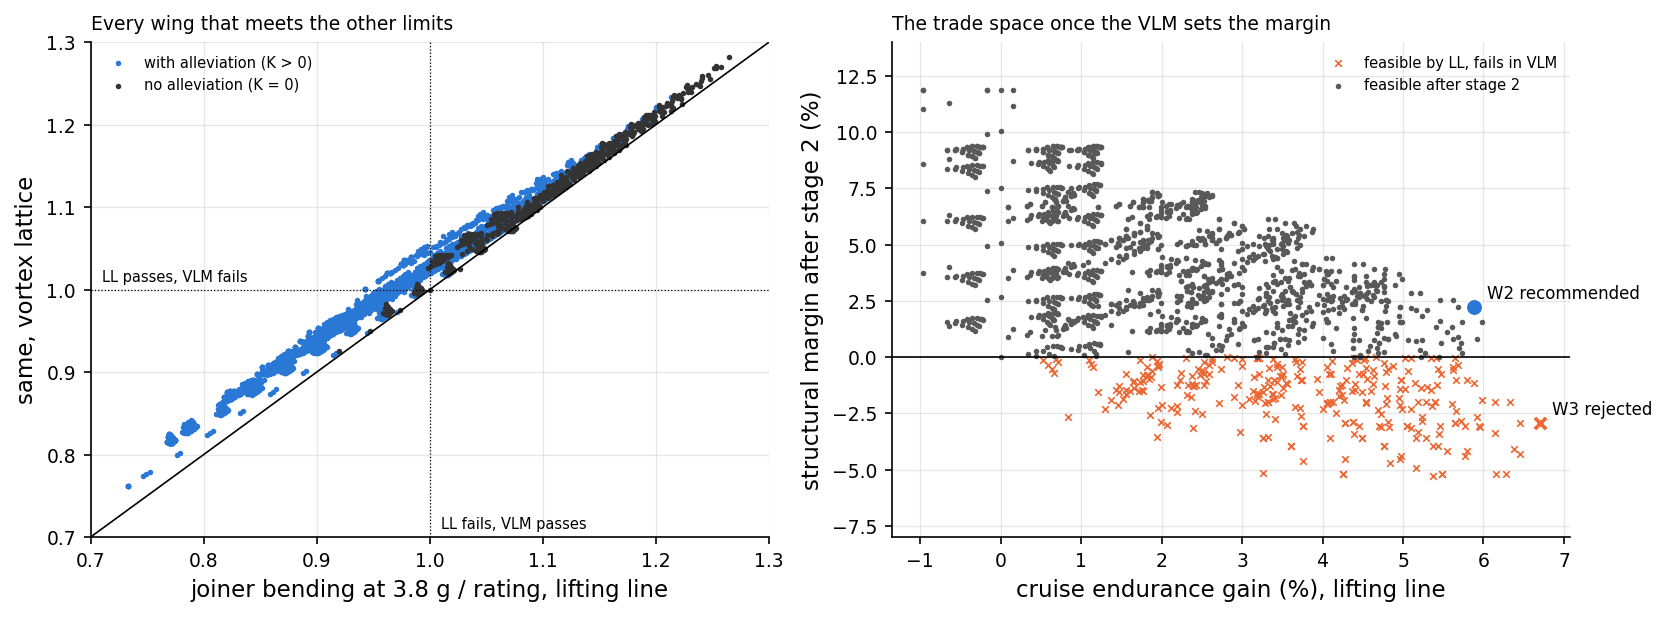

In [17]:
# the lifting line ranked 4,890 wings in seconds. here every one of them is flown again at the
# case that sizes the spar (+3.8 g at V_A, MTOW, alleviation on) in the vortex lattice, which
# resolves the 3-d flow around the deflected aileron that the lifting line simplifies.
# about 1 hour on a Kaggle CPU. progress is saved to a file every 50 wings, so if the session
# drops, run this cell again and it carries on where it stopped
for key in ("W0", "W3"):
    full, fast = bending(key, 3.8)[:2], bending_fast(key)[:2]
    print(f"{key}: full trim root {full[0]:.3f} joiner {full[1]:.3f} N m | 2-solve root {fast[0]:.3f} joiner {fast[1]:.3f} N m")
    assert all(abs(f/g - 1) < 1e-4 for f, g in zip(fast, full))
print("fast-method gate passed: the 2-solve answer equals the full trim within 0.01%")
 
os.makedirs("wingstudy/results", exist_ok=True)
RAW = "wingstudy/results/vlm_screen_raw.csv"
 
 
def geo(p):
    # wings with the same planform and the same aileron angle at 3.8 g have the same vlm mesh,
    # so each mesh is solved once (4,075 meshes for 4,890 wings)
    return (p[0], p[1], p[2], round(aileron(p, 3.8), 6))
 
 
done = {}
if os.path.exists(RAW):
    for r in csv.DictReader(open(RAW)):
        done[(float(r["s"]), float(r["lam"]), float(r["tw"]), float(r["ail"]))] = (float(r["root"]), float(r["join"]), float(r["alpha"]))
# resume: meshes already solved in an earlier run are read back, not solved again
 
can_pass = lambda r: all(f.startswith(("A1", "A2")) for f in r["failed"])
# a wing that fails a non-structural limit (stall speed, aileron stall, roll, extension
# length, mass, tip chord) stays failed whatever the vlm says. those are solved last, so the
# decision is ready early; they are still solved, for the method comparison
order = sorted(ROWS, key=lambda r: not can_pass(r))
todo, seen = [], set(done)
for r in order:
    g = geo(p_of(r))
    if g not in seen:
        seen.add(g)
        todo.append((g, p_of(r)))
print(f"{len(set(geo(p_of(r)) for r in ROWS))} meshes in total, {len(done)} already solved, {len(todo)} to go")
 
new = not os.path.exists(RAW)
f_raw = open(RAW, "a", newline="")
wr_raw = csv.writer(f_raw)
if new:
    wr_raw.writerow(["s", "lam", "tw", "ail", "root", "join", "alpha"])
t0 = time.time()
for i, (g, p) in enumerate(todo):
    root, join, alpha = bending_fast(p)
    done[g] = (root, join, alpha)
    wr_raw.writerow([*g, root, join, alpha])
    if (i + 1) % 50 == 0 or i + 1 == len(todo):
        f_raw.flush()
        el = time.time() - t0
        print(f"  {i + 1}/{len(todo)} meshes, {el/60:.1f} min, about {el/(i + 1)*(len(todo) - i - 1)/60:.0f} min left", flush=True)
f_raw.close()
 
# ---- the stage-2 verdict for every wing
R0v, J0v = done[geo(UAV["W0"])][:2]
CAP_ROOT, CAP_JOIN = STUDY["base"]["cap_root"], STUDY["base"]["cap_join"]
study.SCENARIO = "gla"
LL_CASES = study.cases(V_A)
# +3.8 g, -1.52 g, and the +-15 m/s gusts, as in the trade study
rows2 = []
for r in ROWS:
    p = p_of(r)
    rv = done[geo(p)][0]/R0v
    jv = done[geo(p)][1]/J0v
    # vortex-lattice 3.8 g bending against the baseline wing's in the same method
    L = {x["name"]: x for x in ll_wing(p).loads(LL_CASES, gla=True)}
    ro = max(abs(L[c]["Mroot"]) for c in L if c != "M+3.8")/CAP_ROOT
    jo = max(abs(L[c]["Mjoin"]) for c in L if c != "M+3.8")/CAP_JOIN
    # the other three cases stay lifting line: none of them sizes a feasible wing
    rr, rj = max(rv, ro), max(jv, jo)
    rows2.append(dict(s=r["s"], lam=r["lam"], tw=r["tw"], dc=r["dc"], K=r["K"],
                      gain_cruise=r["gain_cruise"], gain_loiter=r["gain_loiter"], pb2v=r["pb2v"],
                      ail_mean=r["ail_mean"], m_ext=r["m_ext"], VS_mtow=r["VS_mtow"], dDi=r["dDi"],
                      join38_LL=L["M+3.8"]["Mjoin"]/CAP_JOIN, root38_LL=L["M+3.8"]["Mroot"]/CAP_ROOT,
                      join38_VLM=jv, root38_VLM=rv, margin_LL=r["margin"], feasible_LL=r["feasible"],
                      margin=100*(1 - max(rr, rj)), other_limits_ok=can_pass(r),
                      feasible=can_pass(r) and max(rr, rj) <= 1.0 + 1e-9))
# 'margin' and 'feasible' now carry the stage-2 values, so rank.py scores them unchanged
 
F2 = [r for r in rows2 if r["feasible"]]
sc2 = rank.score(F2, rank.W_PRIORITY)
o2 = np.argsort(-sc2)
for r in rows2:
    r["score2"] = ""
for i, s in zip(o2, sc2[o2]):
    F2[i]["score2"] = round(float(s), 4)
WIN = F2[o2[0]]
lost = [r for r in rows2 if r["feasible_LL"] and not r["feasible"]]
saved = [r for r in rows2 if r["feasible"] and not r["feasible_LL"]]
w3row = next(r for r in rows2 if p_of(r) == LL_TOP)
print(f"\nstage 2 (vortex lattice at 3.8 g): {len(F2)} of {len(ROWS)} wings feasible")
print(f"  {len(lost)} wings the lifting line passed now fail; {len(saved)} wings it failed now pass")
print(f"  the lifting-line winner {LL_TOP}: joiner {w3row['join38_LL']:.3f} (LL) -> {w3row['join38_VLM']:.3f} (VLM), "
      f"{'FAILS' if not w3row['feasible'] else 'passes'}")
print("-- top 10 under the priority weights, using stage-2 margins")
for i in o2[:10]:
    print(f"  {sc2[i]:.3f}  {rank.fmt(F2[i])}  (LL margin {F2[i]['margin_LL']:+.1f}%)")
 
rng = np.random.default_rng(1)
Z = rank.norm_matrix(F2)
alpha = 30*np.array([rank.W_PRIORITY[k] for k, _, _ in rank.OBJ])
wins = {}
for _ in range(4000):
    i = int(np.argmax(Z @ rng.dirichlet(alpha)))
    wins[rank.key(F2[i])] = wins.get(rank.key(F2[i]), 0) + 1
print("-- monte-carlo win share (4000 weight draws around the priority set)")
for k, v in sorted(wins.items(), key=lambda x: -x[1])[:5]:
    print(f"  {100*v/4000:5.1f}%  {k}")
for name, wts in rank.W_ALT.items():
    print(f"  {name:16s} winner: {rank.key(F2[int(np.argmax(rank.score(F2, wts)))])}")
 
UAV["W2"] = p_of(WIN)
UAV = {k: UAV[k] for k in ("W0", "W2", "W3", "W6")}
LABEL["W2"] = "W2 recommended"
LABEL["W3"] = "W3 rejected" if not w3row["feasible"] else "W3 LL rank 1"
print(f"\nRECOMMENDED WING W2 = {UAV['W2']}  (span ratio, taper, tip twist, cruise aileron, gain)")
geometry_gate(["W2"])
 
with open("wingstudy/results/stage2_all_wings.csv", "w", newline="") as f:
    wr = csv.DictWriter(f, fieldnames=list(rows2[0]))
    wr.writeheader()
    wr.writerows(rows2)
json.dump(dict(W2=UAV["W2"], W3=UAV["W3"], W3_rejected=not w3row["feasible"],
               n_feasible_LL=len(F_LL), n_feasible_VLM=len(F2), n_lost=len(lost), n_saved=len(saved),
               W2_row=WIN, W3_row=w3row, R0_vlm=R0v, J0_vlm=J0v),
          open("wingstudy/results/selection.json", "w"), indent=1, default=float)
# final.py (last cell) reads this file to draw the recommended wing
 
# ---- figure: what stage 2 changed
fig, axs = plt.subplots(1, 2, figsize=(11, 4.0))
cand = [r for r in rows2 if r["other_limits_ok"]]
for K0, col, lab in [(True, "#2a78d6", "with alleviation (K > 0)"), (False, "0.2", "no alleviation (K = 0)")]:
    sel = [r for r in cand if (r["K"] > 0) == K0]
    axs[0].scatter([r["join38_LL"] for r in sel], [r["join38_VLM"] for r in sel], s=7, lw=0, color=col, label=lab)
# no-alleviation wings drawn last, so they show on top: they sit on the diagonal (the methods agree),
# the alleviated wings sit above it (the lifting line overstates the aileron's relief)
lim = [0.7, 1.3]
axs[0].plot(lim, lim, color="k", lw=0.8)
axs[0].axhline(1, color="k", lw=0.6, ls=":")
axs[0].axvline(1, color="k", lw=0.6, ls=":")
axs[0].text(0.71, 1.01, "LL passes, VLM fails", fontsize=7)
axs[0].text(1.01, 0.71, "LL fails, VLM passes", fontsize=7)
axs[0].set_xlim(lim); axs[0].set_ylim(lim)
axs[0].set_xlabel("joiner bending at 3.8 g / rating, lifting line")
axs[0].set_ylabel("same, vortex lattice")
axs[0].set_title("Every wing that meets the other limits", fontsize=9, loc="left")
axs[0].legend(fontsize=7, loc="upper left")
 
axs[1].scatter([r["gain_cruise"] for r in lost], [r["margin"] for r in lost], s=10, marker="x", lw=0.8,
               color="#eb6834", label="feasible by LL, fails in VLM")
axs[1].scatter([r["gain_cruise"] for r in F2], [r["margin"] for r in F2], s=7, lw=0, color="0.35",
               label="feasible after stage 2")
for key, mk_, col in [("W2", "o", "#2a78d6"), ("W3", "X", "#eb6834")]:
    rr = WIN if key == "W2" else w3row
    axs[1].scatter([rr["gain_cruise"]], [rr["margin"]], s=70, marker=mk_, color=col, edgecolor="white", lw=1.2, zorder=5)
    axs[1].annotate(LABEL[key], (rr["gain_cruise"], rr["margin"]), xytext=(6, 4), textcoords="offset points", fontsize=8)
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set_ylim(-8, 14)
axs[1].set_xlabel("cruise endurance gain (%), lifting line")
axs[1].set_ylabel("structural margin after stage 2 (%)")
axs[1].set_title("The trade space once the VLM sets the margin", fontsize=9, loc="left")
axs[1].legend(fontsize=7, loc="upper right")
save_fig(fig, "stage2_vlm_screen")

## 16. Cruise check: span efficiency and induced drag, vortex lattice vs lifting line


            wing  alpha     C_L   e VLM    e LL  Di VLM   Di LL  Di near lever VLM  lever LL
     W0 baseline   6.08  0.7414  0.9771  0.9693   3.042   3.067    2.971    0.7225    0.7286
  W2 recommended   5.55  0.7094  0.9962  0.9946   2.416   2.420    2.377    0.7856    0.7886
     W3 rejected   5.47  0.7028  0.9949  0.9930   2.322   2.327    2.287    0.7968    0.7990
   W6 twist-only   6.48  0.7028  0.9128  0.8901   2.531   2.596    2.501    0.7360    0.7345

            wing   dDi VLM   dDi LL   diff
     W0 baseline     +0.0%    +0.0%   +0.0
  W2 recommended    -20.6%   -21.1%   +0.5
     W3 rejected    -23.7%   -24.1%   +0.5
   W6 twist-only    -16.8%   -15.4%   -1.4
cruise gate passed: induced-drag changes agree within 2 points


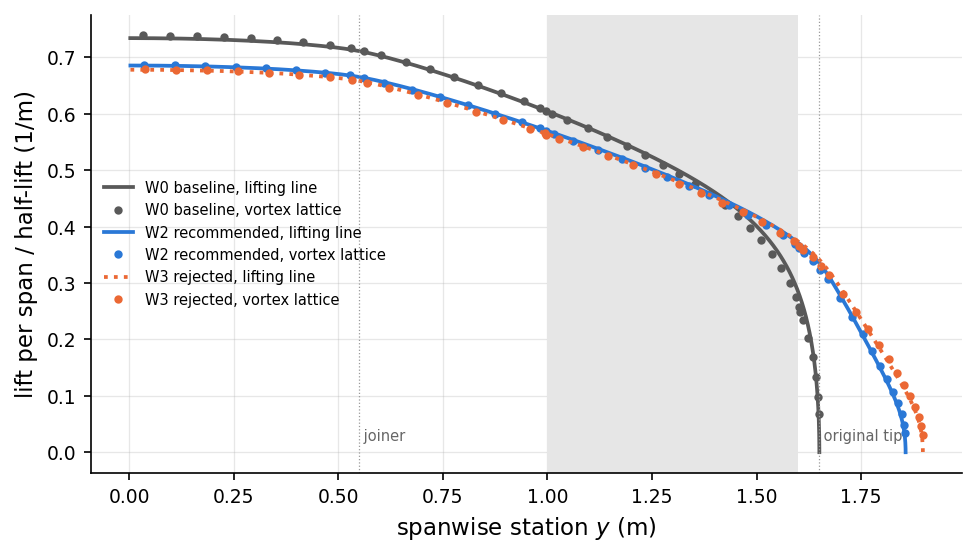

In [18]:
cruise = {}
print(f"\n{'wing':>16} {'alpha':>6} {'C_L':>7} {'e VLM':>7} {'e LL':>7} {'Di VLM':>7} {'Di LL':>7} "
      f"{'Di near':>8} {'lever VLM':>9} {'lever LL':>9}")
for key in UAV:
    d = uav_design(key)
    ap = build_wing(d)
    CL = cruise_CL(d)
    vlm, r, alpha = trim(ap, CL)
    y, G, dy = spanload(vlm, d)
    e_v = span_eff(fit_A(y, G, d["span"]))
    Di_v = Q_CR*d["S"]*CL**2/(np.pi*d["AR"]*e_v)
    # far-field induced drag from the fitted spanload, the same quantity the lifting line gives
    Di_near = Q_CR*d["S"]*scalar(r["CD"])
    # aerosandbox's own near-field drag, printed for transparency
 
    w = ll_wing(key)
    ll = w.drag(M_CR + d["m_ext"], V_CR)
    Lp = w.lift_per_span(ll["A"], V_CR)
    half = w.yf >= 0
    lev_ll = w.moment_at(Lp, 0.0)/np.trapezoid(Lp[half], w.yf[half])
    # lifting-line values for the same wing at the same lift
 
    cruise[key] = dict(d=d, vlm=vlm, alpha=alpha, CL=scalar(r["CL"]), e_vlm=e_v, e_ll=ll["e"],
                       Di_vlm=Di_v, Di_ll=ll["Di"], Di_near=Di_near, lev_vlm=lever(vlm, d), lev_ll=lev_ll,
                       Dw_ll=ll["Dw"], w=w, ll=ll)
    c = cruise[key]
    print(f"{LABEL[key]:>16} {alpha:>6.2f} {c['CL']:>7.4f} {e_v:>7.4f} {ll['e']:>7.4f} {Di_v:>7.3f} "
          f"{ll['Di']:>7.3f} {Di_near:>8.3f} {c['lev_vlm']:>9.4f} {lev_ll:>9.4f}")
    assert abs(c["CL"]/CL - 1) < 1e-3
 
print(f"\n{'wing':>16} {'dDi VLM':>9} {'dDi LL':>8} {'diff':>6}")
for key in UAV:
    dv = 100*(cruise[key]["Di_vlm"]/cruise["W0"]["Di_vlm"] - 1)
    dl = 100*(cruise[key]["Di_ll"]/cruise["W0"]["Di_ll"] - 1)
    cruise[key]["dDi_vlm"], cruise[key]["dDi_ll"] = dv, dl
    print(f"{LABEL[key]:>16} {dv:>+8.1f}% {dl:>+7.1f}% {dv - dl:>+6.1f}")
    assert abs(dv - dl) < 2.0
print("cruise gate passed: induced-drag changes agree within 2 points")
 
 
# spanload figure: lifting line (line) against vortex lattice (dots), baseline, recommended, rejected
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for key, col, ls in [("W0", "0.35", "-"), ("W2", "#2a78d6", "-"), ("W3", "#eb6834", ":")]:
    c = cruise[key]
    w, half = c["w"], c["w"].yf >= 0
    Lp = w.lift_per_span(c["ll"]["A"], V_CR)[half]
    ax.plot(w.yf[half], Lp/np.trapezoid(Lp, w.yf[half]), color=col, lw=1.8, ls=ls,
            label=f"{LABEL[key]}, lifting line")
    y, G, dy = spanload(c["vlm"], c["d"])
    ax.plot(y, G/np.sum(G*dy), "o", ms=3, color=col, label=f"{LABEL[key]}, vortex lattice")
    # both normalised by their own half-lift, so the curves compare shape at equal lift
for yy, txt in [(W.Y_CS, "joiner"), (W.B0/2, "original tip")]:
    ax.axvline(yy, color="0.6", lw=0.6, ls=":")
    ax.text(yy, 0.02, " " + txt, fontsize=7, color="0.4")
ax.axvspan(*W.AIL, color="0.9", lw=0)
ax.set_xlabel("spanwise station $y$ (m)")
ax.set_ylabel("lift per span / half-lift (1/m)")
ax.legend(fontsize=7)
save_fig(fig, "uav_spanload_ll_vs_vlm")

## 17. Panel convergence check

In [19]:
print(f"\n{'sections':>9} {'chordwise':>10} {'Di (N)':>8} {'root lever':>11}")
conv = []
for n_sec, cw in [(41, 10), (81, 10), (41, 20)]:
    d = uav_design("W3", n=n_sec)
    vlm, r, _ = trim(build_wing(d), cruise_CL(d), chordwise=cw)
    y, G, dy = spanload(vlm, d)
    CL = cruise_CL(d)
    Di = Q_CR*d["S"]*CL**2/(np.pi*d["AR"]*span_eff(fit_A(y, G, d["span"])))
    conv.append((Di, lever(vlm, d)))
    print(f"{len(d['eta']):>9} {cw:>10} {Di:>8.4f} {conv[-1][1]:>11.5f}")
for Di, lev in conv[1:]:
    assert abs(Di/conv[0][0] - 1) < 0.01 and abs(lev/conv[0][1] - 1) < 0.01
print("convergence gate passed: doubling either panel count moves Di and the root lever by < 1%")


 sections  chordwise   Di (N)  root lever
       47         10   2.3222     0.79681
       87         10   2.3234     0.79603
       47         20   2.3222     0.79681
convergence gate passed: doubling either panel count moves Di and the root lever by < 1%


## 18. Structural check: root and joiner bending at 3.8 g, alleviation on and off

In [20]:
cases = [("W0", True), ("W2", False), ("W2", True), ("W3", False), ("W3", True), ("W6", True)]
# w6 has no alleviation gain, so 'True' just keeps its -6 deg cruise trim
sizing = {}
for key, al in cases:
    sizing[(key, al)] = dict(vlm=bending(key, 3.8, al)[:2], ll=bending_ll(key, 3.8, al))
R0v, J0v = sizing[("W0", True)]["vlm"]
R0l, J0l = sizing[("W0", True)]["ll"]
print(f"\n3.8 g at V_A = {V_A:.1f} m/s, MTOW, ratios against the baseline in the same case")
print(f"{'wing':>16} {'alleviation':>11} {'aileron':>8} {'root VLM':>9} {'root LL':>8} "
      f"{'joiner VLM':>11} {'joiner LL':>10} {'VLM verdict':>12} {'LL verdict':>11}")
for (key, al), s in sizing.items():
    rv, jv = s["vlm"][0]/R0v, s["vlm"][1]/J0v
    rl, jl = s["ll"][0]/R0l, s["ll"][1]/J0l
    s.update(rv=rv, jv=jv, rl=rl, jl=jl)
    verdict = lambda r, j: "passes" if max(r, j) <= 1.0 else "FAILS"
    print(f"{LABEL[key]:>16} {('on' if al else 'off'):>11} {aileron(key, 3.8, al):>+7.1f}° {rv:>9.3f} "
          f"{rl:>8.3f} {jv:>11.3f} {jl:>10.3f} {verdict(rv, jv):>12} {verdict(rl, jl):>11}")
print(f"baseline moments: root {R0v:.1f} N m (LL {R0l:.1f}), joiner {J0v:.1f} N m (LL {J0l:.1f})")
 
for key, al in [("W2", False), ("W3", False), ("W6", True)]:
    s = sizing[(key, al)]
    assert abs(s["rv"] - s["rl"]) < 0.03 and abs(s["jv"] - s["jl"]) < 0.03
print("planform gate passed: with no alleviation, the two methods agree on bending within 0.03")
# with the ailerons fixed, the bending change comes from the longer planform alone, and the
# methods agree. the alleviation cases differ more, so they are judged separately below
 
for key in ("W2", "W3"):
    on, off = sizing[(key, True)], sizing[(key, False)]
    relief_v = 100*(1 - on["vlm"][1]/off["vlm"][1])
    relief_l = 100*(1 - on["ll"][1]/off["ll"][1])
    print(f"aileron relief of joiner bending on {key}: vortex lattice {relief_v:.1f}%, lifting line {relief_l:.1f}%")
# a deflected aileron is a sudden change of twist over 0.6 m of span. lifting-line theory treats
# each strip as 2-d and handles such steps poorly; the vortex lattice resolves the 3-d flow
# around the aileron ends. so the vortex-lattice verdict is the one to trust for these cases:
# the lifting line overstates the relief, which is why stage 2 rejected the lifting-line winner


3.8 g at V_A = 36.6 m/s, MTOW, ratios against the baseline in the same case
            wing alleviation  aileron  root VLM  root LL  joiner VLM  joiner LL  VLM verdict  LL verdict
     W0 baseline          on    +0.0°     1.000    1.000       1.000      1.000       passes      passes
  W2 recommended         off    +0.0°     1.093    1.088       1.207      1.196        FAILS       FAILS
  W2 recommended          on   -20.0°     0.978    0.958       0.977      0.937       passes      passes
     W3 rejected         off    +0.0°     1.110    1.104       1.246      1.232        FAILS       FAILS
     W3 rejected          on   -20.0°     1.002    0.973       1.029      0.976        FAILS      passes
   W6 twist-only          on    -6.0°     1.060    1.050       1.143      1.122        FAILS       FAILS
baseline moments: root 289.4 N m (LL 291.5), joiner 113.6 N m (LL 115.3)
planform gate passed: with no alleviation, the two methods agree on bending within 0.03
aileron relief of joiner be

## 19. Root bending vs load factor: the flight-test prediction

                       W0 baseline: n=-1.52 -> -0.399  n=+1.00 -> 0.264  n=+2.00 -> 0.527  n=+3.00 -> 0.790  n=+3.80 -> 1.000
   W2 recommended, alleviation off: n=-1.52 -> -0.448  n=+1.00 -> 0.282  n=+2.00 -> 0.571  n=+3.00 -> 0.861  n=+3.80 -> 1.093
    W2 recommended, alleviation on: n=-1.52 -> -0.334  n=+1.00 -> 0.282  n=+2.00 -> 0.525  n=+3.00 -> 0.773  n=+3.80 -> 0.978
       W3 rejected, alleviation on: n=-1.52 -> -0.346  n=+1.00 -> 0.285  n=+2.00 -> 0.535  n=+3.00 -> 0.790  n=+3.80 -> 1.002


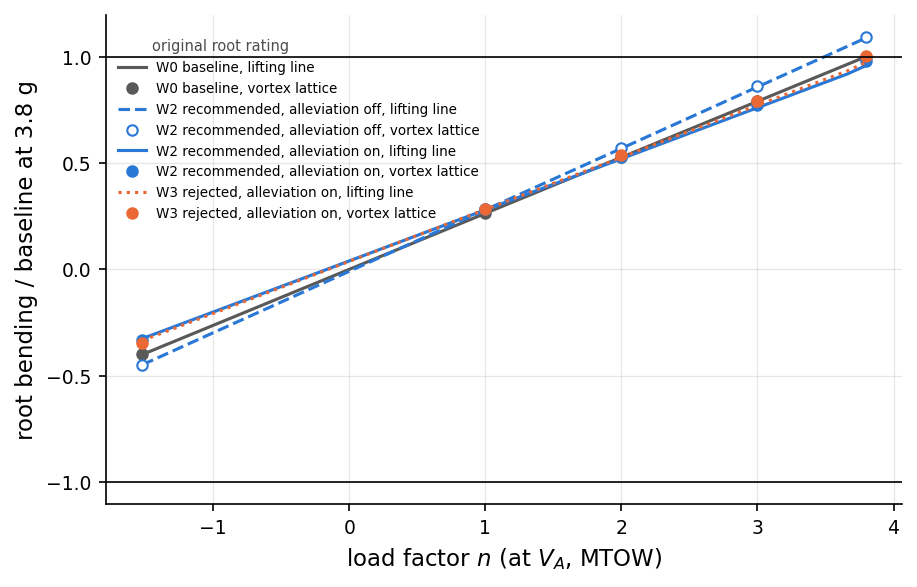

In [21]:
ns_v = [-1.52, 1.0, 2.0, 3.0, 3.8]
ns_l = np.linspace(-1.52, 3.8, 40)
fig, ax = plt.subplots(figsize=(6.0, 3.8))
for key, al, col, ls in [("W0", True, "0.35", "-"),
                         ("W2", False, "#2a78d6", "--"),
                         ("W2", True, "#2a78d6", "-"),
                         ("W3", True, "#eb6834", ":")]:
    lab = LABEL[key] if key == "W0" else f"{LABEL[key]}, alleviation {'on' if al else 'off'}"
    ax.plot(ns_l, [bending_ll(key, n, al)[0]/R0l for n in ns_l], ls, color=col, lw=1.5,
            label=f"{lab}, lifting line")
    pts = [bending(key, n, al)[0]/R0v for n in ns_v]
    ax.plot(ns_v, pts, "o", color=col, ms=5, mfc="white" if not al else col,
            label=f"{lab}, vortex lattice")
    print(f"{lab:>34}: " + "  ".join(f"n={n:+.2f} -> {p:.3f}" for n, p in zip(ns_v, pts)))
ax.axhline(1, color="k", lw=0.8)
ax.axhline(-1, color="k", lw=0.8)
ax.text(-1.45, 1.03, "original root rating", fontsize=7, color="0.3")
ax.set_xlabel("load factor $n$ (at $V_A$, MTOW)")
ax.set_ylabel("root bending / baseline at 3.8 g")
ax.legend(fontsize=6.5, loc="upper left", bbox_to_anchor=(0, 0.93))
save_fig(fig, "uav_bending_vs_n")
# without alleviation the longer wing's line is steeper and crosses the rating before 3.8 g;
# with alleviation the slope drops and it stays under. the strain-vs-n line a flight test measures

## 20. Stage 3: viscous drag check (AeroBuildup)

In [22]:
def trim_ab(airplane, CL_target, n_iter=4):
    # aerobuildup is nonlinear in alpha (viscous), so iterate the secant a little longer
    run = lambda a: asb.AeroBuildup(airplane=airplane,
                                    op_point=asb.OperatingPoint(velocity=V_CR, alpha=a)).run()
    a0, a1 = 3.0, 7.0
    c0, c1 = scalar(run(a0)["CL"]), scalar(run(a1)["CL"])
    for _ in range(n_iter):
        a0, c0, a1 = a1, c1, a1 + (CL_target - c1)*(a1 - a0)/(c1 - c0)
        r = run(a1)
        c1 = scalar(r["CL"])
    return r, a1
 
 
D_NW = 0.5*RHO*V_CR**2*0.014757
# non-wing drag (fuselage, booms, tail) = 4.38 N at cruise, calibrated in the trade study from an
# assumed aircraft l/d of 18. identical for every wing, so it only scales the endurance percentages
viscous = {}
print(f"\n{'wing':>16} {'alpha':>6} {'C_L':>7} {'wing D AB':>10} {'wing D LL':>10} {'dD AB':>7} "
      f"{'dD LL':>7} {'endurance AB':>13} {'endurance LL':>13}")
for key in UAV:
    d = uav_design(key)
    r, alpha = trim_ab(build_wing(d), cruise_CL(d))
    viscous[key] = dict(D_ab=scalar(r["D"]), D_ll=cruise[key]["Dw_ll"], alpha=alpha, CL=scalar(r["CL"]))
for key in UAV:
    v, b = viscous[key], viscous["W0"]
    v["dD_ab"] = 100*(v["D_ab"]/b["D_ab"] - 1)
    v["dD_ll"] = 100*(v["D_ll"]/b["D_ll"] - 1)
    v["end_ab"] = 100*((b["D_ab"] + D_NW)/(v["D_ab"] + D_NW) - 1)
    v["end_ll"] = 100*((b["D_ll"] + D_NW)/(v["D_ll"] + D_NW) - 1)
    # cruise endurance gain at fixed speed: power = drag x speed, battery and efficiency unchanged
    print(f"{LABEL[key]:>16} {v['alpha']:>6.2f} {v['CL']:>7.4f} {v['D_ab']:>10.3f} {v['D_ll']:>10.3f} "
          f"{v['dD_ab']:>+6.1f}% {v['dD_ll']:>+6.1f}% {v['end_ab']:>+12.1f}% {v['end_ll']:>+12.1f}%")
assert all(viscous[k]["D_ab"] < viscous["W0"]["D_ab"] for k in ("W2", "W3"))
# both leading retrofits lower wing drag in aerobuildup too
assert (viscous["W3"]["D_ab"] < viscous["W2"]["D_ab"]) == (viscous["W3"]["D_ll"] < viscous["W2"]["D_ll"])
# and the two methods put the two leading wings in the same drag order
gap = np.mean([viscous[k]["end_ll"] - viscous[k]["end_ab"] for k in ("W2", "W3")])
print(f"viscous gate passed. aerobuildup's endurance gains are {gap:.1f} points smaller on average:")
print("its own profile-drag and induced-drag models give a higher baseline wing drag, so the")
print("same absolute saving is a smaller fraction. quote the aerobuildup numbers as the conservative ones")
# w6 ranks differently in the two methods (aerobuildup charges its washout and up-aileron less),
# but it fails the structural check in both, so the difference does not change any decision


            wing  alpha     C_L  wing D AB  wing D LL   dD AB   dD LL  endurance AB  endurance LL
     W0 baseline   5.04  0.7414      5.968      5.270   +0.0%   +0.0%         +0.0%         +0.0%
  W2 recommended   4.64  0.7094      5.537      4.735   -7.2%  -10.2%         +4.3%         +5.9%
     W3 rejected   4.57  0.7028      5.445      4.665   -8.8%  -11.5%         +5.3%         +6.7%
   W6 twist-only   5.68  0.7028      5.540      4.970   -7.2%   -5.7%         +4.3%         +3.2%
viscous gate passed. aerobuildup's endurance gains are 1.5 points smaller on average:
its own profile-drag and induced-drag models give a higher baseline wing drag, so the
same absolute saving is a smaller fraction. quote the aerobuildup numbers as the conservative ones


## 21. Results table and summary figure

{'wing': 'W0 baseline', 'span_m': 3.3, 'dDi_LL': 0.0, 'dDi_VLM': 0.0, 'dDwing_LL': 0.0, 'dDwing_AB': 0.0, 'endurance_LL': 0.0, 'endurance_AB': 0.0, 'root_LL': 1.0, 'root_VLM': 1.0, 'joiner_LL': 1.0, 'joiner_VLM': 1.0, 'e_LL': 0.9693, 'e_VLM': 0.9771}
{'wing': 'W2 recommended', 'span_m': 3.712, 'dDi_LL': -21.09, 'dDi_VLM': -20.59, 'dDwing_LL': -10.17, 'dDwing_AB': -7.22, 'endurance_LL': 5.88, 'endurance_AB': 4.35, 'root_LL': 0.958, 'root_VLM': 0.978, 'joiner_LL': 0.937, 'joiner_VLM': 0.977, 'e_LL': 0.9946, 'e_VLM': 0.9962}
{'wing': 'W3 rejected', 'span_m': 3.795, 'dDi_LL': -24.13, 'dDi_VLM': -23.67, 'dDwing_LL': -11.49, 'dDwing_AB': -8.77, 'endurance_LL': 6.7, 'endurance_AB': 5.33, 'root_LL': 0.973, 'root_VLM': 1.002, 'joiner_LL': 0.976, 'joiner_VLM': 1.029, 'e_LL': 0.993, 'e_VLM': 0.9949}
{'wing': 'W6 twist-only', 'span_m': 3.795, 'dDi_LL': -15.36, 'dDi_VLM': -16.81, 'dDwing_LL': -5.69, 'dDwing_AB': -7.18, 'endurance_LL': 3.21, 'endurance_AB': 4.32, 'root_LL': 1.05, 'root_VLM': 1.06, '

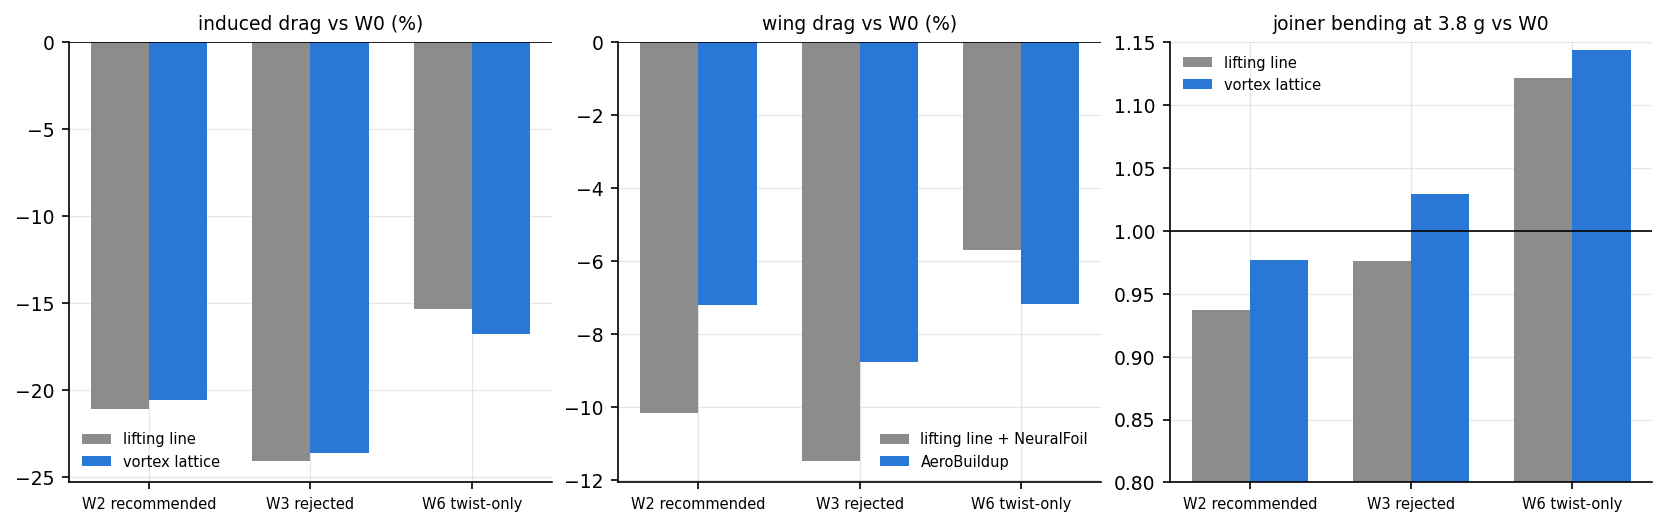

In [23]:
rows = []
for key in UAV:
    s = sizing[(key, True)]
    rows.append(dict(wing=LABEL[key], span_m=round(uav_design(key)["span"], 3),
                     dDi_LL=round(float(cruise[key]["dDi_ll"]), 2), dDi_VLM=round(float(cruise[key]["dDi_vlm"]), 2),
                     dDwing_LL=round(float(viscous[key]["dD_ll"]), 2), dDwing_AB=round(viscous[key]["dD_ab"], 2),
                     endurance_LL=round(float(viscous[key]["end_ll"]), 2), endurance_AB=round(viscous[key]["end_ab"], 2),
                     root_LL=round(float(s["rl"]), 3), root_VLM=round(float(s["rv"]), 3),
                     joiner_LL=round(float(s["jl"]), 3), joiner_VLM=round(float(s["jv"]), 3),
                     e_LL=round(float(cruise[key]["e_ll"]), 4), e_VLM=round(cruise[key]["e_vlm"], 4)))
for key in ("W2", "W3"):
    s = sizing[(key, False)]
    rows.append(dict(wing=f"{LABEL[key]}, alleviation off", span_m=round(uav_design(key)["span"], 3),
                     root_LL=round(float(s["rl"]), 3), root_VLM=round(float(s["rv"]), 3),
                     joiner_LL=round(float(s["jl"]), 3), joiner_VLM=round(float(s["jv"]), 3)))
# the alleviation-off rows: evidence that span alone overloads the joiner and alleviation fixes it
os.makedirs("results", exist_ok=True)
with open("results/uav_method_comparison.csv", "w", newline="") as f:
    wr = csv.DictWriter(f, fieldnames=list(rows[0]))
    wr.writeheader()
    wr.writerows(rows)
for r in rows:
    print(r)
 
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
keys = ["W2", "W3", "W6"]
x = np.arange(len(keys))
for ax, (a, b, la, lb, title) in zip(axes, [
        ("dDi_ll", "dDi_vlm", "lifting line", "vortex lattice", "induced drag vs W0 (%)"),
        ("dD_ll", "dD_ab", "lifting line + NeuralFoil", "AeroBuildup", "wing drag vs W0 (%)"),
        ("jl", "jv", "lifting line", "vortex lattice", "joiner bending at 3.8 g vs W0")]):
    src = cruise if a.startswith("dDi") else viscous if a.startswith("dD_") else None
    va = [src[k][a] if src else sizing[(k, True)][a] for k in keys]
    vb = [src[k][b] if src else sizing[(k, True)][b] for k in keys]
    ax.bar(x - 0.18, va, 0.36, color="0.55", label=la)
    ax.bar(x + 0.18, vb, 0.36, color="#2a78d6", label=lb)
    ax.set_xticks(x, [LABEL[k] for k in keys], fontsize=7)
    ax.set_title(title, fontsize=9)
    ax.axhline(1.0 if a == "jl" else 0.0, color="k", lw=0.8)
    ax.legend(fontsize=7)
axes[2].set_ylim(0.8, 1.15)
save_fig(fig, "uav_method_comparison")
# three independent checks of the leading wings: same drag ranking, and the joiner verdicts

## 22. Run final outputs

In [24]:
!cd wingstudy && python final.py > results/final_log.txt && cat results/final_log.txt
# reads wingstudy/results/selection.json from cell 16. figures in wingstudy/figures,
# csvs in wingstudy/results

passive  W0 Baseline                      feas=True  cruise  +0.00% loiter  +0.00% Di   +0.0% Dp  +0.0% root 1.000 join 1.000 pb2v 0.144 ail 0.919 m 0.00 span 3.300 
passive  W1 Software-only alleviation     feas=True  cruise  +0.00% loiter  +0.00% Di   +0.0% Dp  +0.0% root 0.866 join 0.810 pb2v 0.144 ail 0.919 m 0.00 span 3.300 
passive  W2 Recommended                   feas=False cruise  +5.88% loiter +10.16% Di  -21.1% Dp  +5.0% root 0.958 join 1.023 pb2v 0.132 ail 0.986 m 0.22 span 3.712 A2 joiner
passive  W3 Lifting-line rank 1, rejected by VLM feas=False cruise  +6.70% loiter +11.89% Di  -24.1% Dp  +6.1% root 0.973 join 1.063 pb2v 0.137 ail 0.989 m 0.24 span 3.795 A2 joiner
passive  W4 Max loiter                    feas=False cruise  +6.27% loiter +11.91% Di  -24.3% Dp  +8.0% root 0.984 join 1.076 pb2v 0.129 ail 0.989 m 0.27 span 3.877 A2 joiner
passive  W5 Max roll authority            feas=True  cruise  +1.24% loiter  +1.85% Di   -4.7% Dp  +1.2% root 0.961 join 0.927 pb2v 0.149

## 23. Recommended wing W2: planform, twist, alleviation schedule and spec sheet

span (m)                                   3.7125
span ratio s                               1.125
wing area (m2)                             0.8357
aspect ratio                               16.49
extension length per side (mm)             206.3
extension taper (tip/root chord)           0.4
extension tip chord (mm)                   63.4
extension tip twist (deg)                  -4
added mass incl. fittings (kg)             0.217
cruise aileron trim (deg)                  0
alleviation gain (deg per g)               7.5
aileron full-up load factor                3.67
3.8 g root bending / rating (VLM)          0.978
3.8 g joiner bending / rating (VLM)        0.977
cruise endurance gain, lifting line (%)    5.88
cruise endurance gain, AeroBuildup (%)     4.35
induced drag change, VLM (%)               -20.59


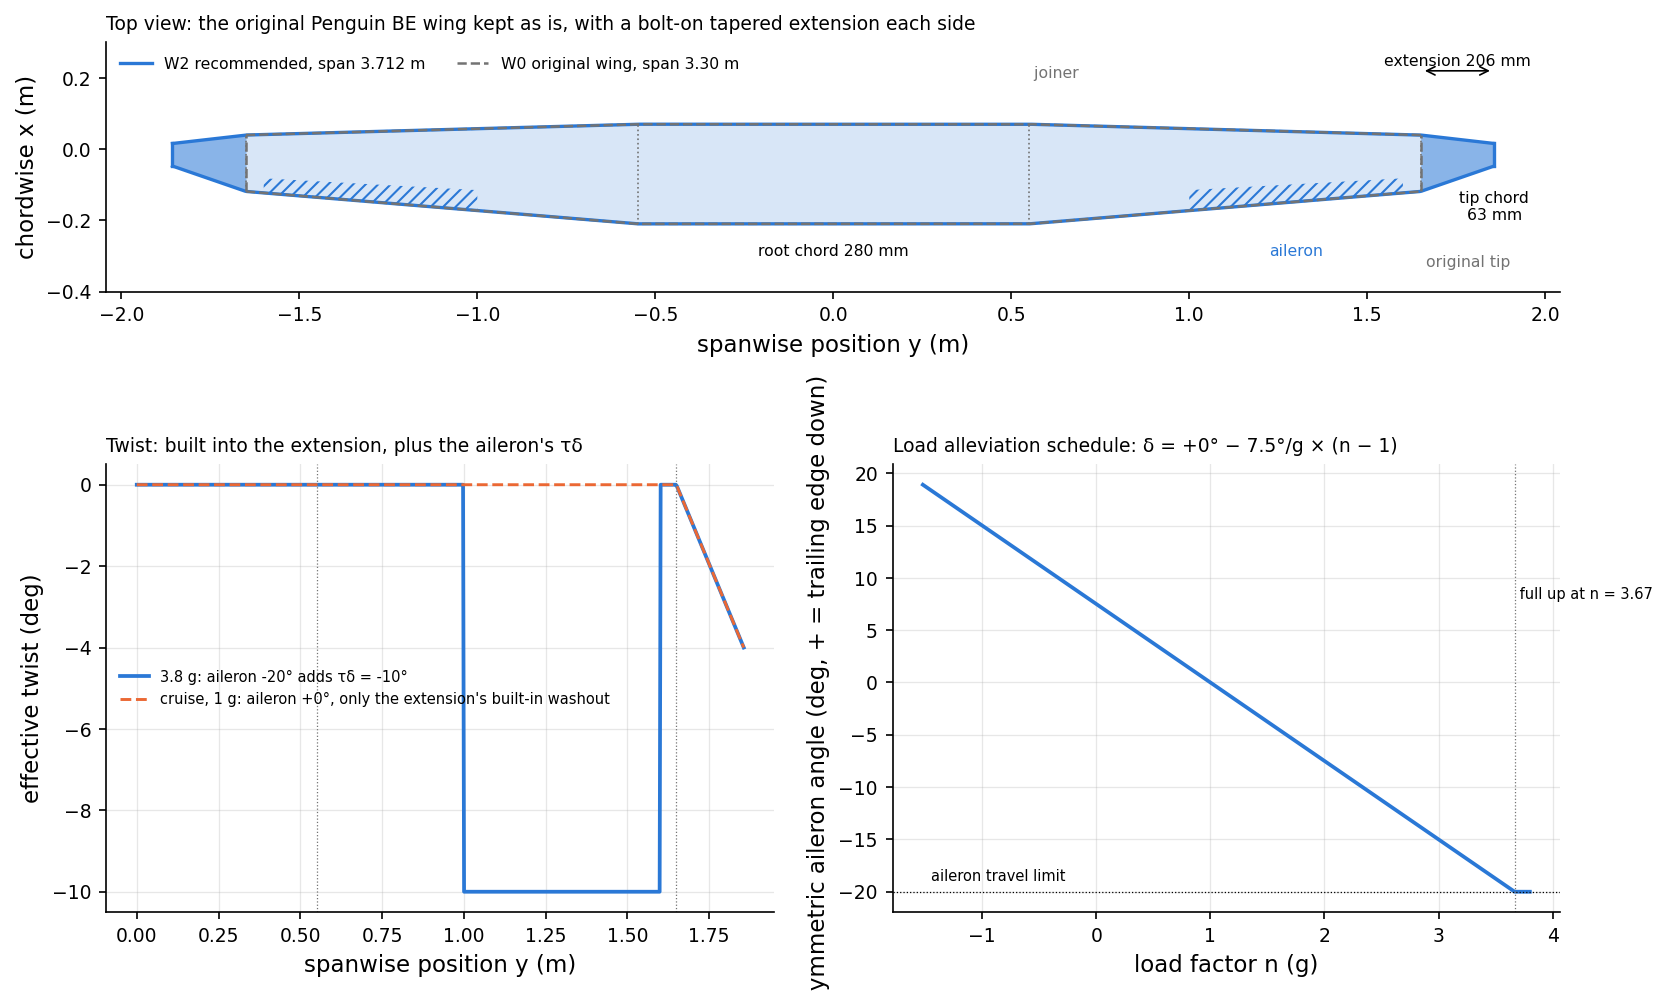

In [25]:
w2, w0 = ll_wing("W2"), ll_wing("W0")
s, lam, tw, dc, K = UAV["W2"]
half2, half0 = w2.b/2, w0.b/2
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "0.45"
 
fig = plt.figure(figsize=(11, 7.2))
gs = fig.add_gridspec(2, 2, height_ratios=[1.15, 1])
ax = fig.add_subplot(gs[0, :])
# top view: flight direction is up, quarter-chord line straight along y (as in the model)
y = np.linspace(-half2, half2, 801)
c = w2.chord(y)
ax.fill_between(y, -0.75*c, 0.25*c, color=BLUE, alpha=0.18, lw=0)
ax.plot(y, 0.25*c, color=BLUE, lw=1.6, label=f"W2 recommended, span {w2.b:.3f} m")
ax.plot(y, -0.75*c, color=BLUE, lw=1.6)
for side in (-1, 1):
    ye = side*np.linspace(half0, half2, 50)
    ce = w2.chord(ye)
    ax.fill_between(ye, -0.75*ce, 0.25*ce, color=BLUE, alpha=0.45, lw=0)
    # the bolt-on extension, darker
    ya = side*np.linspace(*W.AIL, 50)
    ca = w2.chord(ya)
    ax.fill_between(ya, -0.75*ca, -0.5*ca, facecolor="none", edgecolor=BLUE, hatch="////", lw=0)
    # aileron: aft 25% of the chord, 1.00-1.60 m from the centreline
    for yy in (W.Y_CS, half0):
        ax.plot([side*yy]*2, [-0.75*w2.chord(np.array([yy]))[0], 0.25*w2.chord(np.array([yy]))[0]],
                color=GREY, lw=0.8, ls=":")
    ax.plot([side*half2]*2, [-0.75*w2.chord(np.array([half2]))[0], 0.25*w2.chord(np.array([half2]))[0]], color=BLUE, lw=1.6)
y0 = np.linspace(-half0, half0, 801)
c0 = w0.chord(y0)
ax.plot(y0, 0.25*c0, color=GREY, lw=1.2, ls="--", label=f"W0 original wing, span {w0.b:.2f} m")
ax.plot(y0, -0.75*c0, color=GREY, lw=1.2, ls="--")
ax.plot([-half0, -half0], [-0.75*c0[0], 0.25*c0[0]], color=GREY, lw=1.2, ls="--")
ax.plot([half0, half0], [-0.75*c0[-1], 0.25*c0[-1]], color=GREY, lw=1.2, ls="--")
ct = float(w2.chord(np.array([half2]))[0])
ax.annotate("", xy=(half2, 0.22), xytext=(half0, 0.22), arrowprops=dict(arrowstyle="<->", lw=0.8))
ax.text((half0 + half2)/2, 0.235, f"extension {w2.dext*1000:.0f} mm", ha="center", fontsize=7.5)
ax.text(W.Y_CS, 0.20, " joiner", fontsize=7.5, color=GREY)
ax.text(half0, -0.33, " original tip", fontsize=7.5, color=GREY)
ax.text(1.30, -0.30, "aileron", ha="center", fontsize=7.5, color=BLUE)
ax.text(0, -0.30, f"root chord {W.C_ROOT*1000:.0f} mm", ha="center", fontsize=7.5)
ax.text(half2, -0.20, f"tip chord\n{ct*1000:.0f} mm", ha="center", fontsize=7.5)
ax.set_aspect("equal")
ax.set_ylim(-0.40, 0.30)
ax.set_xlabel("spanwise position y (m)")
ax.set_ylabel("chordwise x (m)")
ax.set_title("Top view: the original Penguin BE wing kept as is, with a bolt-on tapered extension each side", fontsize=9, loc="left")
ax.legend(fontsize=7.5, loc="upper left", ncol=2)
ax.grid(False)
 
ax = fig.add_subplot(gs[1, 0])
yh = np.linspace(0, half2, 600)
geo_tw = np.degrees(w2.twist(yh))
on_ail = ((yh >= W.AIL[0]) & (yh <= W.AIL[1])).astype(float)
ax.plot(yh, geo_tw + W.TAU*aileron("W2", 3.8)*on_ail, color=BLUE, lw=1.8,
        label=f"3.8 g: aileron {aileron('W2', 3.8):+.0f}° adds τδ = {W.TAU*aileron('W2', 3.8):+.0f}°")
ax.plot(yh, geo_tw + W.TAU*aileron("W2", 1.0)*on_ail, color=ORANGE, lw=1.4, ls="--",
        label=f"cruise, 1 g: aileron {aileron('W2', 1.0):+.0f}°, only the extension's built-in washout")
# the original wing (0 to 1.65 m) has no built-in twist; the extension washes out linearly to the tip
for yy in (W.Y_CS, half0):
    ax.axvline(yy, color=GREY, lw=0.6, ls=":")
ax.set_xlabel("spanwise position y (m)")
ax.set_ylabel("effective twist (deg)")
ax.set_title("Twist: built into the extension, plus the aileron's τδ", fontsize=9, loc="left")
ax.legend(fontsize=7)
 
ax = fig.add_subplot(gs[1, 1])
ns = np.linspace(-1.52, 3.8, 200)
ax.plot(ns, [aileron("W2", n_) for n_ in ns], color=BLUE, lw=1.8)
ax.axhline(-20, color="k", lw=0.6, ls=":")
ax.text(-1.45, -19.0, "aileron travel limit", fontsize=7)
n_sat = 1 + (dc + 20)/K if K > 0 else np.nan
ax.axvline(n_sat, color=GREY, lw=0.6, ls=":")
ax.text(n_sat, 8, f" full up at n = {n_sat:.2f}", fontsize=7)
ax.set_xlabel("load factor n (g)")
ax.set_ylabel("symmetric aileron angle (deg, + = trailing edge down)")
ax.set_title(f"Load alleviation schedule: δ = {dc:+.0f}° − {K:g}°/g × (n − 1)", fontsize=9, loc="left")
save_fig(fig, "final_wing_W2_planform")
 
spec = {"span (m)": round(w2.b, 4), "span ratio s": s, "wing area (m2)": round(w2.S, 4),
        "aspect ratio": round(w2.AR, 2), "extension length per side (mm)": round(w2.dext*1000, 1),
        "extension taper (tip/root chord)": lam, "extension tip chord (mm)": round(ct*1000, 1),
        "extension tip twist (deg)": tw, "added mass incl. fittings (kg)": round(w2.m_ext, 3),
        "cruise aileron trim (deg)": dc, "alleviation gain (deg per g)": K,
        "aileron full-up load factor": round(float(n_sat), 2),
        "3.8 g root bending / rating (VLM)": round(float(sizing[("W2", True)]["rv"]), 3),
        "3.8 g joiner bending / rating (VLM)": round(float(sizing[("W2", True)]["jv"]), 3),
        "cruise endurance gain, lifting line (%)": round(float(viscous["W2"]["end_ll"]), 2),
        "cruise endurance gain, AeroBuildup (%)": round(float(viscous["W2"]["end_ab"]), 2),
        "induced drag change, VLM (%)": round(float(cruise["W2"]["dDi_vlm"]), 2)}
with open("results/final_wing_W2_spec.csv", "w", newline="") as f:
    csv.writer(f).writerows(spec.items())
for k, v in spec.items():
    print(f"{k:42s} {v}")

## 24. Paper figure: feasible designs vs span ratio and alleviation gain

/tmp/ipykernel_16/3083798659.py:26: UserWarning: The figure layout has changed to tight
  fig.tight_layout(); fig.savefig('fig_design_drivers.png',facecolor='white')


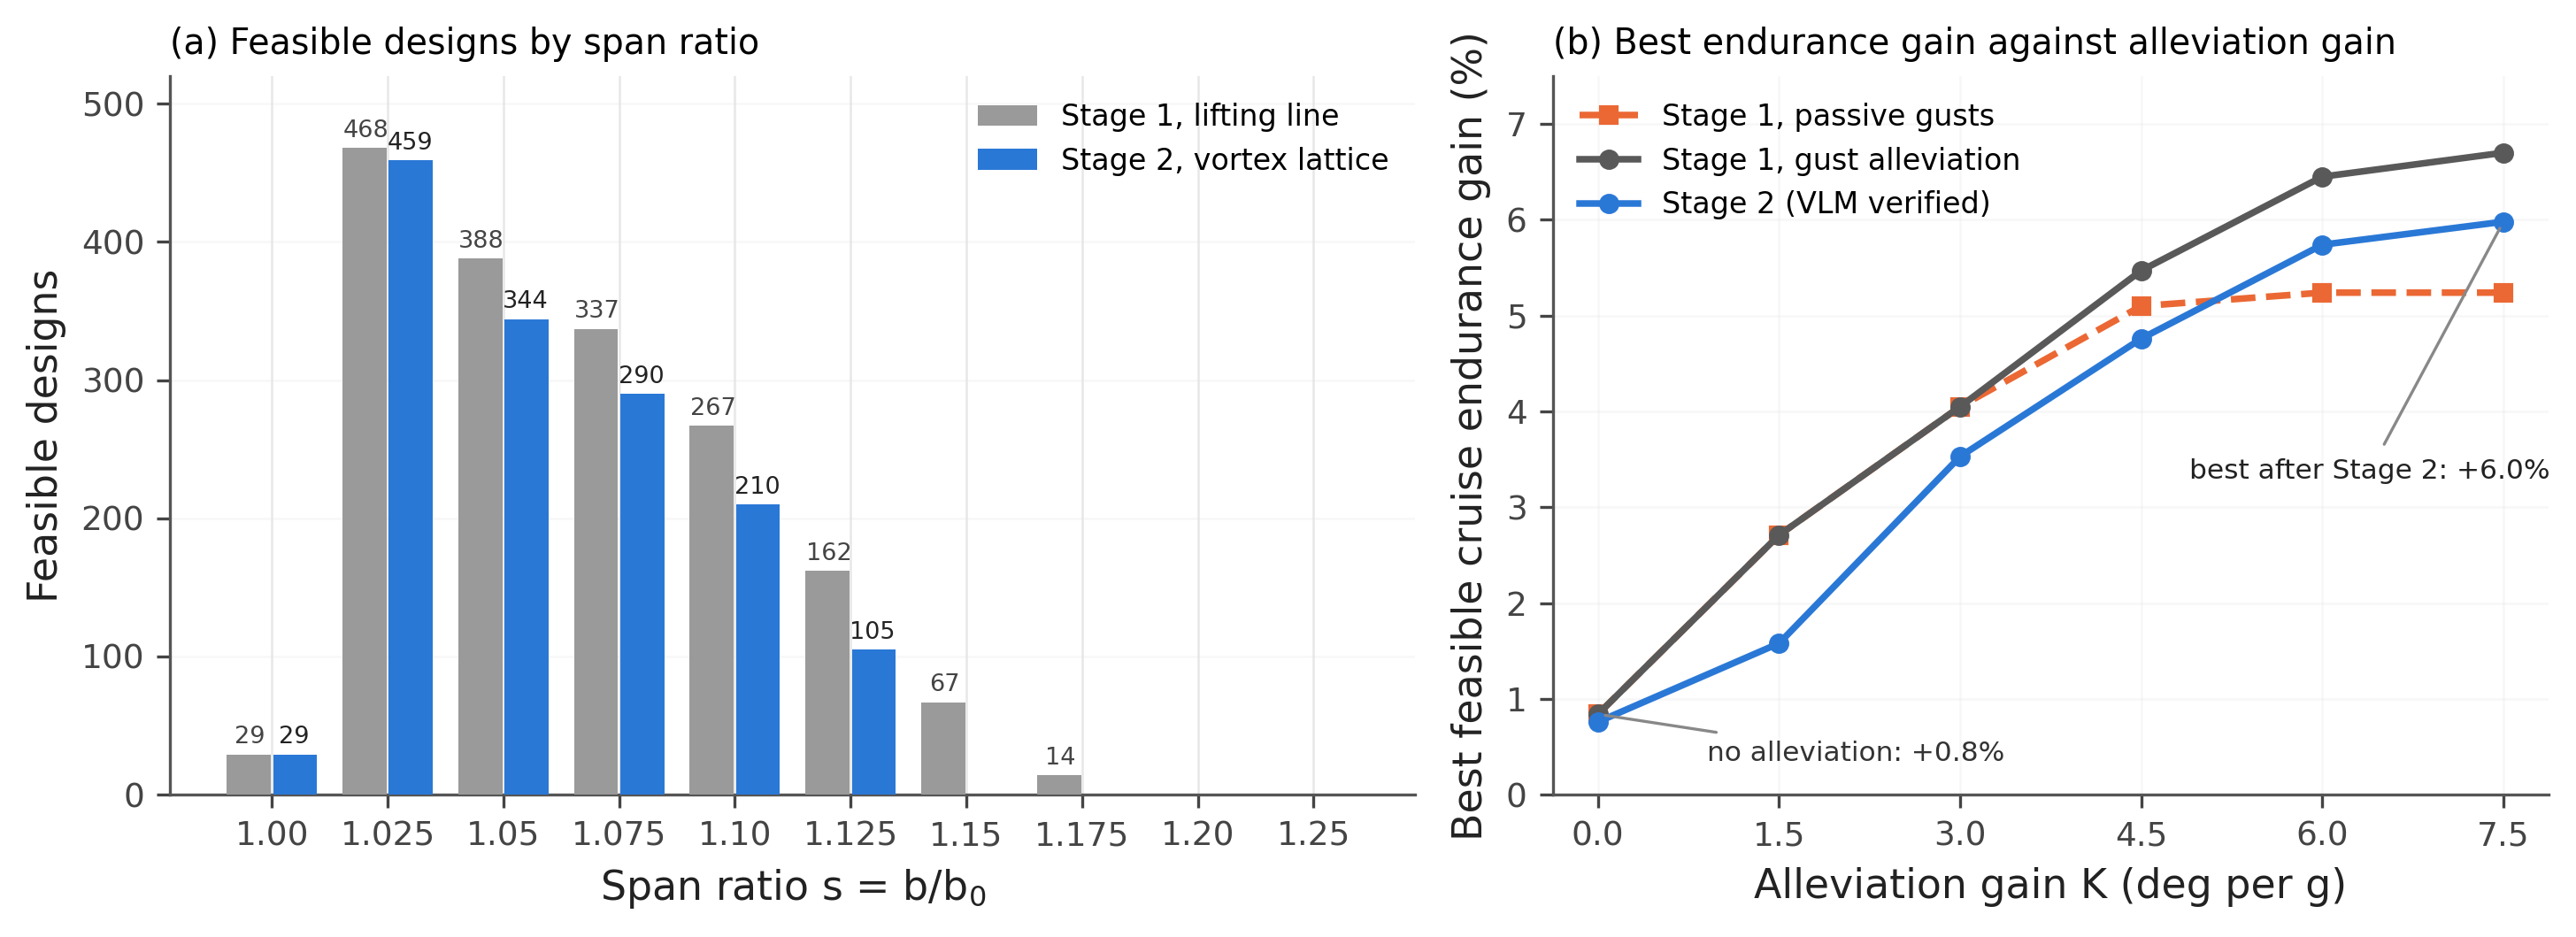

In [26]:
import matplotlib.pyplot as plt, numpy as np
plt.rcParams.update({'font.size':9,'axes.spines.top':False,'axes.spines.right':False,'axes.edgecolor':'#555','axes.labelcolor':'#222','xtick.color':'#444','ytick.color':'#444'})
GREY,BLUE,ORANGE='#595959','#2a78d6','#eb6834'
s=['1.00','1.025','1.05','1.075','1.10','1.125','1.15','1.175','1.20','1.25']
st1=[29,468,388,337,267,162,67,14,0,0]; st2=[29,459,344,290,210,105,0,0,0,0]
K=[0,1.5,3,4.5,6,7.5]
pas=[0.84,2.71,4.05,5.10,5.24,5.24]; gla=[0.84,2.71,4.05,5.47,6.45,6.70]; s2=[0.76,1.58,3.53,4.76,5.74,5.98]
fig,ax=plt.subplots(1,2,figsize=(10,3.6),dpi=300,gridspec_kw={'width_ratios':[1.25,1]})
x=np.arange(len(s)); w=0.38
ax[0].bar(x-w/2-0.01,st1,w,color='#9a9a9a',label='Stage 1, lifting line',zorder=3)
ax[0].bar(x+w/2+0.01,st2,w,color=BLUE,label='Stage 2, vortex lattice',zorder=3)
for i,(a,b) in enumerate(zip(st1,st2)):
    if a>0: ax[0].text(i-w/2,a+8,str(a),ha='center',fontsize=6.5,color='#444')
    if b>0: ax[0].text(i+w/2,b+8,str(b),ha='center',fontsize=6.5,color='#222')
ax[0].set_xticks(x); ax[0].set_xticklabels(s); ax[0].set_xlabel('Span ratio s = b/b$_0$')
ax[0].set_ylabel('Feasible designs'); ax[0].set_ylim(0,520)
ax[0].grid(axis='y',color='#e6e6e6',zorder=0); ax[0].legend(frameon=False,fontsize=8,loc='upper right')
ax[0].set_title('(a) Feasible designs by span ratio',loc='left',fontsize=9.5)
for y,lab,c,m,ls in [(pas,'Stage 1, passive gusts',ORANGE,'s','--'),(gla,'Stage 1, gust alleviation',GREY,'o','-'),(s2,'Stage 2 (VLM verified)',BLUE,'o','-')]:
    ax[1].plot(K,y,ls,color=c,marker=m,ms=4.5,lw=1.8,label=lab,zorder=3)
ax[1].annotate('no alleviation: +0.8%',(0,0.84),(0.9,0.35),fontsize=7.5,color='#333',arrowprops=dict(arrowstyle='-',color='#888',lw=0.8))
ax[1].annotate('best after Stage 2: +6.0%',(7.5,5.98),(4.9,3.3),fontsize=7.5,color='#222',arrowprops=dict(arrowstyle='-',color='#888',lw=0.8))
ax[1].set_xlabel('Alleviation gain K (deg per g)'); ax[1].set_ylabel('Best feasible cruise endurance gain (%)')
ax[1].set_xticks(K); ax[1].set_ylim(0,7.5); ax[1].grid(color='#e6e6e6',zorder=0); ax[1].legend(frameon=False,fontsize=8,loc='upper left')
ax[1].set_title('(b) Best endurance gain against alleviation gain',loc='left',fontsize=9.5)
fig.tight_layout(); fig.savefig('fig_design_drivers.png',facecolor='white')

## 25. Paper figure: three-stage method diagram

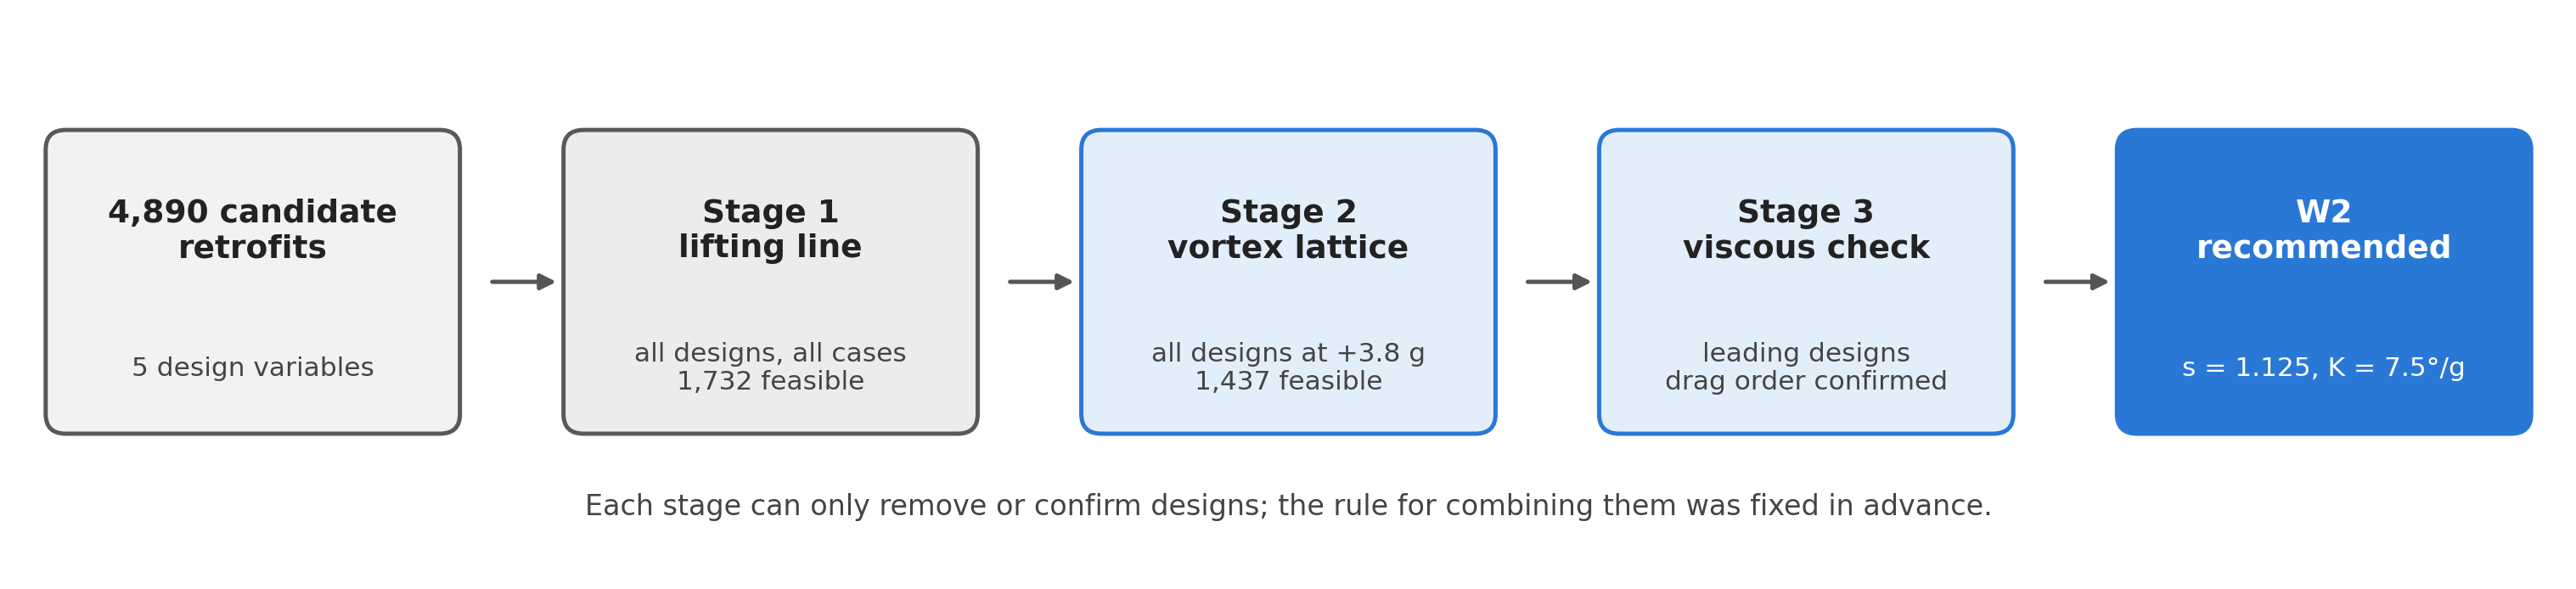

In [27]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
fig,ax=plt.subplots(figsize=(10,2.2),dpi=300); ax.set_xlim(0,10); ax.set_ylim(0,2.2); ax.axis('off')
boxes=[(0.1,'4,890 candidate\nretrofits','5 design variables','#f2f2f2','#595959'),
 (2.15,'Stage 1\nlifting line','all designs, all cases\n1,732 feasible','#ececec','#595959'),
 (4.2,'Stage 2\nvortex lattice','all designs at +3.8 g\n1,437 feasible','#e3eefb','#2a78d6'),
 (6.25,'Stage 3\nviscous check','leading designs\ndrag order confirmed','#e3eefb','#2a78d6'),
 (8.3,'W2\nrecommended','s = 1.125, K = 7.5°/g','#2a78d6','#2a78d6')]
for i,(x,t,sub,fc,ec) in enumerate(boxes):
    ax.add_patch(FancyBboxPatch((x,0.55),1.6,1.2,boxstyle='round,pad=0.02,rounding_size=0.08',fc=fc,ec=ec,lw=1.2))
    col='white' if i==4 else '#222'
    ax.text(x+0.8,1.36,t,ha='center',va='center',fontsize=9,weight='bold',color=col)
    ax.text(x+0.8,0.8,sub,ha='center',va='center',fontsize=7.5,color=col if i==4 else '#444')
    if i<4: ax.annotate('',(x+2.03,1.15),(x+1.72,1.15),arrowprops=dict(arrowstyle='-|>',color='#555',lw=1.2))
ax.text(5,0.2,'Each stage can only remove or confirm designs; the rule for combining them was fixed in advance.',ha='center',fontsize=8,color='#444')
fig.savefig('fig_flow.png',facecolor='white',bbox_inches='tight')

## 26. Paper figure: Wing-tip extension top-view diagram

/tmp/ipykernel_16/2253483685.py:63: UserWarning: The figure layout has changed to tight
  fig.tight_layout(h_pad=0.4); fig.savefig('fig_planform_real_vs_model.png',facecolor='white')


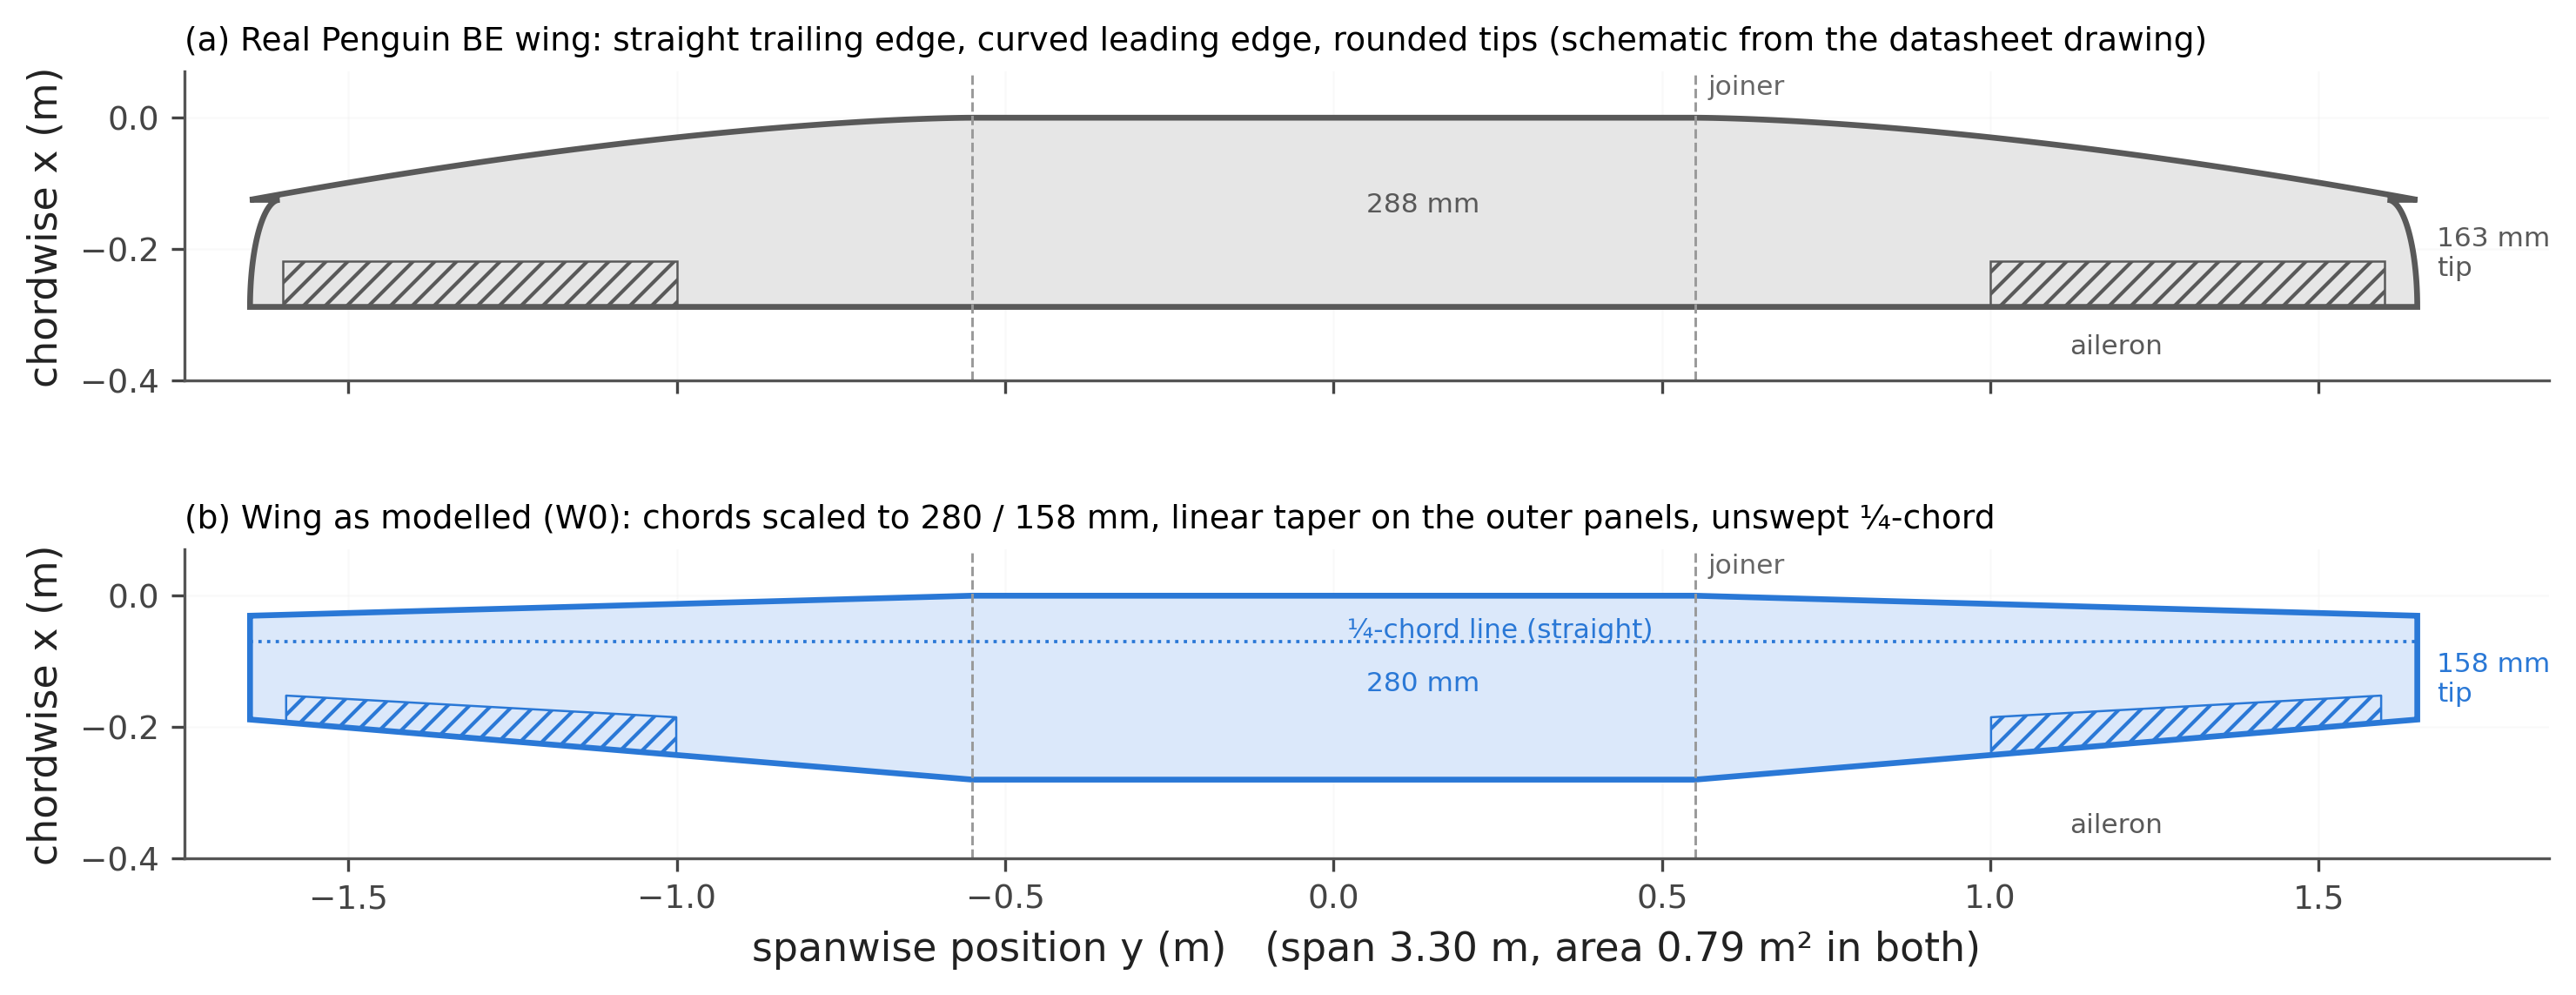

In [28]:
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({'font.size':9,'axes.spines.top':False,'axes.spines.right':False})
GREY,BLUE='#595959','#2a78d6'
half=1.65; yj=0.55
fig,ax=plt.subplots(2,1,figsize=(10,4.3),dpi=300,sharex=True)

# --- (a) real wing, schematic from datasheet drawing (unscaled: 288 / 163 mm) ---
cr,ct=0.288,0.163
def real_half(sign):
    eta=np.linspace(0,1,120)
    y_out=yj+eta*(half-yj)
    c=cr-(cr-ct)*eta**1.6            # curved leading edge, chord falls faster near the tip
    te=-cr*np.ones_like(eta)          # straight trailing edge, in line with centre section
    le=te+c
    # rounded tip: quarter-ellipse joining LE to TE
    th=np.linspace(0,np.pi/2,40); rx=0.045; ry=ct
    tip_y=half-rx+rx*np.sin(th); tip_x=te[-1]+ry*np.cos(th)
    ys=np.r_[0,yj,y_out[:-1],tip_y,half,y_out[::-1],yj,0]
    xs=np.r_[0,0,le[:-1],tip_x,-cr,te[::-1],-cr,-cr]
    ys[(ys>half-rx)&(xs>te[-1]+1e-9)]=np.minimum(ys[(ys>half-rx)&(xs>te[-1]+1e-9)],half)
    return sign*ys,xs
yR,xR=real_half(1); yL,xL=real_half(-1)
# right half: from root LE out along LE, tip, back along TE to root; left half mirrored
k=np.argmax(yR)                     # not used, outline built explicitly below
eta=np.linspace(0,1,120); yo=yj+eta*(half-yj); c=cr-(cr-ct)*eta**1.6; le=-cr+c
th=np.linspace(0,np.pi/2,40); rx=0.045
tipy=(half-rx)+rx*np.sin(th); tipx=-cr+ct*np.cos(th)
Ry=np.r_[0,yo,tipy]; Rx=np.r_[0,le,tipx]
Y=np.r_[-Ry[::-1],Ry,half,-half]; X=np.r_[Rx[::-1],Rx,-cr,-cr]
Y=np.r_[-Ry[::-1],Ry[1:],[half],[-half]]; X=np.r_[Rx[::-1],Rx[1:],[-cr],[-cr]]
ax[0].fill(Y,X,color='#e6e6e6',ec=GREY,lw=1.6)
for s in (1,-1):
    # ailerons along the straight trailing edge
    ax[0].fill([s*1.0,s*1.6,s*1.6,s*1.0],[-cr,-cr,-cr+0.07,-cr+0.07],hatch='////',fc='none',ec=GREY,lw=0.6)
ax[0].set_title('(a) Real Penguin BE wing: straight trailing edge, curved leading edge, rounded tips (schematic from the datasheet drawing)',loc='left',fontsize=9)

# --- (b) model original wing W0: scaled chords, linear taper, unswept quarter-chord ---
cr2,ct2=0.280,0.158
y=np.linspace(-half,half,601); a=np.abs(y)
c=np.where(a<=yj,cr2,cr2+(ct2-cr2)*(a-yj)/(half-yj))
qc=-0.25*cr2      # quarter-chord line held straight (unswept)
le=qc+0.25*c; te=qc-0.75*c
ax[1].fill(np.r_[y,y[::-1]],np.r_[le,te[::-1]],color='#dbe8fa',ec=BLUE,lw=1.6)
ax[1].plot(y,np.full_like(y,qc),':',color=BLUE,lw=0.9)
ax[1].text(0.02,qc+0.006,'¼-chord line (straight)',fontsize=7.5,color=BLUE)
for s in (1,-1):
    m=(a>=1.0)&(a<=1.6)&(np.sign(y)==s)
    ax[1].fill_between(y[m],te[m],te[m]+0.25*c[m],hatch='////',fc='none',ec=BLUE,lw=0.6)
ax[1].set_title('(b) Wing as modelled (W0): chords scaled to 280 / 158 mm, linear taper on the outer panels, unswept ¼-chord',loc='left',fontsize=9)

for k in (0,1):
    for s in (1,-1): ax[k].axvline(s*yj,color='0.6',lw=0.7,ls='--')
    ax[k].text(yj+0.02,0.035,'joiner',fontsize=7.5,color='0.4')
    ax[k].text(1.12,-0.36,'aileron',fontsize=7.5,color='0.35')
    ax[k].set_ylim(-0.40,0.07); ax[k].set_aspect('equal'); ax[k].set_ylabel('chordwise x (m)')
    ax[k].grid(color='#eeeeee',lw=0.6)
ax[0].annotate('288 mm',(0.05,-0.144),fontsize=7.5,color=GREY)
ax[0].annotate('163 mm\ntip',(1.68,-0.24),fontsize=7.5,color=GREY)
ax[1].annotate('280 mm',(0.05,-0.144),fontsize=7.5,color=BLUE)
ax[1].annotate('158 mm\ntip',(1.68,-0.16),fontsize=7.5,color=BLUE)
ax[1].set_xlabel('spanwise position y (m)   (span 3.30 m, area 0.79 m² in both)')
ax[1].set_xlim(-1.75,1.85)
fig.tight_layout(h_pad=0.4); fig.savefig('fig_planform_real_vs_model.png',facecolor='white')